# RQ1 — Organization co-occurrence network (Network Topology / Centrality)

**Question.** How are organizations positioned relative to each other in the post-9/11 records archive?
**Hypothesis 1 (as stated by the team, tested — not assumed).** Municipal regulatory agencies and private real-estate entities have higher degree and betweenness centrality than public-health advocacy groups.

**What an edge means here.** Two organizations are linked when both are *named on the same page*. That is co-occurrence in the archive — not proof of communication, collaboration, influence or power.

**Data.** NYC 9/11 document archive (<https://911records.org>; original PDFs on the City portal `sept11documents.cityofnewyork.us`), scraped by the team into `data/final/*.parquet` in <https://github.com/dapivei/nyc-911-records-analysis>.

**Workflow.** Pandas: clean and build edges → NetworkX: degree and betweenness → descriptive group comparison → frequency check → sensitivity checks (without multi-organization pages; study window only; hand-confirmed real-estate entities only) → **beyond frequency** (frequency-preserving null models, hyperbolic weights, validated backbone, network without DEP's files, document bootstrap, monthly networks, communities) → Matplotlib figures → independent verification.

**Prerequisites**
* Python ≥ 3.11 with `pandas`, `pyarrow`, `networkx`, `scipy` (used by the network layout), `matplotlib` (tested: Anaconda, Python 3.14, pandas 3.0, networkx 3.6).
* `data/processed/` exists: run `python -m src.processing.clean` from the repo root (needs the real `data/final/*.parquet`, i.e. `git lfs pull`).
* Run `python -m src.analysis.network.run` once first (≈ 25 minutes on 2 cores the first time: it writes the tables and figures used below and caches the null-model, bootstrap and monthly samples in `outputs/network/`). The notebook then runs top to bottom in ≈ 3 minutes. Without the caches, section 6 computes them itself.

In [1]:
import os, json
from pathlib import Path
if Path.cwd().name == "notebooks":          # run from the repo root so `src` and `data/` resolve
    os.chdir(Path.cwd().parent)
import pandas as pd, numpy as np
from IPython.display import Image, display
from src.analysis.network import build, checks, classify, figures, metrics, pipeline, robustness, settings, verify
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70); pd.set_option("display.max_columns", 30)
assert (settings.PROCESSED / "entity_mentions.parquet").exists(), "run `python -m src.processing.clean` first"
print("working dir:", Path.cwd())

working dir: nyc-911-records-analysis


## 1. Data checks
Tables (all from `data/processed/`): `entity_mentions` (entity → doc_id, page) joins `pages` on `(doc_id, page)` and `documents` on `doc_id`; `entities` gives names and the cleaned `entity_id`.

In [2]:
prep = pipeline.prepare(with_advocacy=True, keep_text=True)
t = prep.tables
{k: v.shape for k, v in t.items()}

{'documents': (64541, 11),
 'pages': (230315, 6),
 'entities': (15915, 12),
 'entity_mentions': (649168, 6)}

In [3]:
checks.key_checks(t)

,check,count
0,documents: duplicate doc_id,0
1,"pages: duplicate (doc_id, page)",0
2,"entities: duplicate (source_type, slug)",0
3,"entity_mentions: duplicate (source_type, slug, doc_id, page)",0
4,"entity_mentions: duplicate (entity_type, entity_id, doc_id, page) ...",9475
5,entity_mentions: missing entity_id,0
6,entity_mentions: doc_id not in documents,0
7,"entity_mentions: (doc_id, page) not in pages",0
8,entity_id values shared by >1 entity_type,109


* Keys are clean and every mention joins to a document and a page.
* After `clean.py` merges name variants into one `entity_id`, 9,475 mention rows repeat a (type, id, doc, page) — so mentions are **deduplicated per node and page** before pairs are formed.
* 109 `entity_id`s are shared across entity types (mostly contractor/lab, some contractor/signatory), so a node key must include the type: here `agency:<id>` / `company:<id>` (contractor and lab with the same normalised name = one company).

In [4]:
checks.entity_type_overview(t)

,entity_type,entity_ids,mention_pages,docs,in_network
0,address,6306,67864,12162,False
1,agency,30,90746,17547,True
2,contractor,5897,40241,9822,True
3,lab,1121,24142,4620,True
4,signatory,1658,4591,2658,False
5,substance,53,412109,47932,False


**What the entity types are** (inspected by hand, notebook author's reading):
* `agency` — 30 organizations after the team's hand map (`src/processing/agency_map.py`), with a level (city / state / federal / regional / private / nonprofit). Most reliable.
* `contractor`, `lab` — machine-extracted company names. Includes real companies (ATC Associates, Silverstein Properties) but also many fragments ("Services Inc.", "Final Laboratory", "Acting Corp.").
* `signatory` — people and role labels ("Official signatory", "approved-by"): **excluded** (not organizations).
* `address`, `building`, `substance` — not organizations: **excluded**.

In [5]:
dates = checks.date_coverage(prep.om, t["documents"])
print(json.dumps(dates, indent=1, default=str))

{
 "docs_with_org": 18998,
 "docs_dated": 16623,
 "share_dated_of_all": 0.8749868407200758,
 "docs_in_study_window": 14121,
 "share_in_window_of_all": 0.7432887672386567,
 "share_in_window_of_dated": 0.8494856524093124,
 "docs_before_2001_09_11": 2493,
 "docs_1997_2000": 1969,
 "docs_before_1997": 127,
 "docs_after_2009": 9,
 "share_2001_2002_of_dated": 0.7866811044937737,
 "doc_date_min": "1908-05-28 00:00:00",
 "doc_date_max": "2013-11-01 00:00:00",
 "date_precision_counts": {
  "day": 13262,
  "month": 2720,
  "NaN": 2375,
  "year": 641
 },
 "date_fix_counts": {
  "raw date matching title": 9440,
  "title date (no raw date)": 3034,
  "raw date (no title date)": 2724,
  "no date": 2375,
  "raw date (conflicts with title)": 1001,
  "title date (raw date implausible)": 424
 }
}


**Date coverage (denominators stated).** Of the 18,998 documents that name a kept organization, 16,623 (87.5%) have a `doc_date`. 14,121 fall in the study window 2001-09-11 to 2009-12-31: 74.3% of all 18,998, or 85.0% of the dated ones. 78.7% of dated documents are from 2001–2002. **2,493 dated documents (15.0%) are from before 11 September 2001** — mostly 1997–2000 (1,969), plus 127 before 1997 and 9 after 2009 (latest 2013). 641 dates are year-only and 2,720 month-only.

In [6]:
# extreme dates, for manual review: is the date the document's own, or a parse / OCR error?
checks.date_extremes(prep.om, t["documents"])[["end", "doc_id", "doc_date", "date_fix", "title", "doc_date_raw", "box"]]

,end,doc_id,doc_date,date_fix,title,doc_date_raw,box
0,earliest,NYC-WTC_000167646,1908-05-28,raw date (no title date),"Memo to commence reconstruction at 7 WTC for MOEM, May","May 28, 1908",7DCAS
1,earliest,NYC-WTC_000167680,1908-05-28,raw date (conflicts with title),"Contract registration cover sheet, July 1995","May 28, 1908",7DCAS
2,earliest,NYC-WTC_000165482,1982-03-09,raw date (no title date),"Organizational advisory board listing, March 1982","March 9, 1982 1 TO: MA.GDI FARAG, P.E., CHIEF, ENGINEERING REVIEW ...",DEP Box 44
3,earliest,NYC-WTC_000165835,1983-11-23,raw date (no title date),"Internal sewer capacity memo, 10th Ave Tunnel, Nov 1983","November 23, 1983",DEP Box 44
4,earliest,NYC-WTC_000165265,1985-03-01,title date (no raw date),"DEP memo on Lincoln Tunnel bridge repair drawings, March 1985",NaN,DEP Box 44
5,earliest,NYC-WTC_000165038,1985-04-01,title date (no raw date),"PVC drainage connection approval memo, Apr 1985",NaN,DEP Box 44
6,earliest,NYC-WTC_000165035,1985-04-01,raw date matching title,"Convention center drainage connection approval, Apr 1985","April 1, 1985",DEP Box 44
7,earliest,NYC-WTC_000165316,1986-01-01,title date (no raw date),"Letter with comments on WTC tunnel drawings, January 1986",NaN,DEP Box 44
8,earliest,NYC-WTC_000165756,1986-08-01,title date (no raw date),"Telephone conversation memo, Aug 1986",NaN,DEP Box 44
9,earliest,NYC-WTC_000165753,1986-08-01,title date (no raw date),"Telephone conversation memorandum, Parsons Brinckerhoff, Aug 1986",NaN,DEP Box 44


**Extreme dates, checked by hand.**
* **Stored range: 1908-05-28 to 2013-11-01** (the `doc_date` values from `src/processing`, not changed here). Excluding the two suspected errors below, the range is 1982–2013.
* The two **1908** documents are **suspected date errors** (manual judgement): the same Office of Contracts cover sheet addressed to "7 World Trade Company, L.P." (box 7DCAS), with "DATE: May 28, 1908" in the extracted page text; one of the two titles says July 1995. The original PDFs were not checked, so we do not know whether "1908" is printed or comes from text extraction, and no corrected date is assumed. The cleaning rules keep a raw date unless it is missing, on or before 9/11 for a post-9/11 title, or more than a year after the title, so these were kept.
* The other 8 of the 10 earliest (1982–1986) are sewer, drainage and tunnel memos from DEP Box 44. Their titles give the same month and year, so they look like genuine older material. The remaining 117 pre-1997 documents were not checked one by one.
* The latest (2011–2013) are asbestos lab reports, chain-of-custody forms and a subpoena receipt, with dates from or matching the title: plausible.
* The 18,998 documents fall into four non-overlapping periods: 14,121 study window, 2,493 before 11 September 2001, 9 after 2009, 2,375 undated.
* **The main network is not filtered by date.** It pools every document, dated or not, so it describes the released archive, not only the post-9/11 response period. Section 3 shows how much of its pair evidence comes from each period; section 5 rebuilds the network from study-window documents only.

In [7]:
checks.source_bias(prep.om, t["documents"]).head(8)

,agency,docs,share
0,"Environmental Protection, Dept. of",11830,0.622697
1,"Education, Dept. of",2916,0.153490
2,"Citywide Administrative Services, Dept. of",2145,0.112907
3,"Design and Construction, Dept. of",863,0.045426
4,"Health and Mental Hygiene, Dept. of",293,0.015423
5,Law Department,271,0.014265
6,Fire Department,166,0.008738
7,School Construction Authority,138,0.007264


**Archive bias.** ~62% of the documents that name any organization come from DEP's own files. Any DEP-centred structure partly reflects *whose files were released*, not only who was central.

In [8]:
checks.unit_size_distribution(prep.om)

,unit,units_with_org,units_with_2plus,median_orgs,p90,p99,p99_of_2plus,max,pairs_total,share_pairs_from_top1pct_units
0,page,71165,30558,1.0,3.0,5.0,7.0,23,99758,0.258435
1,doc,18998,13310,2.0,5.0,12.0,14.0,312,236361,0.702028


**Choice of co-occurrence unit.** At the *document* level, the top 1% largest documents generate ~70% of all organization pairs (one document names 312 organizations). At the *page* level the median page names 1 organization, p99 of multi-organization pages is 7, and the top 1% produce ~26% of pairs. → **Page co-occurrence is the main analysis**; document co-occurrence is kept only as a comparison.

In [9]:
checks.largest_units(prep.om, t["documents"], "page", 12)[["doc_id", "page", "n_orgs", "title"]]

,doc_id,page,n_orgs,title
0,NYC-WTC_000162145,7,23,"List of WTC-affected buildings with ownership information, April 2002"
1,NYC-WTC_000156544,5,23,"DEP inspection form header, Apr 23 2002"
2,NYC-WTC_000162145,9,23,"List of WTC-affected buildings with ownership information, April 2002"
3,NYC-WTC_000162145,11,23,"List of WTC-affected buildings with ownership information, April 2002"
4,NYC-WTC_000135642,5,22,Exterior CleanUp License survey list for Barclay Street
5,NYC-WTC_000162145,10,21,"List of WTC-affected buildings with ownership information, April 2002"
6,NYC-WTC_000135642,7,21,Exterior CleanUp License survey list for Barclay Street
7,NYC-WTC_000156592,10,21,"WTC environmental records page, undated"
8,NYC-WTC_000156544,4,21,"DEP inspection form header, Apr 23 2002"
9,NYC-WTC_000156347,2,21,"DEP Bureau of [name] document header, BUILDINGS LISTS folder"


The largest pages are a mix: building / property lists, DEP inspection-form headers and at least one letter (Law Department, row 11). A page that names many organizations creates many edges at once whatever its type, so the sensitivity check below drops **multi-organization pages** (more than 7 organizations, the p99 of pages with ≥ 2). This is a rule about page *size*; it does not classify document types.

### 1b. Manual spot check against the page text
Five random pages with 2–4 organizations (seeded) plus the largest page; the names listed should be visible in the text.

In [10]:
pages_idx = t["pages"].set_index(["doc_id", "page"])
names = prep.node_info.set_index("node_id")["name"]
sizes = build.unit_sizes(prep.om, "page")
sample = list(sizes[(sizes >= 2) & (sizes <= 4)].sample(5, random_state=settings.SEED).index) + [sizes.idxmax()]
for doc, page in sample:
    ids = prep.om.query("doc_id == @doc and page == @page")["node_id"]
    txt = " ".join(str(pages_idx.loc[(doc, page), "text"]).split())
    print(f"--- {doc} p.{page} | {t['documents'].set_index('doc_id').loc[doc, 'title']}")
    print("    orgs:", "; ".join(names[i] for i in ids))
    print("    text:", txt[:400], "...\n")

--- NYC-WTC_000104027 p.211 | Ambient air sampling report for 105 Duane Street, Feb 2002
    orgs: U.S. EPA; Atc Associates Inc.; Atc Environmental Inc.
    text: IJ ATC Environmental, Inc. 104 East 25th Street New York, New York 10010 ATC Associates Inc. 104 East 25th Street New York, NY 10010 Approved N.Y. State ELAP #10879 ACCREDITED NVLAP Lab Code # 1187 Report Date: 10/26/01 ASBESTOS FIBER ANALYSIS BY TRANSMISSION ELECTRON MICROSCOPY (TEM) With Fiber Identification by Selected-Area Electron Diffraction (SAED) and Energy-Dispersive X-RAY Spectroscopy (E ...

--- NYC-WTC_000199010 p.2 | IAQ Report Cover Letter, PS89M, May 2002
    orgs: U.S. EPA; Air-conditioning Engineers
    text: Mr. Bernard P. Orlan May 9, 2002 Indoor Air Quality Assessment Page 2 P. S. 89M ATC Project No. 15-19125-0297 presented in this report should be used by the BOE as a guide to assess the need for further improvements in current indoor air quality control activities. EVALUATION CRITERIA Currently, there ar

## 2. Nodes, merges, exclusions and classification
Rules (`src/analysis/network/classify.py`, `settings.py`), all fixed before metrics were computed:
1. **Merges** of OCR / prefix variants clean.py left apart (`COMPANY_MERGES`, each listed with a reason), e.g. "Landlord Silverstein Properties" → Silverstein Properties. Candidates were found by the rule *id = 1–2 token prefix + another id*, then checked by eye; the automatic rule alone would mis-merge (e.g. "PSC Analytical Services" → "Analytical Services").
2. **Artifacts** — job titles / phrases (`ARTIFACT_IDS`) and names with no distinctive word (`is_generic_name`).
3. **Support** — a company must appear in ≥ 2 documents (`MIN_NODE_DOCS`).
4. **Groups** — agencies from the team's agency map plus an a-priori list of municipal *regulators* (DEP, DOHMH, DOB, HPD); companies by manual entries (`MANUAL_GROUPS`, with basis) or conservative keywords; everything else `other_unknown`.

In [11]:
prep.candidates["excluded_reason"].fillna("KEPT").str.split(":").str[0].value_counts()

excluded_reason
support                               4928
KEPT                                  1652
generic name (no distinctive word)     332
artifact                                24
Name: count, dtype: int64

In [12]:
prep.candidates[prep.candidates.excluded_reason.notna()].head(15)[["node_id", "name", "n_docs", "excluded_reason"]]

,node_id,name,n_docs,excluded_reason
16,company:environmental-laboratory,Environmental Laboratory,550,generic name (no distinctive word)
20,company:acting,Acting Corp.,461,artifact: word 'Acting' + Corp.
30,company:sample-analysis-laboratory,Sample Analysis Laboratory,285,generic name (no distinctive word)
39,company:accredited-laboratory,Accredited Laboratory,207,generic name (no distinctive word)
42,company:health-environmental-laboratory,Health Environmental Laboratory,193,generic name (no distinctive word)
44,company:final-laboratory,Final Laboratory,186,generic name (no distinctive word)
46,company:distribution-laboratory,Distribution Laboratory,150,generic name (no distinctive word)
50,company:national-voluntary-laboratory,National Voluntary Laboratory,143,"artifact: NVLAP accreditation program name, not a lab"
51,company:nvlap-laboratory,Nvlap Laboratory,139,"artifact: NVLAP accreditation program name, not a lab"
52,company:new-york-laboratory,New York Laboratory,128,generic name (no distinctive word)


In [13]:
cls = prep.node_info
pd.crosstab(cls["group"], cls["review_status"], margins=True)

review_status,curated (agency_map.py + a-priori regulator list),manual,manual (uncertain),rule (unreviewed),unclassified,All
group,,,,,,
city_other,10,3,0,0,0,13
consultant_contractor_lab,0,6,1,578,0,585
municipal_regulatory,4,0,0,0,0,4
nonprofit_relief,2,0,0,0,0,2
other_unknown,0,5,0,0,904,909
private_real_estate,0,10,10,99,0,119
private_utility,2,0,0,0,0,2
public_health_advocacy,0,4,0,0,0,4
state_federal_regional,12,5,1,0,0,18


In [14]:
cls.query("group == 'private_real_estate'").nlargest(20, "n_docs")[["entity_id", "name", "n_docs", "basis", "review_status"]]

,entity_id,name,n_docs,basis,review_status
13,silverstein-properties,Silverstein Properties Inc.,790,WTC site leaseholder / 7 WTC developer,manual
24,rockrose-development,Rockrose Development Corp.,345,residential developer & landlord (Lower Manhattan),manual
59,duane-street-associates,Duane Street Associates,44,building-owning partnership named for its street,manual (uncertain)
65,century-realty,Century Realty Inc.,38,'Realty' in name,manual
66,maiden-lane-associates,Maiden Lane Associates LLC,38,building-owning partnership named for its street,manual (uncertain)
68,gateway-plaza-management,Gateway Plaza Management Corp.,35,manager of Gateway Plaza residential complex (BPC),manual
70,newmark-and,Newmark And Co.,34,Newmark & Co. Real Estate (see newmark-and-real-estate),manual (uncertain)
75,broadway-associates,Broadway Associates,31,building-owning partnership named for its street,manual (uncertain)
93,financial-district-associates,Financial District Associates LLC,24,building-owning partnership,manual (uncertain)
96,cushman-and-wakefield,Cushman And Wakefield Inc.,23,commercial real estate services firm,manual


**Public-health advocacy groups do not exist among the extracted entities.** The agency map's only nonprofits are the Red Cross and the Salvation Army (relief organizations), and no contractor/lab name is an advocacy group. A text search shows the archive *does* name some of them, rarely. For an **exploratory supplement**, four organizations are detected by a fixed name list (`build.ADVOCACY_PATTERNS`). Sierra Club and "Beyond Ground Zero" were dropped after a precision check (all hits unrelated), before any metric was computed.

In [15]:
build.advocacy_nodes(prep.adv)[["node_id", "name", "n_pages", "n_docs"]]

,node_id,name,n_pages,n_docs
0,advocacy:911-environmental-action,9/11 Environmental Action,23,14
1,advocacy:american-lung-association,American Lung Association,20,16
2,advocacy:nrdc,Natural Resources Defense Council,33,21
3,advocacy:nycosh,NYCOSH (NY Committee for Occupational Safety & Health),57,33


## 3. Main network: page co-occurrence among extracted organizations
* undirected (no reliable sender/recipient fields); each page contributes each pair once
* weight = number of distinct pages shared (used for strength and in fig 4)
* every edge is traceable: `outputs/network/edge_evidence_main.parquet` lists (source, target, doc_id, page)
* no self-loops (pairs require source < target); isolates are kept as nodes

In [16]:
main = pipeline.build_network(prep, unit="page")
sup = pipeline.build_network(prep, unit="page", include_advocacy=True)
doc = pipeline.build_network(prep, unit="doc")
stats = pd.DataFrame({"page (main)": main["stats"], "page + advocacy": sup["stats"], "document": doc["stats"]})
print("betweenness:", main["betweenness_info"])
stats

betweenness: {'method': 'exact (Brandes)', 'nodes': 1652, 'edges': 11166, 'seconds': 6.65}


,page (main),page + advocacy,document
nodes,1652.000000,1656.000000,1652.000000
edges,11166.000000,11227.000000,92848.000000
density,0.008188,0.008193,0.068084
components,109.000000,109.000000,19.000000
largest_component_nodes,1500.000000,1504.000000,1628.000000
largest_component_share,0.907990,0.908213,0.985472
isolates,91.000000,91.000000,16.000000
degree_mean,13.518160,13.559179,112.406780
degree_median,5.000000,5.000000,24.000000
degree_max,738.000000,742.000000,1222.000000


Betweenness is **exact** (Brandes algorithm in networkx, cost ≈ O(nodes × edges)): ~1,650 nodes and ~11,000 edges take a few seconds, so no sampling is needed. Degree and betweenness ignore edge weights.

In [17]:
cols = ["name", "group", "n_pages", "n_docs", "degree", "degree_centrality", "strength", "betweenness"]
main["nodes"].nlargest(20, "degree_centrality")[cols]

,name,group,n_pages,n_docs,degree,degree_centrality,strength,betweenness
0,NYC Dept. of Environmental Protection,municipal_regulatory,26158,7759,738,0.447002,21089.0,0.319309
1,U.S. EPA,state_federal_regional,24138,7434,487,0.294973,25911.0,0.167431
2,NYC Dept. of Health and Mental Hygiene,municipal_regulatory,7862,4387,348,0.210781,14397.0,0.072463
5,NIOSH,state_federal_regional,6239,2076,235,0.142338,9729.0,0.062456
8,NYC Dept. of Buildings,municipal_regulatory,2615,1551,221,0.133858,2892.0,0.034792
4,OSHA,state_federal_regional,5254,2084,217,0.131435,8170.0,0.044872
65,Century Realty Inc.,private_real_estate,68,38,180,0.109025,627.0,0.007895
7,NYC Board of Education,city_other,2341,1600,175,0.105996,5348.0,0.018631
16,FDNY,city_other,988,489,173,0.104785,2095.0,0.024432
122,American Stock Exchange Inc.,other_unknown,37,20,156,0.094488,399.0,0.011951


In [18]:
main["nodes"].nlargest(15, "betweenness")[cols]

,name,group,n_pages,n_docs,degree,degree_centrality,strength,betweenness
0,NYC Dept. of Environmental Protection,municipal_regulatory,26158,7759,738,0.447002,21089.0,0.319309
1,U.S. EPA,state_federal_regional,24138,7434,487,0.294973,25911.0,0.167431
2,NYC Dept. of Health and Mental Hygiene,municipal_regulatory,7862,4387,348,0.210781,14397.0,0.072463
5,NIOSH,state_federal_regional,6239,2076,235,0.142338,9729.0,0.062456
4,OSHA,state_federal_regional,5254,2084,217,0.131435,8170.0,0.044872
11,NYC Office of the Mayor,city_other,1534,1043,114,0.069049,2098.0,0.038830
8,NYC Dept. of Buildings,municipal_regulatory,2615,1551,221,0.133858,2892.0,0.034792
6,NYC Office of Emergency Management,city_other,2699,1802,124,0.075106,4224.0,0.030652
22,Port Authority of NY & NJ,state_federal_regional,886,411,114,0.069049,1204.0,0.029551
16,FDNY,city_other,988,489,173,0.104785,2095.0,0.024432


**Are high ranks only frequency?** Compare how often an organization is named with its centrality (Spearman rank correlation, pandas `corr(method="spearman")`).

In [19]:
from src.analysis.network.run import frequency_check, multi_org_share
frequency_check(main["nodes"]).round(3)

,metric,spearman_with_n_pages,nodes
0,degree,0.437,1652
1,strength,0.640,1652
2,betweenness,0.562,1652


Degree is moderately correlated with frequency (ρ ≈ 0.44), betweenness more (ρ ≈ 0.56), strength most (ρ ≈ 0.64). The most central organizations are also the most named (DEP: 26,158 pages); with this correlation we **cannot separate "structurally important" from "recorded often"**.

Where does each group's pair evidence come from? Share of evidence rows from multi-organization pages (> 7 organizations):

In [20]:
cutoff = build.large_unit_cutoff(prep.om, "page")
multi_org_share(main, prep, cutoff).round(3)

,group,share,evidence_rows
1,consultant_contractor_lab,0.053,37940
7,state_federal_regional,0.059,57435
2,municipal_regulatory,0.070,39165
6,private_utility,0.172,780
0,city_other,0.180,21361
3,nonprofit_relief,0.260,592
5,private_real_estate,0.532,14277
4,other_unknown,0.604,27966


53% of the pair evidence behind real-estate nodes comes from multi-organization pages, vs 7% for municipal regulators.

In [21]:
# the network is not filtered by date: pair evidence by the period of its document
checks.evidence_by_period(main["evidence"], t["documents"]).round(3)

,period,pair_evidence_rows,share
0,study window,87875,0.881
1,undated,6029,0.060
2,before 2001-09-11,5831,0.058
3,after study window,23,0.000


88.1% of the pair evidence comes from documents in the study window, 5.8% from documents before 11 September 2001, 6.0% from undated documents and 0.02% from after 2009.

## 4. Hypothesis groups: descriptive comparison
**Percentiles are recomputed within each network.** A group's percentile can rise while its raw degree or betweenness falls (other nodes fell more), so raw values and ranks are shown next to the percentiles.

No significance test is reported: nodes of one network are not independent; the municipal-regulator and advocacy groups have 4 nodes each; and the advocacy nodes were found by a different method (text name list), so their recall is not comparable. A p-value would add false precision. Instead: every node's percentile rank, and group n / median / quartiles / min / max.

**Classification sensitivity.** 99 of the 119 real-estate nodes were assigned by a keyword rule and not checked one by one. The views below also show the **10 real-estate nodes confirmed by hand** (`review_status == "manual"`) and the 20 manual ones including 10 marked uncertain.

In [22]:
rob, summary, hyp_nodes, nets = robustness.run(prep)
scen = list(nets)
summary.pivot_table(index="view", columns=["metric", "scenario"], values="median", sort=False).round(1)

metric,pct_degree_centrality,pct_betweenness,pct_degree_centrality,pct_betweenness,pct_degree_centrality,pct_betweenness,pct_degree_centrality,pct_betweenness
scenario,baseline: page co-occurrence,baseline: page co-occurrence,"page, without multi-organization pages (> 7 orgs)","page, without multi-organization pages (> 7 orgs)",document co-occurrence,document co-occurrence,"page, study window only (2001-09-11 to 2009-12-31)","page, study window only (2001-09-11 to 2009-12-31)"
view,,,,,,,,
municipal regulatory,99.8,99.8,99.8,99.8,99.5,99.5,99.8,99.8
private real estate: all,83.6,72.9,50.8,34.5,81.2,68.1,83.8,74.2
"private real estate: manual, incl. uncertain",95.9,94.9,93.1,86.3,95.7,94.8,95.6,94.4
private real estate: manually confirmed,95.3,96.0,93.6,91.2,96.2,96.0,92.0,95.5
public-health advocacy (exploratory),78.3,76.4,94.0,84.5,60.2,66.8,81.8,78.8


In [23]:
# the two 4-node groups, node by node (baseline)
hyp_nodes.query("scenario == @scen[0] and view in ['municipal regulatory', 'public-health advocacy (exploratory)']")[
    ["view", "name", "n_pages", "degree", "betweenness", "rank_degree", "rank_betweenness",
     "pct_degree_centrality", "pct_betweenness"]].round(4)

,view,name,n_pages,degree,betweenness,rank_degree,rank_betweenness,pct_degree_centrality,pct_betweenness
0,municipal regulatory,NYC Dept. of Environmental Protection,26158,742,0.3193,1,1,100.0000,100.0000
1,municipal regulatory,NYC Dept. of Health and Mental Hygiene,7862,352,0.0725,3,3,99.8792,99.8792
2,municipal regulatory,NYC Dept. of Buildings,2615,221,0.0346,5,7,99.7585,99.6377
3,municipal regulatory,NYC Dept. of Housing Preservation and Development,302,45,0.0018,116,86,92.9952,94.8671
153,public-health advocacy (exploratory),9/11 Environmental Action,23,14,0.0003,395,251,75.9058,84.9034
154,public-health advocacy (exploratory),American Lung Association,20,14,0.0000,395,525,75.9058,68.3575
155,public-health advocacy (exploratory),Natural Resources Defense Council,33,18,0.0000,313,521,80.7367,68.5990
156,public-health advocacy (exploratory),NYCOSH (NY Committee for Occupational Safety & Health),57,18,0.0003,313,262,80.7367,84.2391


In [24]:
# the 10 hand-confirmed real-estate nodes are also frequently named: compare page counts
pd.concat([hyp_nodes.query("scenario == @scen[0]").groupby("view")["n_pages"].median().rename("median pages named"),
           hyp_nodes.query("scenario == @scen[0]").groupby("view").size().rename("n")], axis=1)

,median pages named,n
view,,
municipal regulatory,5238.5,4
private real estate: all,5.0,119
"private real estate: manual, incl. uncertain",51.5,20
private real estate: manually confirmed,72.5,10
public-health advocacy (exploratory),28.0,4


## 5. Sensitivity checks
Each scenario rebuilds the network and recomputes every metric and percentile.

**Study window only** (2001-09-11 to 2009-12-31): every mention, including the 4 text-search advocacy groups, is kept only if its document has `in_study_window`; undated documents are dropped. **The node set is fixed** (1,656 nodes as in every variant): nodes with no mention left are isolates with tied lowest ranks, so all variants rank the same nodes. As a check, the percentiles are recomputed within the subset of active nodes below. This check does not rebuild a smaller network: it keeps the full network's metrics and only recomputes the percentiles within the active-node subset. In a rebuilt smaller network, degree and the unnormalised betweenness path counts would be the same (the dropped nodes are isolates), but normalised betweenness would change, because it is divided by (n − 1)(n − 2) / 2 with the smaller n.

`n_pages_used` = distinct pages naming the node among the mentions kept by the variant's filters (page-size cut, study window), single-organization pages included; counted from mentions, not edge evidence, so isolates keep their count.

In [25]:
rob

,scenario,nodes,edges,density,lcc_share,isolates,top5_degree,top5_betweenness
0,baseline: page co-occurrence,1656,11227,0.008193,0.908213,91,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...
1,"page, without multi-organization pages (> 7 orgs)",1656,5122,0.003738,0.823068,241,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...
2,document co-occurrence,1656,93053,0.067905,0.985507,16,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...
3,"page, study window only (2001-09-11 to 2009-12-31)",1656,9429,0.006881,0.820652,245,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...,NYC Dept. of Environmental Protection; U.S. EPA; NYC Dept. of Heal...


In [26]:
summary[summary["view"].isin(["municipal regulatory", "public-health advocacy (exploratory)"])][
    ["scenario", "view", "metric", "n", "median", "min", "max"]].round(1)

,scenario,view,metric,n,median,min,max
0,baseline: page co-occurrence,municipal regulatory,pct_degree_centrality,4,99.8,93.0,100.0
4,baseline: page co-occurrence,public-health advocacy (exploratory),pct_degree_centrality,4,78.3,75.9,80.7
5,baseline: page co-occurrence,municipal regulatory,pct_betweenness,4,99.8,94.9,100.0
9,baseline: page co-occurrence,public-health advocacy (exploratory),pct_betweenness,4,76.4,68.4,84.9
10,"page, without multi-organization pages (> 7 orgs)",municipal regulatory,pct_degree_centrality,4,99.8,97.5,100.0
14,"page, without multi-organization pages (> 7 orgs)",public-health advocacy (exploratory),pct_degree_centrality,4,94.0,86.7,96.2
15,"page, without multi-organization pages (> 7 orgs)",municipal regulatory,pct_betweenness,4,99.8,95.7,100.0
19,"page, without multi-organization pages (> 7 orgs)",public-health advocacy (exploratory),pct_betweenness,4,84.5,78.5,89.6
20,document co-occurrence,municipal regulatory,pct_degree_centrality,4,99.5,83.2,100.0
24,document co-occurrence,public-health advocacy (exploratory),pct_degree_centrality,4,60.2,58.4,64.4


In [27]:
# raw values behind the percentiles: median degree and betweenness per view and scenario
hyp_nodes.groupby(["view", "scenario"], sort=False)[["n_pages_used", "degree", "betweenness"]].median().round(5)

,,n_pages_used,degree,betweenness
view,scenario,,,
municipal regulatory,baseline: page co-occurrence,5238.5,286.5,0.05355
private real estate: all,baseline: page co-occurrence,5.0,22.0,0.00005
"private real estate: manual, incl. uncertain",baseline: page co-occurrence,51.5,60.5,0.00181
private real estate: manually confirmed,baseline: page co-occurrence,72.5,57.5,0.00262
public-health advocacy (exploratory),baseline: page co-occurrence,28.0,16.0,0.00015
municipal regulatory,"page, without multi-organization pages (> 7 orgs)",5175.5,279.0,0.06111
private real estate: all,"page, without multi-organization pages (> 7 orgs)",3.0,3.0,0.00000
"private real estate: manual, incl. uncertain","page, without multi-organization pages (> 7 orgs)",32.5,12.0,0.00016
private real estate: manually confirmed,"page, without multi-organization pages (> 7 orgs)",70.5,12.5,0.00068


In [28]:
# the 8 municipal and advocacy organizations: raw values and ranks, baseline vs study window
win_name = robustness.WINDOW
eight = hyp_nodes[hyp_nodes["scenario"].isin([scen[0], win_name])
                  & hyp_nodes["view"].isin(["municipal regulatory", "public-health advocacy (exploratory)"])]
eight.pivot_table(index=["view", "name"], columns="scenario", sort=False,
                  values=["n_pages_used", "degree", "rank_degree", "rank_betweenness"]).astype(int)

n_pages_used                                                     \
scenario                                                                                    baseline: page co-occurrence page, study window only (2001-09-11 to 2009-12-31)   
view                                 name                                                                                                                                     
municipal regulatory                 NYC Dept. of Environmental Protection                                         26158                                              22107   
                                     NYC Dept. of Health and Mental Hygiene                                         7862                                               6731   
                                     NYC Dept. of Buildings                                                         2615                                               1803   
                                     NYC Dept. of Housing Preservation and Development                               302                                                241   
public-health advocacy (exploratory) 9/11 Environmental Action                                                        23                                                 22   
                                     American Lung Association                                                        20                                                 13   
                                     Natural Resources Defense Council                                                33                                                 28   
                                     NYCOSH (NY Committee for Occupational Safety & Health)                           57                                                 52   

                                                                                                                  degree                                                     \
scenario                                                                                    baseline: page co-occurrence page, study window only (2001-09-11 to 2009-12-31)   
view                                 name                                                                                                                                     
municipal regulatory                 NYC Dept. of Environmental Protection                                           742                                                659   
                                     NYC Dept. of Health and Mental Hygiene                                          352                                                338   
                                     NYC Dept. of Buildings                                                          221                                                195   
                                     NYC Dept. of Housing Preservation and Development                                45                                                 41   
public-health advocacy (exploratory) 9/11 Environmental Action                                                        14                                                 13   
                                     American Lung Association                                                        14                                                 14   
                                     Natural Resources Defense Council                                                18                                                 18   
                                     NYCOSH (NY Committee for Occupational Safety & Health)                           18                                                 17   

                                                                                                             rank_degree                                                     \
scenario                                                                         

In [29]:
# study window: percentiles recomputed within the active-node subset (network not rebuilt)
win = nets[win_name]
print("nodes with no mention in the window:", int((win["nodes"]["n_pages_used"] == 0).sum()))
metrics.group_summary(metrics.hypothesis_views(robustness.refiltered_ranks(win)))[
    ["view", "metric", "n", "median", "min", "max"]].round(1)

nodes with no mention in the window: 158


,view,metric,n,median,min,max
0,municipal regulatory,pct_degree_centrality,4,99.8,92.9,100.0
1,private real estate: all,pct_degree_centrality,115,82.0,2.9,99.6
2,"private real estate: manual, incl. uncertain",pct_degree_centrality,20,95.1,62.3,99.6
3,private real estate: manually confirmed,pct_degree_centrality,10,91.2,62.3,99.6
4,public-health advocacy (exploratory),pct_degree_centrality,4,79.9,76.6,83.4
5,municipal regulatory,pct_betweenness,4,99.8,88.5,100.0
6,private real estate: all,pct_betweenness,115,72.1,28.4,99.4
7,"private real estate: manual, incl. uncertain",pct_betweenness,20,93.8,71.0,98.5
8,private real estate: manually confirmed,pct_betweenness,10,95.0,71.0,98.5
9,public-health advocacy (exploratory),pct_betweenness,4,76.6,68.4,84.7


Reading (numbers from the tables above):
* **Municipal regulators vs advocacy.** In all four networks the lowest-ranked municipal regulator is above the highest of the 4 advocacy groups found by text search, on both metrics. The margin is small on degree without multi-organization pages (97.5 vs 96.2) and on betweenness in the study window (89.6 vs 86.2). The groups were identified differently, so this is a description, not a confirmation of the hypothesis.
* **All real estate (119) vs advocacy.** Baseline: higher on degree (median 83.6 vs 78.3), lower on betweenness (72.9 vs 76.4). Without multi-organization pages: far lower (50.8 vs 94.0; 34.5 vs 84.5). Study window: same direction as baseline (83.8 vs 81.8; 74.2 vs 78.8).
* **Hand-confirmed real estate (10) vs advocacy.** Baseline: higher (95.3 vs 78.3; 96.0 vs 76.4). Without multi-organization pages: median degree percentiles close, real estate slightly lower (93.6 vs 94.0); higher on betweenness (91.2 vs 84.5). Study window: higher (92.0 vs 81.8; 95.5 vs 78.8).
* The confirmed firms are also named far more often (median 72.5 pages vs 4 for the rule-classified ones, 28 for advocacy groups). Classification, frequency and other firm characteristics are confounded, so we cannot tell which of them drives the difference.
* DEP, EPA and DOHMH are the top 3 on degree and betweenness in every network; NIOSH is in the top 5 in all of them.
* **Percentile vs raw value.** Without multi-organization pages, the advocacy groups' median degree falls from 16 to 13, but their median degree percentile rises from 78.3 to 94.0, because most other nodes lose more partners.
* **Study window, the 8 organizations.** Every regulator stays above every advocacy group. On degree DEP, DOHMH and DOB rank 1st, 3rd and 6th (DOB was 5th), HPD 106th (was 116th); the advocacy groups 241st–341st (were 313th–395th). On betweenness, HPD falls from 86th to 174th, still above the best-ranked advocacy group (230th). Raw degree falls or stays the same for all 8. Silverstein Properties drops from degree 58 to 21: only 14 of its 891 pages are on study-window documents (846 are pre-9/11). Recomputing the percentiles within the 1,498 active nodes (no network rebuilt) gives the same pattern.

## 6. Beyond frequency: is "central" the same as "named often"?

Sections 3–5 leave one question open, and it is the one Hypothesis 1 depends on: **the most central organizations are also the most named** (Spearman ρ 0.44–0.56; DEP is named on 37% of all pages that name an organization, and 62% of the documents come from DEP's own files). An organization on that many pages co-occurs with almost everyone, whatever its role. So a high rank could mean *structural position* or just *paperwork volume*.

This section separates the two. Each tool answers one question:

| | Question | Method | Module |
|---|---|---|---|
| 6a | How central would each organization be from its mention count **alone**? | frequency-preserving null model (curveball randomization), global and within each agency's files | `nullmodel.py` |
| 6b | Does the hard "> 7 organizations" page cut matter? | hyperbolic weights 1/(k−1) per page + weighted betweenness | `backbone.py` |
| 6c | Which ties are more frequent than chance? | hypergeometric edge test, Bonferroni over all pairs (validated backbone) | `backbone.py` |
| 6d | Is the structure DEP's view of the world? | rebuild without the documents from DEP's own files | `pipeline.py` |
| 6e | How much do ranks depend on which documents were released? | document-level bootstrap | `bootstrap.py` |
| 6f | **When** did each organization hold its position? Where do the phases fall? | one network per month, Sep 2001–Dec 2002, each with its own null; optimal split of the months into phases | `temporal.py` |
| 6g | How is the network organized, beyond rankings? | consensus Louvain blocks on the validated backbone, checked against document titles | `backbone.py` |

The slow parts (100 null samples × 2 variants, 100 bootstrap networks, 16 monthly nulls × 100 samples: ≈ 30 minutes on 2 cores) are cached in `outputs/network/*.npz` / `temporal_*.csv` by `python -m src.analysis.network.run`; with the caches this section takes ≈ 1 minute. Delete a cache file to recompute it.

### 6a. Null model: centrality expected from volume alone

The data are a bipartite incidence *page ↔ organizations named on it*. The null model shuffles **which** organizations share a page while keeping, exactly, **how many pages name each organization** and **how many organizations each page names** (curveball algorithm, Strona et al. 2014). Each shuffled incidence is projected to a co-occurrence network by the same rule as the real one, and degree and betweenness are recomputed. 100 samples per variant.

* **Global null**: trades between any two pages.
* **Within-archive null** (`strata="source_agency"`): trades only between pages of documents from the same agency's files. This also holds fixed *where* each organization is named, which takes out the "whose files were released" effect.

Per organization: `ratio` = observed / null mean (1 = exactly what its volume predicts) and `null_q` = share of the 100 null networks it beats (1.0 = above all of them, 0.5 = typical). z-scores are computed but not used for comparisons: for rarely named firms the null betweenness is ≈ 0 with a tiny SD, so z explodes into the thousands.

**Mixing check.** The share of real (page, organization) pairs still in place stops falling by 20 trades per page, which is the setting used.

In [30]:
from src.analysis.network import nullmodel, backbone, bootstrap, temporal
om_sup = pd.concat([prep.om, prep.adv])
node_order = sup["nodes"]["node_id"].tolist()
pages_g, strata_g, _ = nullmodel.incidence(om_sup, node_order, t["documents"], None)
pages_s, strata_s, _ = nullmodel.incidence(om_sup, node_order, t["documents"], "source_agency")
# consistency: the sparse projection used by the null reproduces the observed network exactly
C_obs = nullmodel.project([set(p) for p in pages_g], len(node_order))
assert (np.diff(C_obs.indptr) == sup["nodes"]["degree"].to_numpy()).all(), "projection != observed network"
pd.concat([nullmodel.mixing_check(pages_g, None, (5, 10, 20, 40)).assign(null="global"),
           nullmodel.mixing_check(pages_s, strata_s, (5, 10, 20, 40)).assign(null="within source agency")]).round(4)

,trades_per_page,share_incidences_unchanged,null
0,5,0.2261,global
1,10,0.1993,global
2,20,0.1915,global
3,40,0.1914,global
0,5,0.2917,within source agency
1,10,0.2638,within source agency
2,20,0.2593,within source agency
3,40,0.2562,within source agency


In [31]:
cmp_g = nullmodel.run(prep, sup)                              # cached: outputs/network/null_global_100.npz
cmp_s = nullmodel.run(prep, sup, strata="source_agency")      # cached: outputs/network/null_source_agency_100.npz
pd.concat([nullmodel.group_table(cmp_g, metrics.hypothesis_views).assign(null="global"),
           nullmodel.group_table(cmp_s, metrics.hypothesis_views).assign(null="within source agency")]).round(2)

,view,n,raw_pct_degree,ratio_degree,null_q_degree,raw_pct_betweenness,ratio_betweenness,null_q_betweenness,null
0,municipal regulatory,4,99.82,0.45,0.00,99.76,1.28,0.92,global
1,private real estate: all,119,83.61,1.89,0.94,72.89,5.30,0.98,global
2,"private real estate: manual, incl. uncertain",20,95.89,1.53,0.95,94.87,12.48,1.00,global
3,private real estate: manually confirmed,10,95.34,0.54,0.00,96.04,5.85,1.00,global
4,public-health advocacy (exploratory),4,78.32,0.56,0.02,76.42,1.08,0.76,global
0,municipal regulatory,4,99.82,0.43,0.00,99.76,1.00,0.62,within source agency
1,private real estate: all,119,83.61,1.70,0.89,72.89,4.78,0.97,within source agency
2,"private real estate: manual, incl. uncertain",20,95.89,1.38,0.85,94.87,8.23,1.00,within source agency
3,private real estate: manually confirmed,10,95.34,0.55,0.00,96.04,4.66,1.00,within source agency
4,public-health advocacy (exploratory),4,78.32,0.53,0.05,76.42,1.01,0.71,within source agency


In [32]:
# node by node: the 4 regulators, the 4 advocacy groups, the 10 hand-confirmed real-estate firms
def null_nodes(cmp):
    v = metrics.hypothesis_views(cmp)
    v = v[v["view"].isin(["municipal regulatory", "public-health advocacy (exploratory)",
                          "private real estate: manually confirmed"])]
    return v.set_index(["view", "name"])[["n_pages", "degree", "null_mean_degree", "ratio_degree",
                                          "betweenness", "null_mean_betweenness", "ratio_betweenness", "null_q_betweenness"]]
pd.concat({"global": null_nodes(cmp_g), "within source agency": null_nodes(cmp_s)[["ratio_betweenness", "null_q_betweenness"]]},
          axis=1).round(3)

global                                                                                           \
                                                                                               n_pages degree null_mean_degree ratio_degree betweenness null_mean_betweenness ratio_betweenness   
view                                    name                                                                                                                                                      
municipal regulatory                    NYC Dept. of Environmental Protection                    26158    742          1278.39        0.580       0.319                 0.282             1.131   
                                        NYC Dept. of Health and Mental Hygiene                    7862    352           812.71        0.433       0.072                 0.078             0.927   
                                        NYC Dept. of Buildings                                    2615    221           475.74        0.465       0.035                 0.021             1.629   
                                        NYC Dept. of Housing Preservation and Development          302     45           133.57        0.337       0.002                 0.001             1.428   
private real estate: manually confirmed Silverstein Properties Inc.                                891     58           256.78        0.226       0.007                 0.006             1.316   
                                        Rockrose Development Corp.                                 751     68           229.02        0.297       0.006                 0.004             1.353   
                                        Century Realty Inc.                                         68    180            82.10        2.192       0.008                 0.000            26.685   
                                        Gateway Plaza Management Corp.                              90     13            61.09        0.213       0.000                 0.000             0.299   
                                        Cushman And Wakefield Inc.                                  48     57            42.23        1.350       0.002                 0.000            17.899   
                                        Masterworks Development Corp.                              243     51           112.79        0.452       0.004                 0.001             3.528   
                                        Jack Resnick And Sons Inc.                                  67      7            49.91        0.140       0.000                 0.000             0.114   
                                        Related Management Co.                                      77     35            55.47        0.631       0.002                 0.000             8.169   
                                        Milford Management Corp.                                    45     75            43.81        1.712       0.002                 0.000            18.450   
                                        Block Hall Development Co.                                  14     70            26.77        2.615       0.003                 0.000            90.331   
public-health advocacy (exploratory)    9/11 Environmental Action                                   23     14            25.22        0.555       0.000                 0.000             6.435   
                                        American Lung Association                                   20     14            21.92        0.639       0.000                 0.000             0.433   
                                        Natural Resources Defense Council                           33     18            31.34        0.574       0.000                 0.000             0.362   
                                        NYCOSH (NY Committee for Occupational Safety & Health)      57     18            44.51        0.404       0.000                 0.000             1.727   



In [33]:
# the raw top 10 by betweenness, next to what volume predicts for them
top_bt = cmp_g.nlargest(10, "betweenness")["node_id"]
pd.DataFrame({"name": cmp_g.set_index("node_id").loc[top_bt, "name"],
              "n_pages": cmp_g.set_index("node_id").loc[top_bt, "n_pages"],
              "raw rank": range(1, 11),
              "ratio (global)": cmp_g.set_index("node_id").loc[top_bt, "ratio_betweenness"],
              "null_q (global)": cmp_g.set_index("node_id").loc[top_bt, "null_q_betweenness"],
              "ratio (within agency)": cmp_s.set_index("node_id").loc[top_bt, "ratio_betweenness"],
              "null_q (within agency)": cmp_s.set_index("node_id").loc[top_bt, "null_q_betweenness"]}).round(2)

,name,n_pages,raw rank,ratio (global),null_q (global),ratio (within agency),null_q (within agency)
node_id,,,,,,,
agency:nyc-dep,NYC Dept. of Environmental Protection,26158,1,1.13,1.00,1.20,1.0
agency:us-epa,U.S. EPA,24138,2,0.64,0.00,0.71,0.0
agency:nyc-dohmh,NYC Dept. of Health and Mental Hygiene,7862,3,0.93,0.14,0.80,0.0
agency:us-niosh,NIOSH,6239,4,1.02,0.57,0.93,0.1
agency:us-osha,OSHA,5254,5,0.90,0.12,0.75,0.0
agency:nyc-mayor,NYC Office of the Mayor,1534,6,3.73,1.00,1.31,1.0
agency:nyc-dob,NYC Dept. of Buildings,2615,7,1.63,1.00,1.42,1.0
agency:nyc-oem,NYC Office of Emergency Management,2699,8,1.37,1.00,0.74,0.0
agency:port-authority,Port Authority of NY & NJ,886,9,5.61,1.00,2.02,1.0


In [34]:
# who brokers MORE than volume predicts? organizations named on >= 100 pages, above >= 95% of null networks
def brokers(cmp, k=12):
    b = cmp[(cmp["n_pages"] >= 100) & (cmp["null_q_betweenness"] >= 0.95)]
    return b.nlargest(k, "ratio_betweenness")[["name", "group", "n_pages", "ratio_betweenness", "null_q_betweenness"]]
display(brokers(cmp_g).round(2)); display(brokers(cmp_s).round(2))

,name,group,n_pages,ratio_betweenness,null_q_betweenness
45,Verizon,private_utility,190,10.38,1.00
41,Athenica Environmental Services Inc.,consultant_contractor_lab,165,6.13,1.00
36,Rj Lee Group Inc.,consultant_contractor_lab,546,5.94,1.00
22,Port Authority of NY & NJ,state_federal_regional,886,5.61,1.00
29,NYPD,city_other,455,4.34,1.00
152,Environmental Monitoring And Consulting Associates,consultant_contractor_lab,154,4.20,0.99
16,FDNY,city_other,988,3.90,1.00
11,NYC Office of the Mayor,city_other,1534,3.73,1.00
196,Collegiate Church Corp.,other_unknown,132,3.73,1.00
31,NYC Dept. of Sanitation,city_other,279,3.72,1.00


,name,group,n_pages,ratio_betweenness,null_q_betweenness
21,Pace Analytical Services,consultant_contractor_lab,689,10.18,1.00
41,Athenica Environmental Services Inc.,consultant_contractor_lab,165,6.42,1.00
7,NYC Board of Education,city_other,2341,6.11,1.00
36,Rj Lee Group Inc.,consultant_contractor_lab,546,5.27,1.00
45,Verizon,private_utility,190,4.90,1.00
152,Environmental Monitoring And Consulting Associates,consultant_contractor_lab,154,4.07,0.99
30,Air-conditioning Engineers,other_unknown,243,3.56,0.99
58,A Bader Consultants Inc.,consultant_contractor_lab,114,3.52,0.98
109,Masterworks Development Corp.,private_real_estate,243,3.41,1.00
196,Collegiate Church Corp.,other_unknown,132,3.27,1.00


In [35]:
# does the adjustment remove the frequency dependence? (Spearman with pages named, nodes named on >= 20 pages)
d20 = cmp_g[cmp_g["n_pages"] >= 20]
pd.Series({m: d20["n_pages"].corr(d20[m], method="spearman") for m in
           ["degree", "betweenness", "ratio_degree", "ratio_betweenness", "null_q_betweenness"]}, name="rho_with_n_pages").round(2)

degree                0.33
betweenness           0.48
ratio_degree         -0.32
ratio_betweenness    -0.15
null_q_betweenness   -0.10
Name: rho_with_n_pages, dtype: float64

**Reading (6a).**
* **Degree is volume, and less than volume.** Every large agency has *fewer* distinct partners than its page count predicts: DEP 742 vs ≈ 1,278 expected (ratio 0.58), EPA 0.39, DOHMH 0.43. Real co-occurrence is clustered: an agency is named again and again with the same partners on the same kinds of forms. So the regulators' top **degree** ranks come from being named often, not from a wide reach.
* **Betweenness splits the big agencies.** DEP (1.13×, above all 100 nulls) and DOB (1.63×) broker slightly more than their volume predicts. EPA (0.64×), DOHMH (0.93×), NIOSH (1.02×) and OSHA (0.90×) are at or below expectation. Their high raw betweenness is volume.
* **The organizations that broker well beyond volume are not the regulators.** They are coordinating bodies (Mayor's Office 3.7×, Port Authority 5.6×, FDNY 3.9×, NYPD 4.3×, Sanitation 3.7×), a utility (Verizon 10.4×) and testing / consulting firms (RJ Lee 5.9×, Athenica 6.1×, EMCA 4.2×).
* **Hypothesis 1 after adjustment.** On the frequency-adjusted scale the regulators' lead over the advocacy groups largely disappears: median betweenness ratio **1.28 vs 1.08** (global null) and **1.00 vs 1.01** (within-archive null). Hand-confirmed real-estate firms sit far above expectation (median 5.9×, beating all nulls). As section 4 showed, that comes from building / ownership lists that name many owners next to the agencies.
* **Within-archive null.** Holding fixed which agency's files an organization appears in lowers the coordinators' scores (Mayor 3.7× → 1.3×, OEM 1.37× → 0.74×; Port Authority drops out of the top brokers). Much of their brokerage is *across* agencies' files: they are the names that appear in several agencies' records and tie them together. Labs and consultants (Pace, Athenica, RJ Lee) stay high: they bridge *within* an agency's files as well.
* The adjusted scores are nearly independent of volume (among organizations named on ≥ 20 pages, ρ with pages named is −0.15 for the betweenness ratio and −0.10 for `null_q`, vs 0.48 for raw betweenness), so they measure something raw centrality does not.

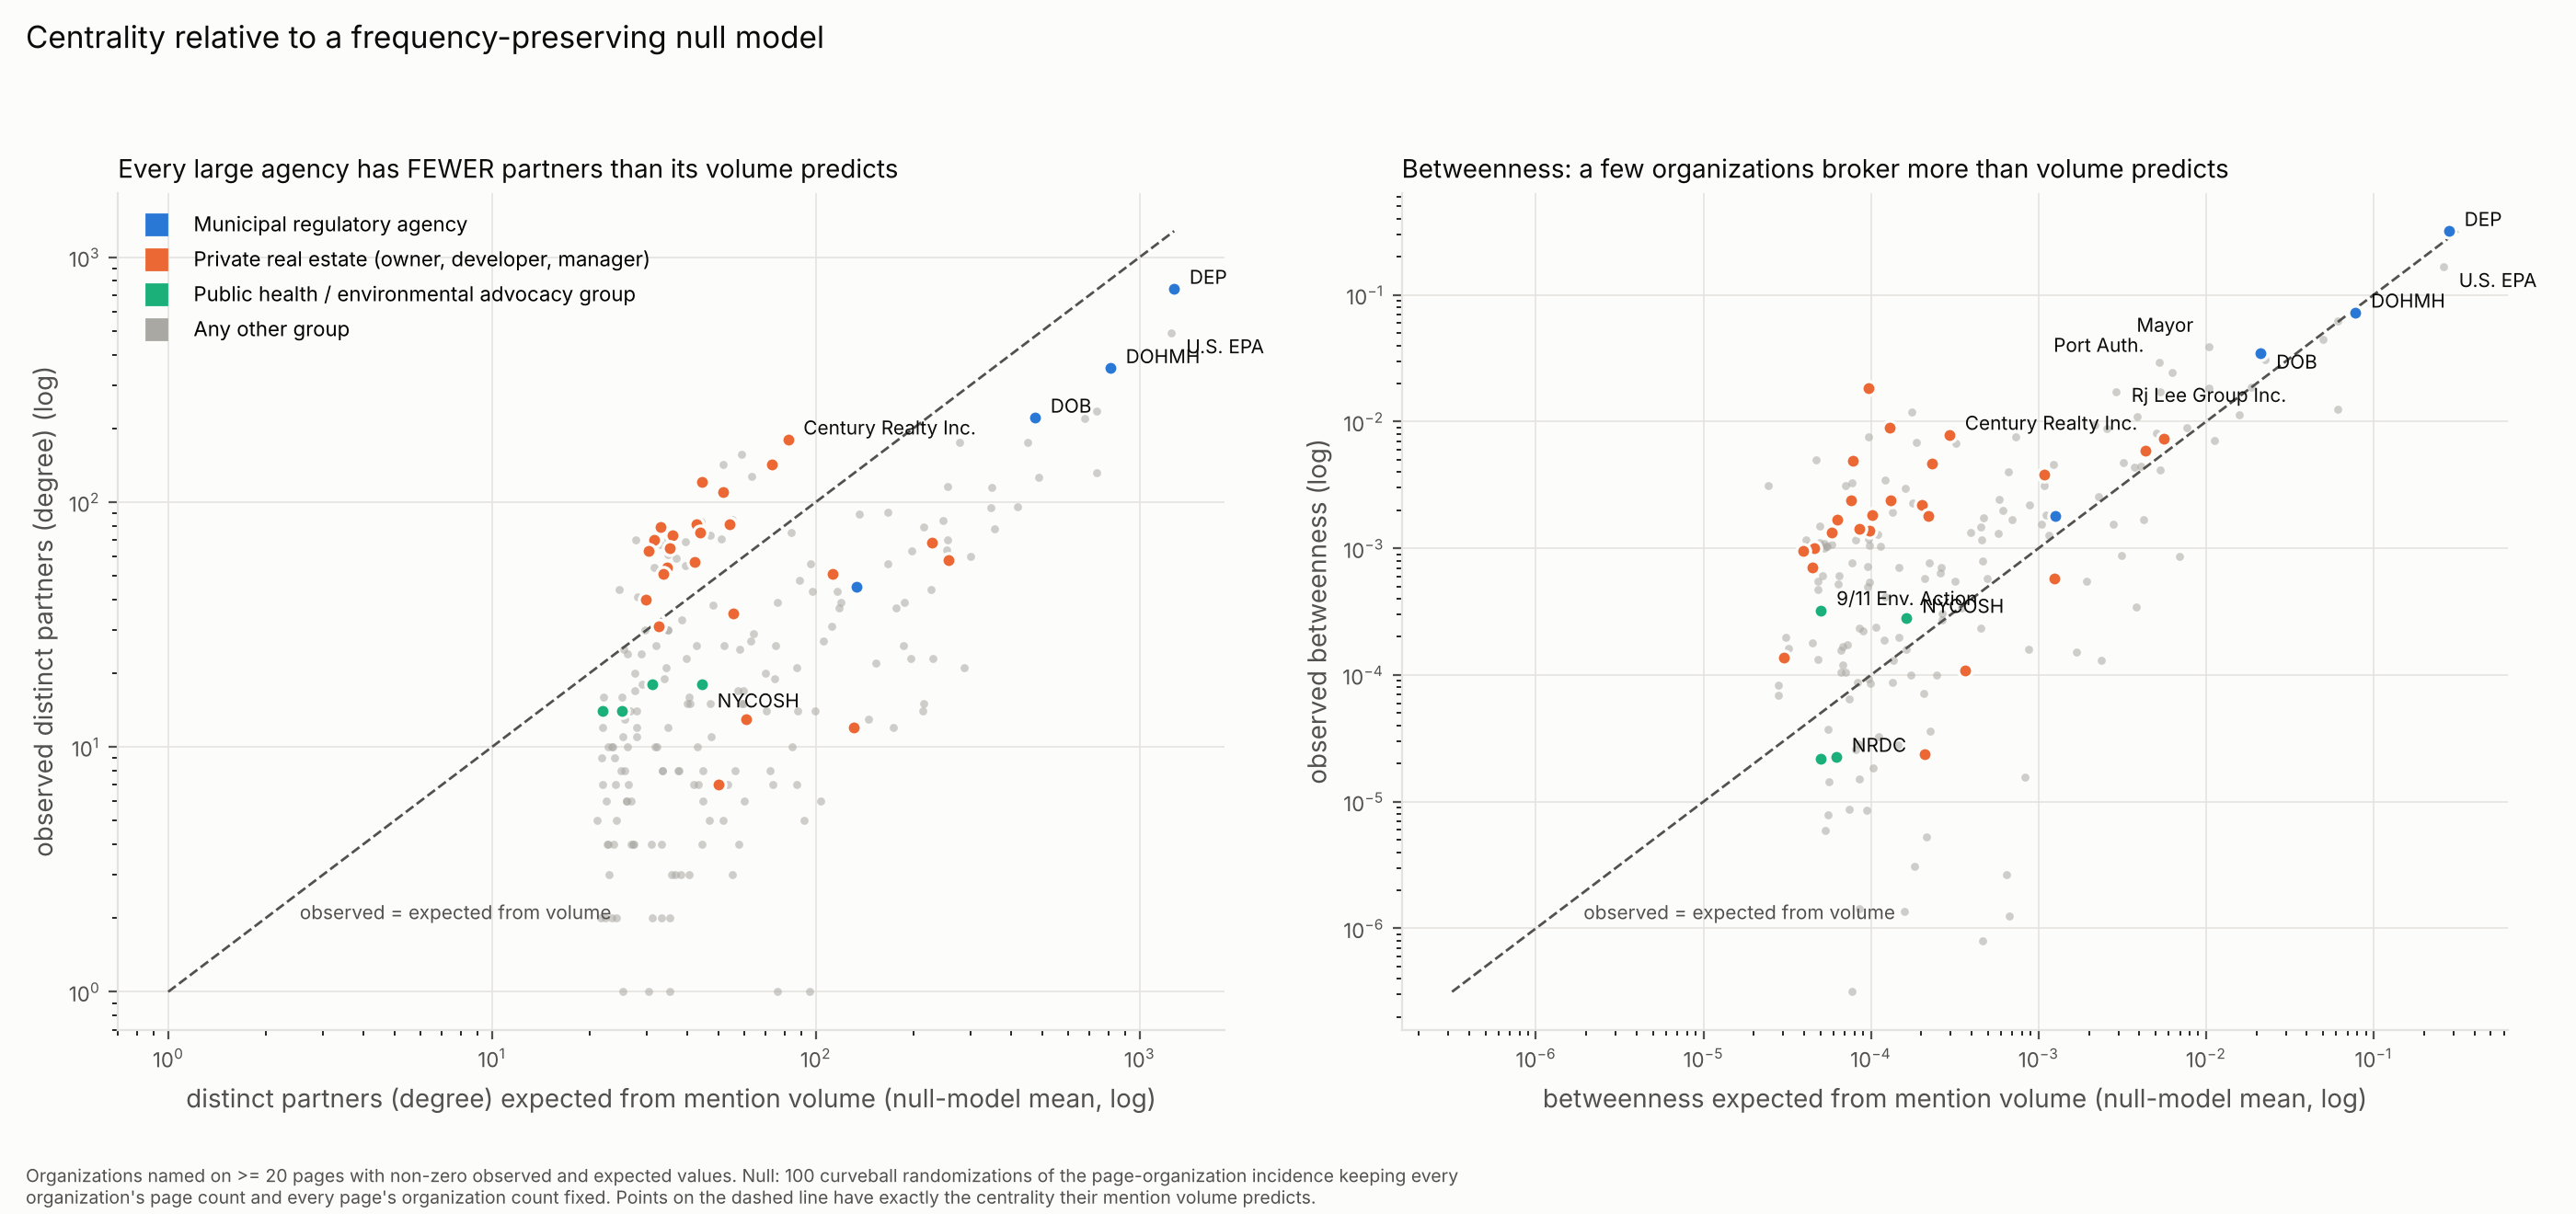

In [36]:
label = {"degree": ["NYC Dept. of Environmental Protection", "U.S. EPA", "NYC Dept. of Health and Mental Hygiene",
                    "NYC Dept. of Buildings", "Century Realty Inc.", "NYCOSH (NY Committee for Occupational Safety & Health)"],
         "betweenness": ["NYC Dept. of Environmental Protection", "U.S. EPA", "NYC Dept. of Health and Mental Hygiene",
                         "NYC Dept. of Buildings", "NYC Office of the Mayor", "Port Authority of NY & NJ", "Rj Lee Group Inc.",
                         "Century Realty Inc.", "NYCOSH (NY Committee for Occupational Safety & Health)",
                         "9/11 Environmental Action", "Natural Resources Defense Council"]}
display(Image(filename=str(figures.observed_vs_null(cmp_g, label)), width=1000))

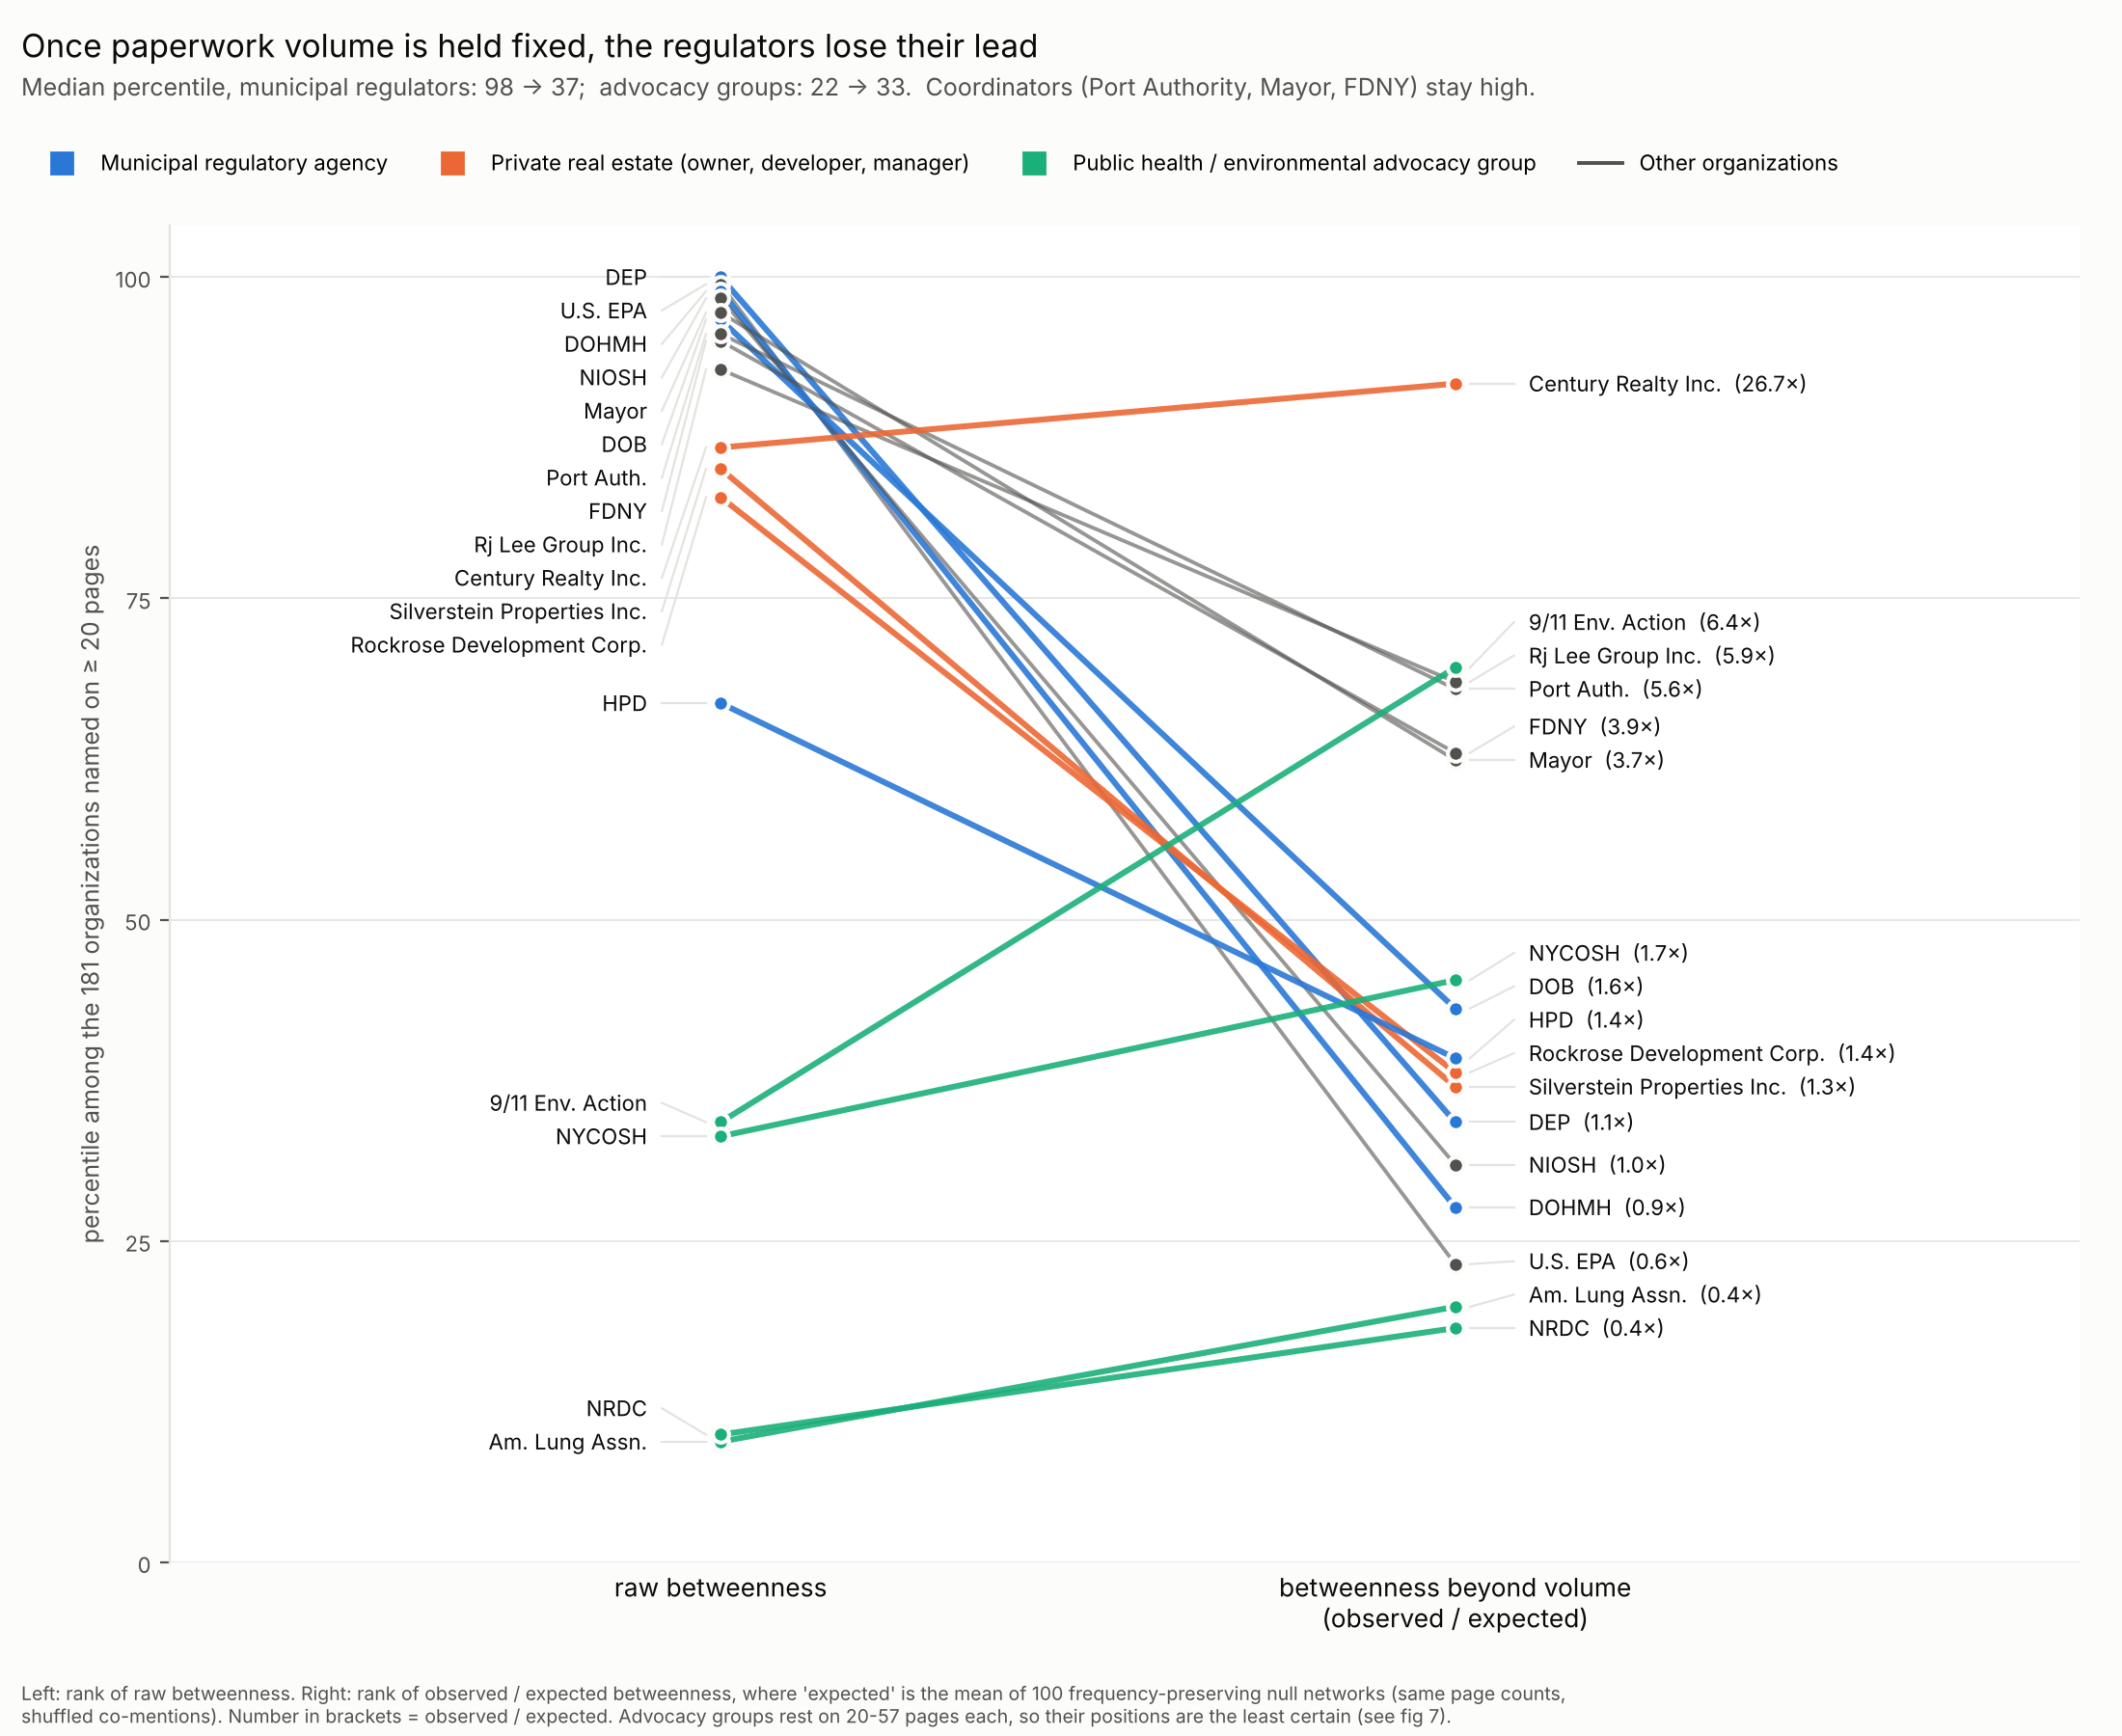

In [37]:
# the same comparison as a slope chart: each organization's percentile before and after holding volume fixed
display(Image(filename=str(figures.raw_vs_adjusted(cmp_g, figures.FIG8_NAMES)), width=900))

### 6b. Hyperbolic weights instead of a hard page-size cut

Section 5 drops pages naming more than 7 organizations, an all-or-nothing rule. Hyperbolic weighting (Newman 2001) is the smooth version: a page naming *k* organizations adds 1/(*k*−1) to each of its pairs, so **every page gives each organization on it a total weight of 1** however long the list is. Weighted betweenness then uses distance = 1/weight (strong ties are short). Unlike the cut, no page is discarded.

In [38]:
ne = backbone.newman_edges(sup["evidence"])
wm = sup["nodes"].merge(backbone.weighted_metrics(sup["nodes"]["node_id"], ne), on="node_id")
display(metrics.group_summary(metrics.hypothesis_views(wm), ("pct_betweenness", "pct_betweenness_weighted",
                                                              "pct_strength_newman"))[["view", "metric", "n", "median", "min", "max"]].round(1))
wm.nlargest(12, "betweenness_weighted")[["name", "group", "n_pages", "strength_newman", "betweenness_weighted", "betweenness"]].round(4)

,view,metric,n,median,min,max
0,municipal regulatory,pct_betweenness,4,99.8,94.9,100.0
1,private real estate: all,pct_betweenness,119,72.9,27.4,99.3
2,"private real estate: manual, incl. uncertain",pct_betweenness,20,94.9,68.7,98.6
3,private real estate: manually confirmed,pct_betweenness,10,96.0,68.7,98.4
4,public-health advocacy (exploratory),pct_betweenness,4,76.4,68.4,84.9
5,municipal regulatory,pct_betweenness_weighted,4,99.7,92.2,100.0
6,private real estate: all,pct_betweenness_weighted,119,41.4,41.4,99.2
7,"private real estate: manual, incl. uncertain",pct_betweenness_weighted,20,93.1,41.4,98.6
8,private real estate: manually confirmed,pct_betweenness_weighted,10,94.8,41.4,98.6
9,public-health advocacy (exploratory),pct_betweenness_weighted,4,41.4,41.4,41.4


,name,group,n_pages,strength_newman,betweenness_weighted,betweenness
0,NYC Dept. of Environmental Protection,municipal_regulatory,26158,11827.0,0.6351,0.3193
1,U.S. EPA,state_federal_regional,24138,13391.0,0.5063,0.1675
5,NIOSH,state_federal_regional,6239,5066.0,0.1342,0.0622
6,NYC Office of Emergency Management,city_other,2699,1842.0,0.0907,0.0307
2,NYC Dept. of Health and Mental Hygiene,municipal_regulatory,7862,7056.0,0.0741,0.0725
8,NYC Dept. of Buildings,municipal_regulatory,2615,1486.0,0.0655,0.0346
11,NYC Office of the Mayor,city_other,1534,983.0,0.0589,0.0388
4,OSHA,state_federal_regional,5254,3869.0,0.0486,0.0449
3,Atc Associates Inc.,consultant_contractor_lab,6327,5238.0,0.0312,0.0126
22,Port Authority of NY & NJ,state_federal_regional,886,473.0,0.0283,0.0295


**Reading (6b).** Hyperbolic weighting keeps the same agencies at the top (DEP, EPA, NIOSH, OEM, DOHMH, DOB, Mayor, OSHA), and the strong weighted shortest paths run through DEP (0.64) and EPA (0.51). For the hypothesis groups it acts like the section-5 page cut, but without discarding pages:
* **all 119 real-estate nodes** drop from a median betweenness percentile of 72.9 to 41.4 (the tie at zero): their paths ran through long lists that now carry little weight;
* the **10 hand-confirmed firms** hold (96.0 → 94.8);
* the **4 advocacy groups** drop from 76.4 to 41.4: none of them lies on any weighted shortest path. Their weighted strength stays high (90.7) because most of their pages name only one or two other organizations, so each tie keeps nearly full weight.

The smooth weighting and the hard cut agree, so the section-5 conclusions do not depend on the cutoff of 7.

### 6c. Validated backbone: which ties are more frequent than chance?

For a pair with *w* shared pages, where *i* is named on *n<sub>i</sub>* pages and *j* on *n<sub>j</sub>* of *N* pages, the hypergeometric p-value P(X ≥ *w*) is the chance of that much overlap if the two were placed on pages independently (Tumminello et al. 2011). An edge is **validated** if p < 0.01 / (number of possible pairs ≈ 1.37 million), i.e. Bonferroni over all pairs, not only the observed ones.

*Caveat*: for an organization on 37% of all pages (DEP), only very strong overlaps can pass. The test has little power for near-ubiquitous nodes, so a low backbone degree for DEP means "its ties are what its volume predicts", not "it has no ties".

In [39]:
e_val, bbn, G_bb = backbone.backbone_network(sup, prep)
display(backbone.backbone_stats(e_val).round(3))
display(metrics.group_summary(metrics.hypothesis_views(bbn), ("bb_pct_degree_centrality", "bb_pct_betweenness"))[
    ["view", "metric", "n", "median", "min", "max"]].round(1))
bbn.set_index("name").loc[["NYC Dept. of Environmental Protection", "U.S. EPA", "NYC Dept. of Health and Mental Hygiene",
                           "NYC Dept. of Buildings", "NYC Dept. of Housing Preservation and Development",
                           *build.advocacy_nodes(prep.adv)["name"]], ["n_pages", "degree", "bb_degree", "bb_betweenness"]]

,rule,edges_kept,share_edges,share_weight,median_weight_kept,median_weight_dropped
0,validated_bonferroni,2382,0.212,0.557,4.0,1.0
1,validated_fdr,4338,0.386,0.627,3.0,1.0


,view,metric,n,median,min,max
0,municipal regulatory,bb_pct_degree_centrality,4,91.7,91.5,98.3
1,private real estate: all,bb_pct_degree_centrality,119,79.5,23.8,100.0
2,"private real estate: manual, incl. uncertain",bb_pct_degree_centrality,20,92.5,54.8,100.0
3,private real estate: manually confirmed,bb_pct_degree_centrality,10,81.8,54.8,100.0
4,public-health advocacy (exploratory),bb_pct_degree_centrality,4,23.8,23.8,23.8
5,municipal regulatory,bb_pct_betweenness,4,99.2,96.6,99.9
6,private real estate: all,bb_pct_betweenness,119,39.9,39.9,99.8
7,"private real estate: manual, incl. uncertain",bb_pct_betweenness,20,91.1,39.9,99.8
8,private real estate: manually confirmed,bb_pct_betweenness,10,89.9,39.9,99.8
9,public-health advocacy (exploratory),bb_pct_betweenness,4,39.9,39.9,39.9


,n_pages,degree,bb_degree,bb_betweenness
name,,,,
NYC Dept. of Environmental Protection,26158,742,10,0.004753
U.S. EPA,24138,491,34,0.009749
NYC Dept. of Health and Mental Hygiene,7862,352,24,0.012114
NYC Dept. of Buildings,2615,221,9,0.003577
NYC Dept. of Housing Preservation and Development,302,45,9,0.001402
9/11 Environmental Action,23,14,0,0.000000
American Lung Association,20,14,0,0.000000
Natural Resources Defense Council,33,18,0,0.000000
NYCOSH (NY Committee for Occupational Safety & Health),57,18,0,0.000000


In [40]:
# highest betweenness on the validated backbone
bbn.nlargest(12, "bb_betweenness")[["name", "group", "n_pages", "degree", "bb_degree", "bb_betweenness"]].round(4)

,name,group,n_pages,degree,bb_degree,bb_betweenness
31,NYC Dept. of Sanitation,city_other,279,89,28,0.0173
2,NYC Dept. of Health and Mental Hygiene,municipal_regulatory,7862,352,24,0.0121
16,FDNY,city_other,988,176,20,0.0113
65,Century Realty Inc.,private_real_estate,68,180,54,0.0113
5,NIOSH,state_federal_regional,6239,235,35,0.0109
196,Collegiate Church Corp.,other_unknown,132,75,7,0.0101
1,U.S. EPA,state_federal_regional,24138,491,34,0.0097
66,Maiden Lane Associates LLC,private_real_estate,58,142,51,0.0069
234,Morgan Guaranty Trust Co.,other_unknown,17,110,33,0.0067
4,OSHA,state_federal_regional,5254,220,21,0.0063


In [41]:
# does anything depend on the strict (Bonferroni) rule? rebuild with the looser false-discovery-rate rule
rules = backbone.rule_sensitivity(sup, prep)
rules.round(3)

,rule,edges_kept,advocacy_ties,modularity,ties_between_top6_blocks,share_between_ties_via_hub,DEP_degree,DEP_and_DOHMH_same_block,EPA_and_DEP_same_block
0,validated_bonferroni,2382,0,0.599,115,0.617,10,True,False
1,validated_fdr,4338,6,0.600,271,0.557,22,True,False


In [42]:
# the strict test has little power for DEP (named on 37% of pages): rank DEP's ties by observed / expected instead
backbone.dep_strongest_ties(e_val, "agency:nyc-dep", prep.node_info.set_index("node_id")["name"]).round(3)

,partner_name,weight,expected_weight,obs_over_exp,p_hypergeom,validated_bonferroni,validated_fdr
294,Michael A Cardozo Corp.,36,13.228,2.722,0.0,True,True
353,Liberty Street LLC,26,9.554,2.722,0.0,True,True
428,Asbestos Removal Corp.,20,8.084,2.474,0.0,False,True
136,Trio Asbestos Removal Corp.,99,44.828,2.208,0.0,True,True
441,Approved Asbestos Abatement Inc.,20,9.186,2.177,0.0,False,True
298,Kensico Laboratory,35,16.168,2.165,0.0,False,True
181,Fiber Control Inc.,71,34.907,2.034,0.0,True,True
425,Safeway Environmental Corp.,20,9.921,2.016,0.0,False,False
79,NYC Dept. of Sanitation,195,102.517,1.902,0.0,True,True
384,Psc Analytical,23,12.126,1.897,0.0,False,False


**Reading (6c).**
* Only **21% of edges (2,382 of 11,227) are more frequent than chance**, but they carry 56% of the pair evidence. The median validated edge rests on 4 shared pages, the median rejected one on 1.
* **All four advocacy groups lose every edge under the strict rule.** Under the looser false-discovery-rate rule (4,338 edges) they keep 6 in total: NRDC with the Port Authority and LMDC, NYCOSH with a Brookhaven laboratory and two consultants, the American Lung Association with one property firm. Each municipal regulator keeps 13–38. So they are *barely* tied in rather than not at all, and the contrast with the regulators holds under both rules.
* DEP keeps only 10 validated ties out of 742 (see caveat: low power at 37% page share); 22 under the looser rule. Ranked by observed / expected shared pages instead, DEP's most distinctive ties are asbestos-abatement contractors (Trio, Fiber Control and others, about 2×), the Sanitation Dept. (1.9×) and an extracted entity 'Michael A Cardozo Corp.', which is the name of the city's Corporation Counsel, i.e. the head of the Law Department (2.7×).
* Under both rules DEP and DOHMH share a block, EPA sits in a different block, and the public-health block carries 56–62% of the ties between the six largest blocks.
* On the backbone the top brokers are the Sanitation Dept., DOHMH, FDNY, Century Realty and NIOSH. The municipal regulators stay high on backbone betweenness (median percentile 99.2) while the advocacy groups are at the tie for zero (39.9). On the backbone, H1's regulator-vs-advocacy contrast is sharp, but it is a contrast between *connected* and *unconnected* nodes, not between more and less central ones.

### 6d. Archive bias: the network without DEP's own files

62% of the documents that name an organization come from DEP's files (section 1). Here every mention on a document whose `agency` is DEP is dropped and the network rebuilt (node set fixed, as in section 5).

In [43]:
dep = settings.EXCLUDED_SOURCE_AGENCY
dep_docs = set(t["documents"].loc[t["documents"]["agency"].eq(dep), "doc_id"])
# where are the hypothesis organizations named? share of their pages that sit in DEP's files
hv = metrics.hypothesis_views(sup["nodes"])
pages_in_dep = om_sup.assign(in_dep=om_sup["doc_id"].isin(dep_docs)).groupby("node_id")["in_dep"].mean()
display(hv.assign(share_pages_in_DEP_files=hv["node_id"].map(pages_in_dep)).groupby("view")[
    "share_pages_in_DEP_files"].describe()[["count", "min", "50%", "max"]].round(2))
nodep = pipeline.build_network(prep, unit="page", include_advocacy=True, exclude_source_agency=dep)
display(pd.DataFrame({"with DEP files": sup["stats"], "without DEP files": nodep["stats"]}).loc[
    ["edges", "components", "largest_component_share", "isolates", "degree_median"]].round(3))
nd_dep = robustness.add_ranks(nodep["nodes"])
nd_dep.nlargest(10, "betweenness")[["name", "group", "n_pages_used", "degree", "rank_degree", "rank_betweenness"]]

,count,min,50%,max
view,,,,
municipal regulatory,4.0,0.80,0.93,0.98
private real estate: all,119.0,0.00,1.00,1.00
"private real estate: manual, incl. uncertain",20.0,0.01,1.00,1.00
private real estate: manually confirmed,10.0,0.01,1.00,1.00
public-health advocacy (exploratory),4.0,0.88,0.95,0.96


,with DEP files,without DEP files
edges,11227.000,1773.000
components,109.000,1119.000
largest_component_share,0.908,0.293
isolates,91.000,1101.000
degree_median,5.000,0.000


,name,group,n_pages_used,degree,rank_degree,rank_betweenness
1,U.S. EPA,state_federal_regional,4575,150,1,1
11,NYC Office of the Mayor,city_other,1007,60,9,2
6,NYC Office of Emergency Management,city_other,1911,93,2,3
5,NIOSH,state_federal_regional,1028,87,3,4
961,Costar Realty Information Inc.,private_real_estate,35,31,20,5
22,Port Authority of NY & NJ,state_federal_regional,600,62,7,6
4,OSHA,state_federal_regional,1273,76,4,7
10,NYC Law Department,city_other,436,48,12,8
20,NYC Dept. of Design and Construction,city_other,353,62,7,9
45,Verizon,private_utility,48,33,18,10


In [44]:
v_dep = metrics.hypothesis_views(nd_dep)
v_dep[v_dep["view"].isin(["municipal regulatory", "public-health advocacy (exploratory)",
                          "private real estate: manually confirmed"])][
    ["view", "name", "n_pages", "n_pages_used", "degree", "rank_degree", "rank_betweenness"]]

,view,name,n_pages,n_pages_used,degree,rank_degree,rank_betweenness
0,municipal regulatory,NYC Dept. of Environmental Protection,26158,1181,69,6,12
1,municipal regulatory,NYC Dept. of Health and Mental Hygiene,7862,1581,74,5,11
2,municipal regulatory,NYC Dept. of Buildings,2615,61,22,26,74
3,municipal regulatory,NYC Dept. of Housing Preservation and Development,302,27,15,36,103
143,private real estate: manually confirmed,Silverstein Properties Inc.,891,878,39,15,35
144,private real estate: manually confirmed,Rockrose Development Corp.,751,0,0,556,158
145,private real estate: manually confirmed,Century Realty Inc.,68,0,0,556,158
146,private real estate: manually confirmed,Gateway Plaza Management Corp.,90,0,0,556,158
147,private real estate: manually confirmed,Cushman And Wakefield Inc.,48,6,5,150,54
148,private real estate: manually confirmed,Masterworks Development Corp.,243,0,0,556,158


share of ALL organization pages that come from DEP's files: 79%


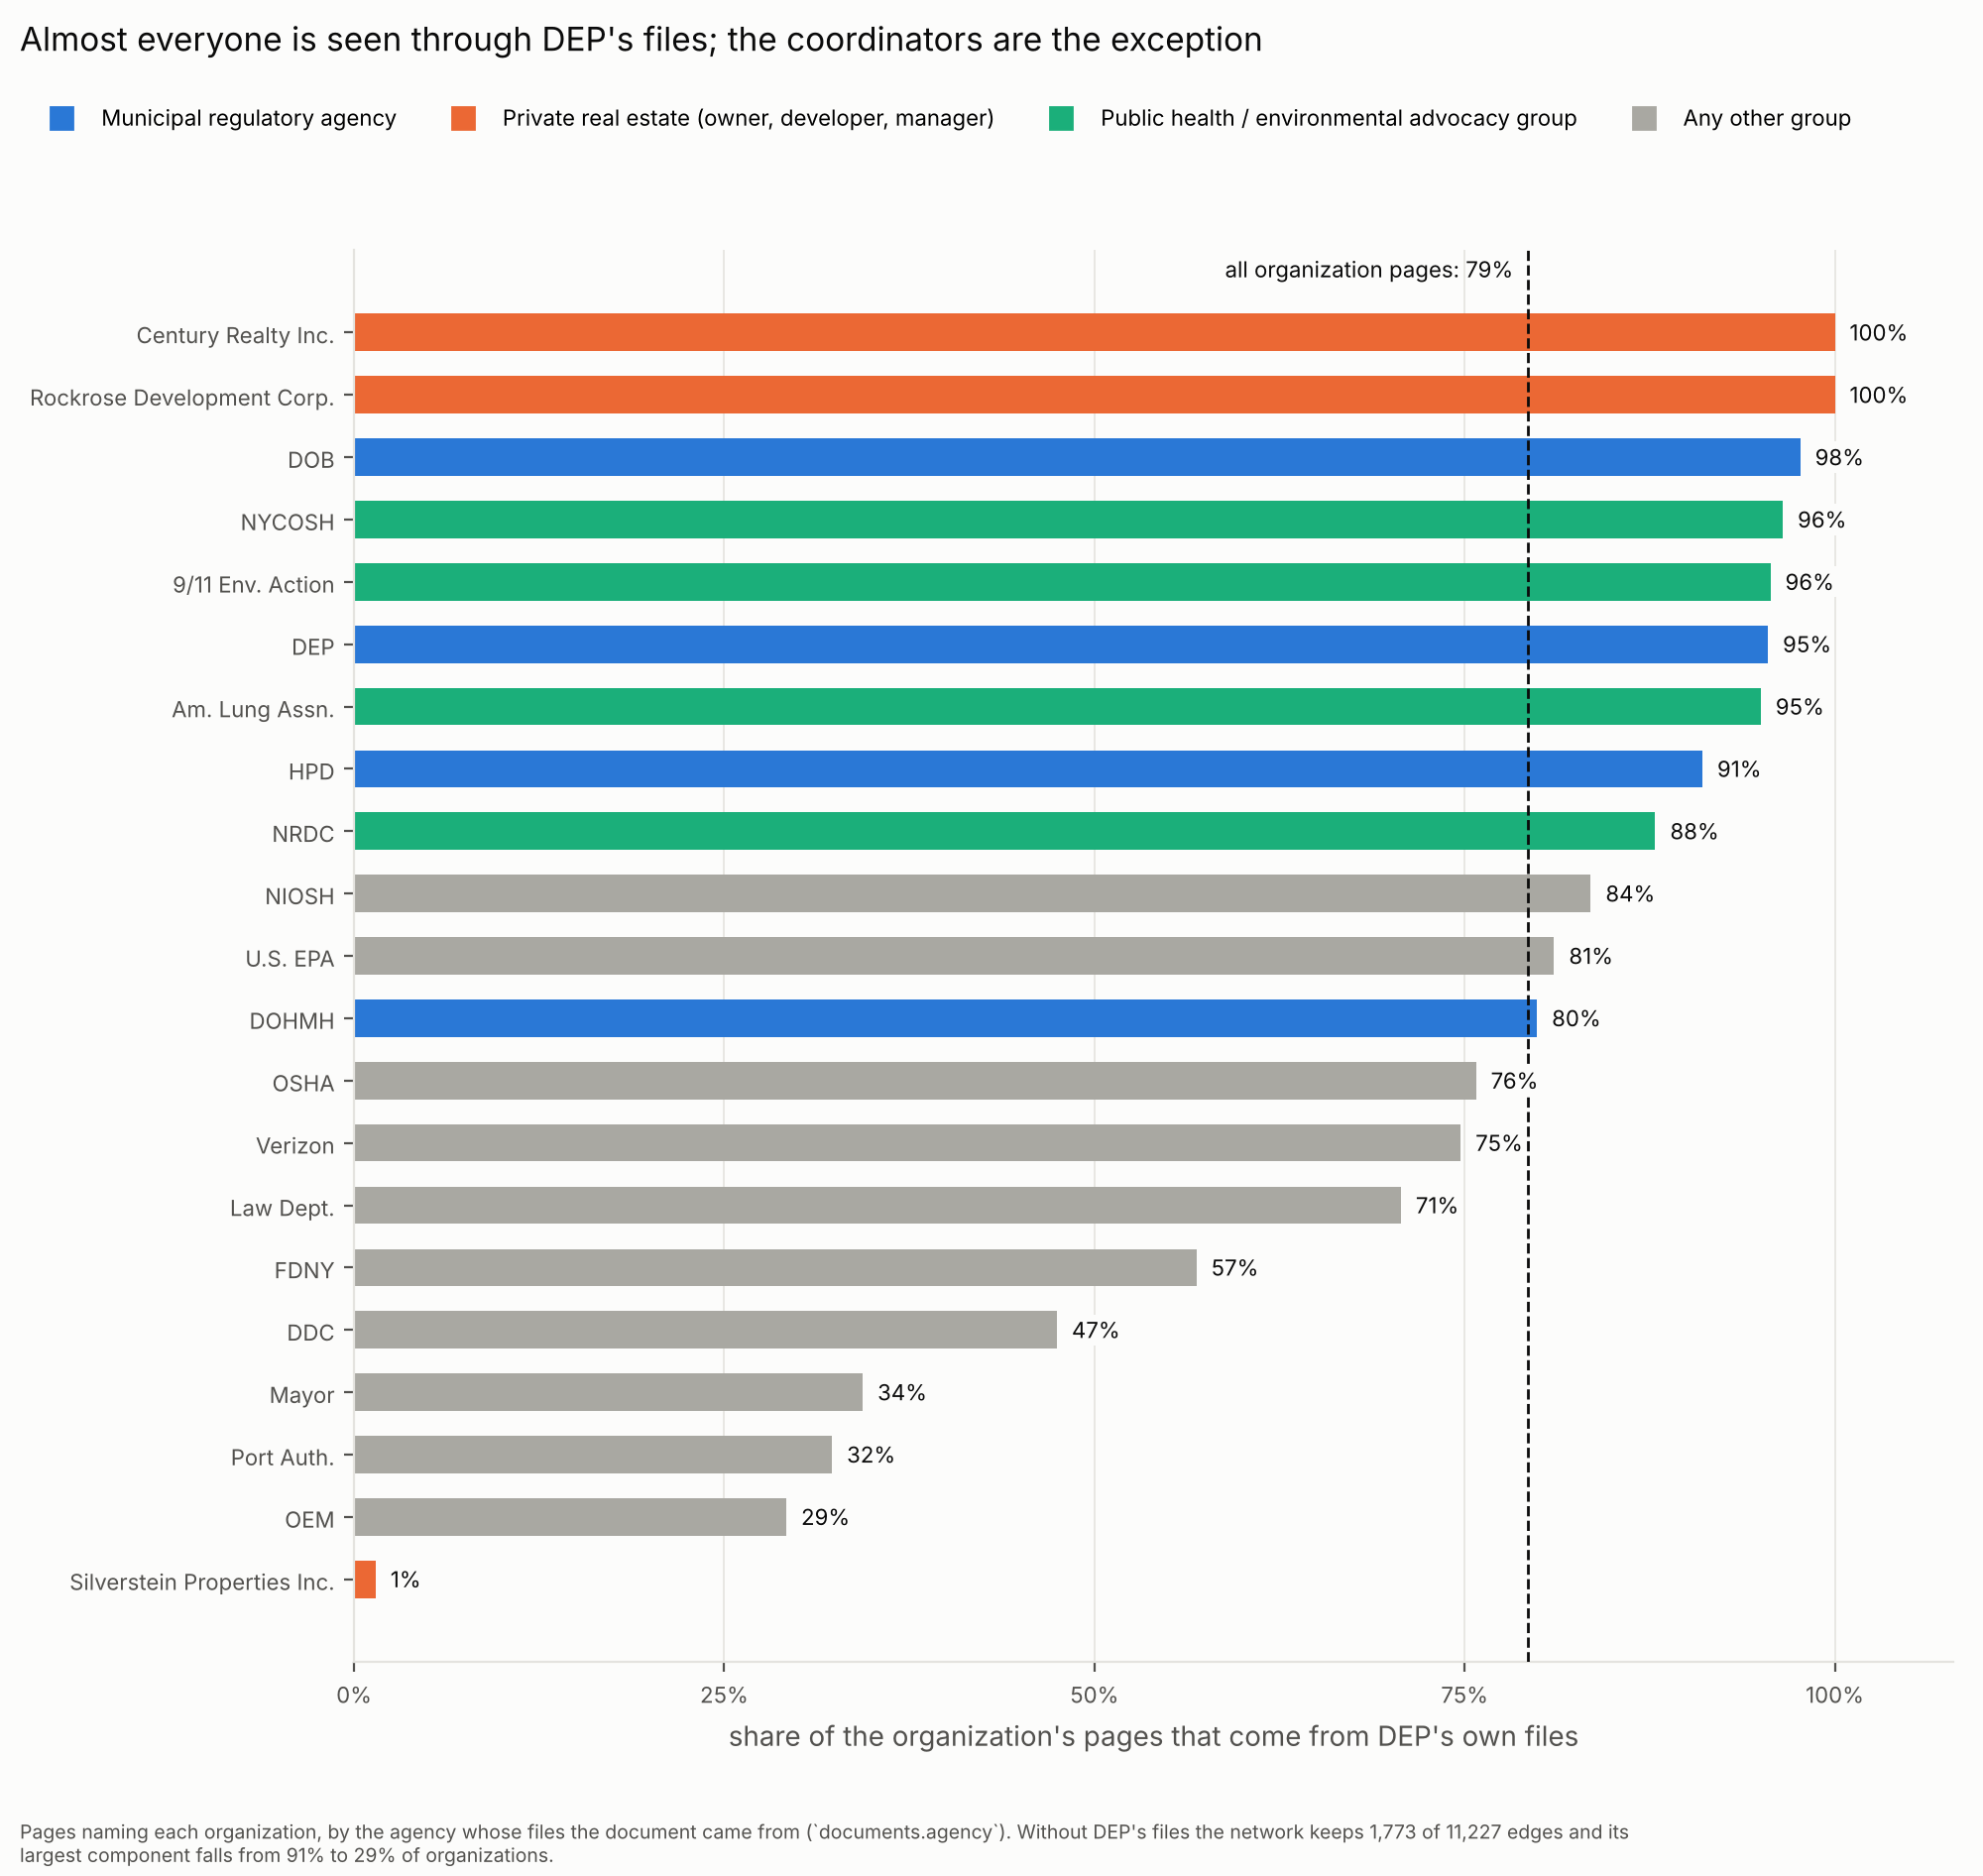

In [45]:
share_dep, base_dep = pipeline.share_in_source(prep, dep)
info_ = prep.node_info.set_index("node_id")
fig9_data = info_[info_["name"].isin(figures.FIG9_NAMES)][["name", "group"]].join(share_dep.rename("share"))
print(f"share of ALL organization pages that come from DEP's files: {base_dep:.0%}")
display(Image(filename=str(figures.whose_files(fig9_data, base_dep)), width=850))

**Reading (6d).**
* **The archive's network is mostly DEP's network.** Without DEP's files only 1,773 of 11,227 edges remain, the largest component falls from 91% to 29% of nodes, and 1,101 of 1,656 organizations become isolates.
* **Almost everyone in the archive is seen through DEP's files** (fig 9): 79% of all pages that name any organization come from them. The hypothesis groups are at or above that baseline. The advocacy groups have 88–96% of their pages there (NYCOSH keeps 2 of 57 pages without them, 9/11 Environmental Action 1 of 23, NRDC 4 of 33, American Lung Association 1 of 20). The median real-estate firm has 100% there, from building / ownership lists. The main exception is Silverstein Properties, whose 891 pages are nearly all in other agencies' files. Even the four regulators have 80–98% of their pages there (median 93%). **Every Hypothesis 1 comparison is in effect a comparison inside DEP's own records.** The clear exceptions are the coordinators: only 29% of OEM's, 32% of the Port Authority's, 34% of the Mayor's Office's and 47% of DDC's pages are in DEP's files. They are the organizations named across *other* agencies' records, which is consistent with their high betweenness beyond volume in 6a.
* In the other agencies' files the leading brokers are EPA, the Mayor's Office, OEM, NIOSH, the Port Authority, OSHA and the Law Department. DEP (betweenness rank 12, from 1,181 pages) and DOHMH (rank 11) remain well connected even without DEP's own paperwork, so their position is not only an artifact of whose files were released.

### 6e. How stable are the ranks? Document bootstrap

The released archive is one draw of what the agencies produced. Resampling **documents** with replacement (the unit that was released or withheld whole) 100 times and rebuilding the page network shows how much each rank, and each Hypothesis 1 comparison, depends on which documents happen to be in the release. This is a stability check, not a significance test.

In [46]:
b_ids, b_deg, b_bt = bootstrap.run(prep, sup)                       # cached: outputs/network/bootstrap_100.npz
views_sup = metrics.hypothesis_views(sup["nodes"])
iv = bootstrap.rank_intervals(b_ids, b_deg, b_bt, views_sup)
display(bootstrap.comparison_stability(b_ids, b_deg, b_bt, views_sup).round(2))
iv[iv["view"].isin(["municipal regulatory", "public-health advocacy (exploratory)", "private real estate: manually confirmed"])][
    ["view", "name", "rank_degree_lo", "rank_degree_med", "rank_degree_hi",
     "rank_betweenness_lo", "rank_betweenness_med", "rank_betweenness_hi"]].round(0)

,metric,comparison,share_of_bootstraps,n_boot
0,degree,municipal regulatory min > max advocacy,1.00,100
1,degree,municipal regulatory median > advocacy,1.00,100
2,degree,private real estate: all median > advocacy,0.91,100
3,degree,private real estate: manually confirmed median > advocacy,1.00,100
4,degree,private real estate: manually confirmed min > max advocacy,0.00,100
5,betweenness,municipal regulatory min > max advocacy,0.95,100
6,betweenness,municipal regulatory median > advocacy,1.00,100
7,betweenness,private real estate: all median > advocacy,0.39,100
8,betweenness,private real estate: manually confirmed median > advocacy,1.00,100
9,betweenness,private real estate: manually confirmed min > max advocacy,0.01,100


,view,name,rank_degree_lo,rank_degree_med,rank_degree_hi,rank_betweenness_lo,rank_betweenness_med,rank_betweenness_hi
0,municipal regulatory,NYC Dept. of Environmental Protection,1.0,1.0,1.0,1.0,1.0,1.0
1,municipal regulatory,NYC Dept. of Health and Mental Hygiene,3.0,3.0,3.0,3.0,3.0,4.0
2,municipal regulatory,NYC Dept. of Buildings,4.0,5.0,6.0,5.0,6.0,9.0
3,municipal regulatory,NYC Dept. of Housing Preservation and Development,73.0,111.0,178.0,69.0,86.0,291.0
143,private real estate: manually confirmed,Silverstein Properties Inc.,47.0,78.0,120.0,24.0,31.0,45.0
144,private real estate: manually confirmed,Rockrose Development Corp.,30.0,48.0,111.0,27.0,34.0,45.0
145,private real estate: manually confirmed,Century Realty Inc.,6.0,7.0,10.0,18.0,23.0,39.0
146,private real estate: manually confirmed,Gateway Plaza Management Corp.,296.0,366.0,495.0,273.0,339.0,475.0
147,private real estate: manually confirmed,Cushman And Wakefield Inc.,56.0,104.0,191.0,55.0,109.0,203.0
148,private real estate: manually confirmed,Masterworks Development Corp.,68.0,110.0,232.0,36.0,49.0,129.0


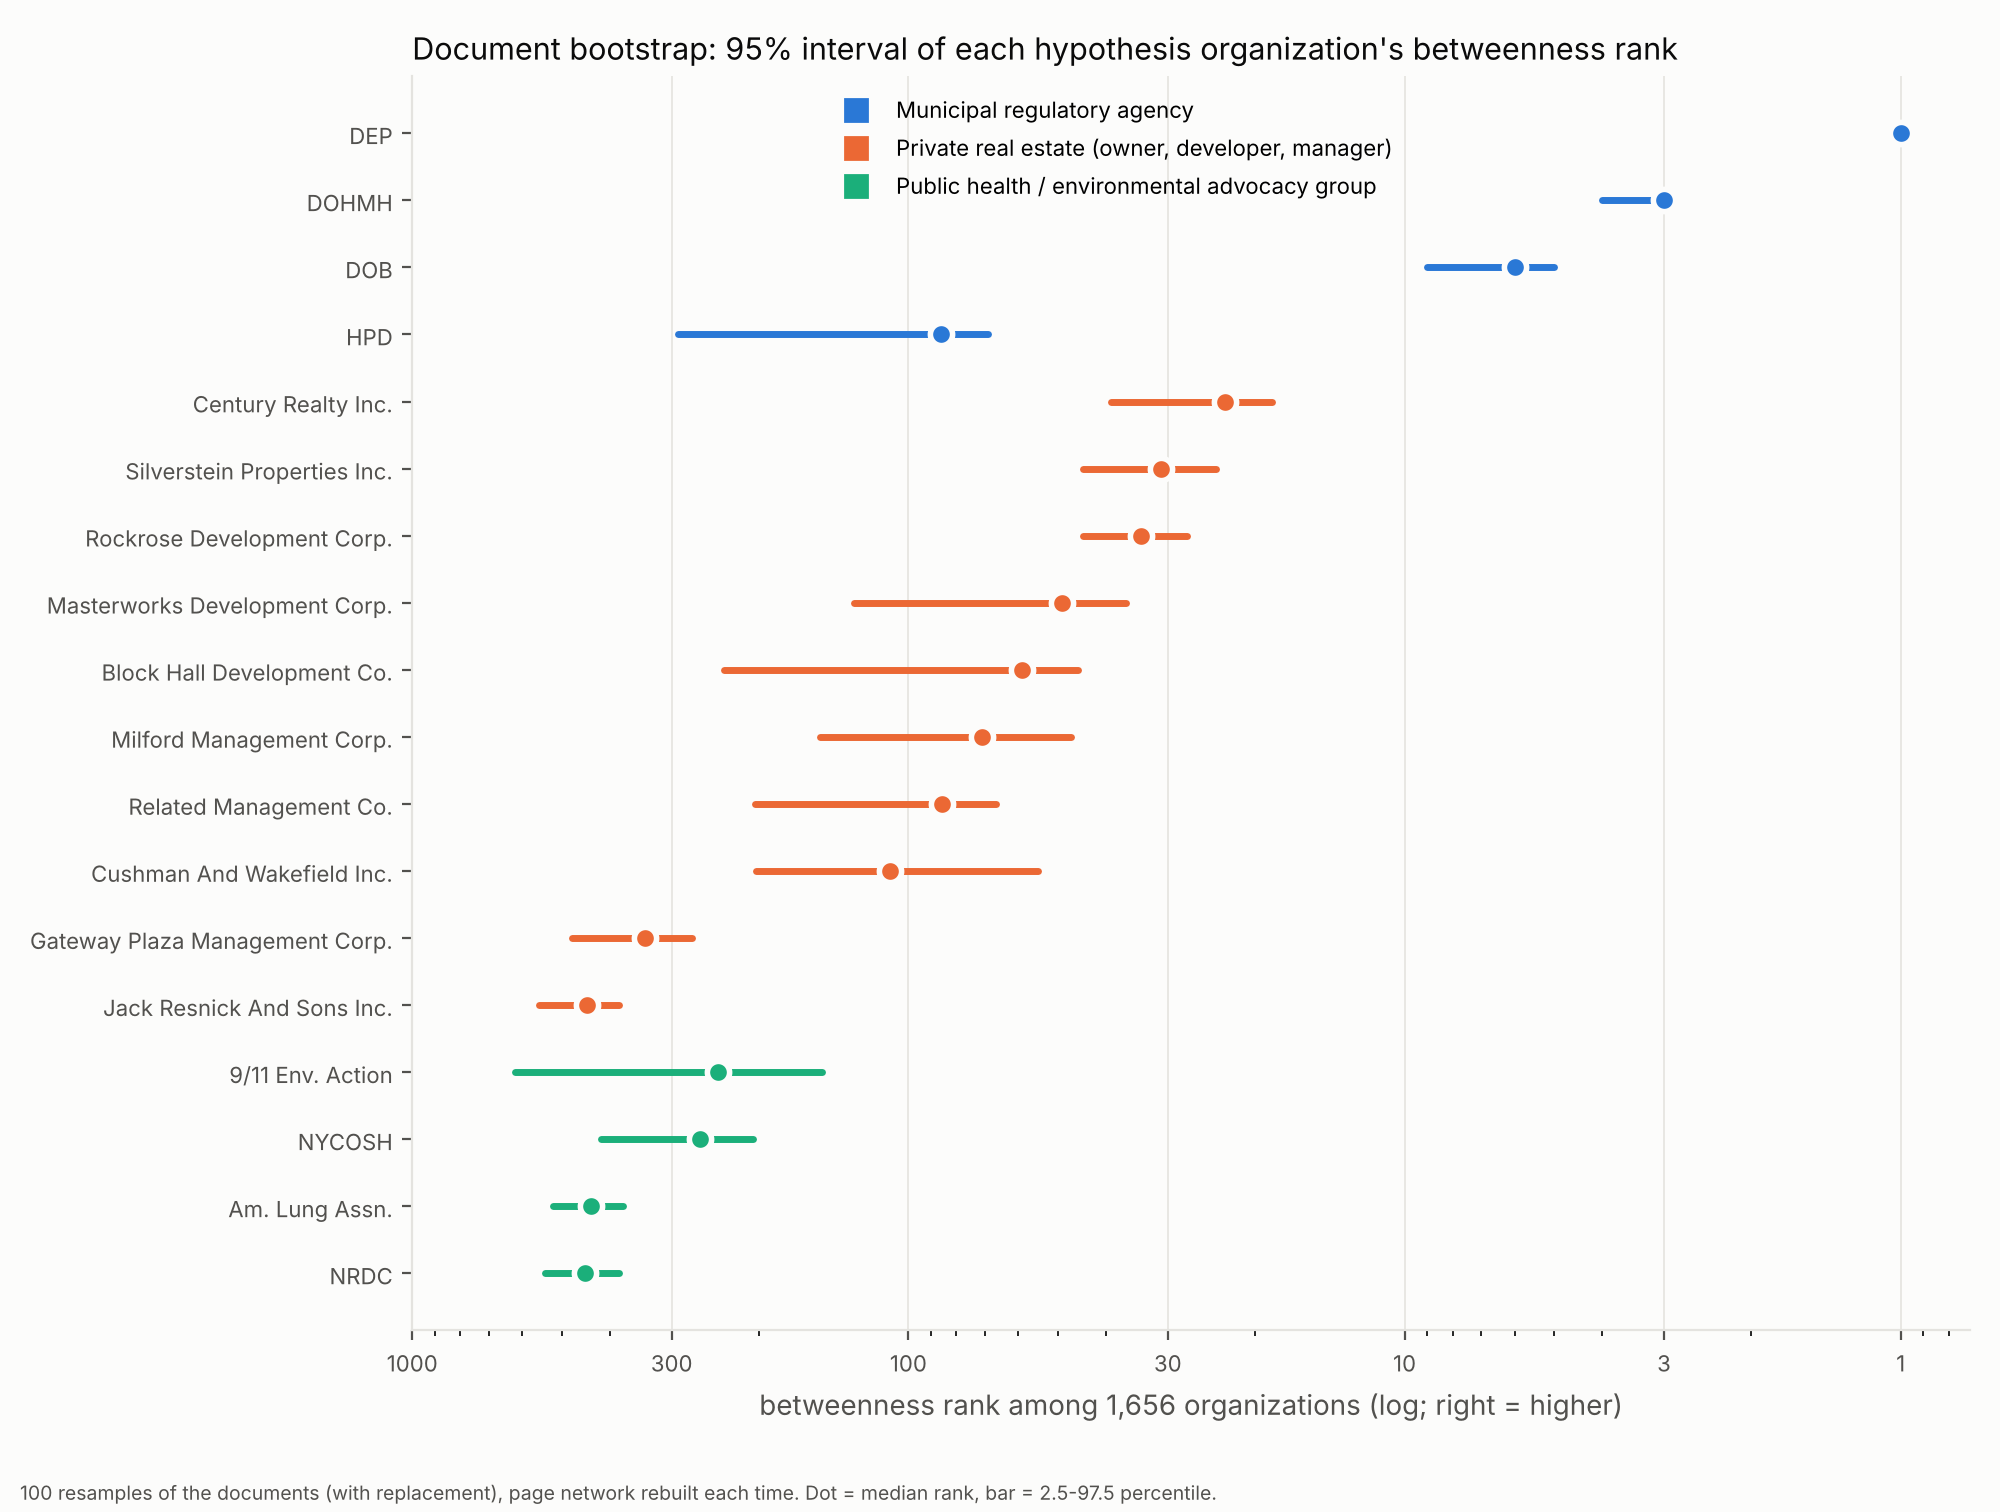

In [47]:
display(Image(filename=str(figures.bootstrap_ranks(iv, "betweenness")), width=850))

**Reading (6e).**
* **The top is fixed**: DEP is rank 1 and DOHMH rank 3 on both metrics in every one of the 100 resamples; DOB sits at 4–6 (degree) and 5–9 (betweenness). HPD is unstable (betweenness rank 69–291).
* **Regulators above every advocacy group** holds in 100% of resamples on degree and **95%** on betweenness. The 5% failures are HPD against 9/11 Environmental Action, whose interval is the widest of all (rank 149–622: it rests on 23 pages).
* **Hand-confirmed real estate above advocacy (medians)** holds in 100% of resamples on both metrics. But **all 119 real-estate nodes above advocacy** holds in 91% on degree and only **39% on betweenness**: that version of H1 is a coin flip under resampling.
* "Every confirmed real-estate firm above every advocacy group" essentially never holds (0–1%): Gateway Plaza and Jack Resnick rank as low as the advocacy groups.
* The resampling adds a second reason for caution to section 4: what looks like a clear group difference for the broad real-estate group depends on which documents were released.

### 6f. When did each organization hold its position? Monthly networks

The pooled network mixes very different moments: emergency response, air and dust testing, the residential clean-up program, litigation. A node can be a broker in one phase and peripheral in another; pooling averages that away. Here: **one page co-occurrence network per month, September 2001 to December 2002** (every month has ≥ 900 dated pages naming an organization; 78% of dated documents fall in 2001–2002). Only documents dated to the day or month are used. Each month gets its own frequency-preserving null (100 samples), so a month with many DEP files does not by itself make DEP look central.

,phases,phase_starts,variation_explained,profile
0,2,"Sep 2001, Dec 2001",0.183,presence
1,3,"Sep 2001, Oct 2001, Dec 2001",0.282,presence
2,4,"Sep 2001, Nov 2001, Feb 2002, May 2002",0.379,presence
3,5,"Sep 2001, Oct 2001, Nov 2001, Feb 2002, May 2002",0.468,presence
4,6,"Sep 2001, Oct 2001, Nov 2001, Dec 2001, Feb 2002, May 2002",0.548,presence
5,2,"Sep 2001, Nov 2001",0.214,strength
6,3,"Sep 2001, Oct 2001, Nov 2001",0.370,strength
7,4,"Sep 2001, Oct 2001, Nov 2001, Dec 2001",0.467,strength
8,5,"Sep 2001, Oct 2001, Nov 2001, Jan 2002, Feb 2002",0.537,strength
9,6,"Sep 2001, Oct 2001, Nov 2001, Dec 2001, Jan 2002, Feb 2002",0.613,strength


phases used in fig 6: [('2001-09', '2001-09', 'First weeks'), ('2001-10', '2001-11', 'Fall 2001'), ('2001-12', '2002-12', 'Clean-up and testing: one long phase, fewer connectors over time')]


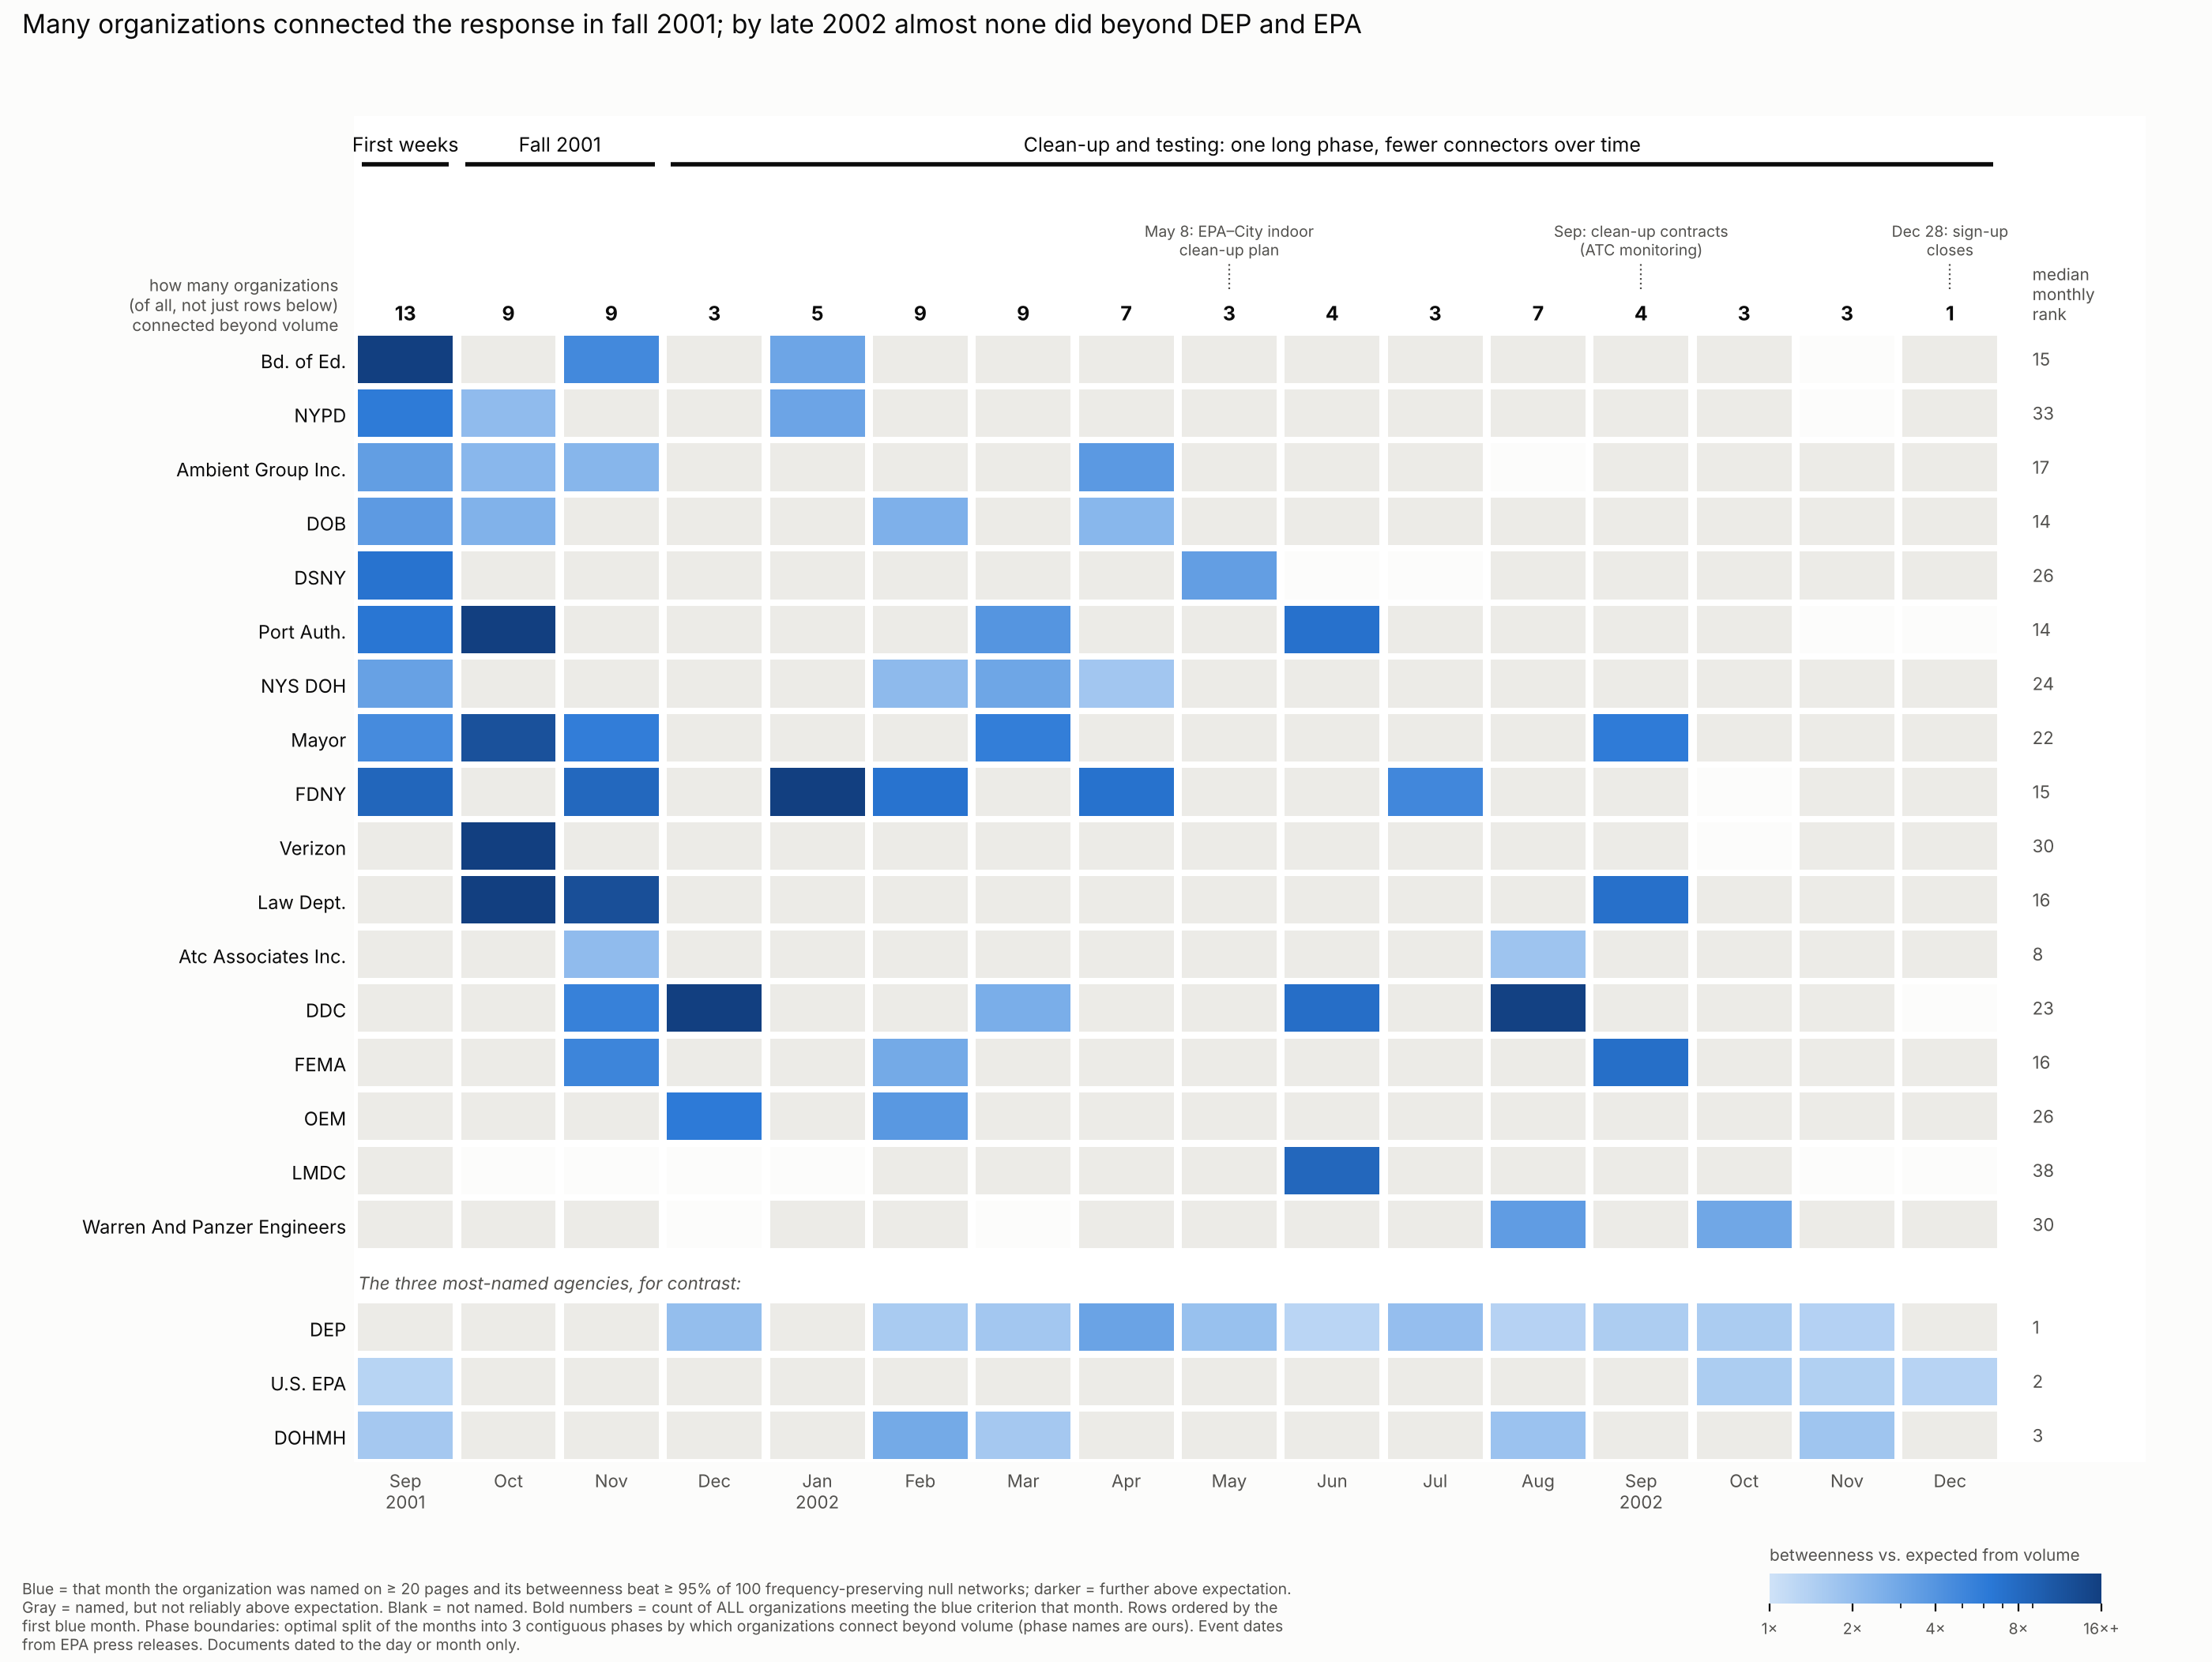

In [48]:
tm = temporal.run(prep)                                             # cached: outputs/network/temporal_100.csv
# phases from the data: optimal split of the months into contiguous phases by WHICH organizations connect beyond volume
# ("presence") or HOW FAR above expectation they are ("strength"); our phase names are attached afterwards
display(temporal.phase_table(tm).round(3))
phases = [(str(a), str(b), name) for (a, b), (_, _, name) in zip(temporal.data_phases(tm, 3), figures.PHASES)]
print("phases used in fig 6:", phases)
display(Image(filename=str(figures.relay_chart(tm, figures.RELAY_ROWS, figures.RELAY_ANCHORS, phases=phases)), width=1000))

In [49]:
# per month: organizations (>= 20 pages that month) whose betweenness beats >= 95% of that month's null networks
pd.set_option("display.max_colwidth", 200)
temporal.phase_brokers(tm)

,month,brokers_above_null
0,2001-09,NYC Board of Education (59.2x); Broadway Associates (15.3x); FDNY (8.5x); NYC Dept. of Sanitation (6.8x); Port Authority of NY & NJ (6.5x)
1,2001-10,Costar Realty Information Inc. (63.2x); Port Authority of NY & NJ (26.2x); NYC Law Department (19.1x); Verizon (16.8x); NYC Office of the Mayor (11.9x)
2,2001-11,NYC Law Department (12.2x); FDNY (8.2x); NYC Office of the Mayor (5.8x); NYC Dept. of Design and Construction (5.5x); FEMA (5.1x)
3,2001-12,NYC Dept. of Design and Construction (17.8x); NYC Office of Emergency Management (6.1x); NYC Dept. of Environmental Protection (2.0x)
4,2002-01,FDNY (18.8x); Milford Management Corp. (8.7x); Micromedex Inc. (8.6x); NYPD (3.1x); NYC Board of Education (3.1x)
5,2002-02,FDNY (6.8x); NYC Office of Emergency Management (3.8x); Related Management Co. (3.3x); NYC Dept. of Health and Mental Hygiene (2.9x); FEMA (2.8x)
6,2002-03,Bovis Lend Lease Lmb Inc. (5.9x); NYC Office of the Mayor (5.7x); Port Authority of NY & NJ (4.0x); Psc Analytical Services (3.8x); NYS Dept. of Health (3.0x)
7,2002-04,FDNY (7.0x); CDC (4.0x); Ambient Group Inc. (3.7x); NYC Dept. of Environmental Protection (3.2x); NYC Dept. of Buildings (2.3x)
8,2002-05,Plangraphics Inc. (9.2x); NYC Dept. of Sanitation (3.4x); NYC Dept. of Environmental Protection (1.9x)
9,2002-06,Lower Manhattan Development Corporation (8.4x); NYC Dept. of Design and Construction (7.5x); Port Authority of NY & NJ (7.1x); NYC Dept. of Environmental Protection (1.3x)


In [50]:
# two trajectories behind fig 6: rank, page share and observed/expected betweenness
traj = tm[tm["name"].isin(["NYC Law Department", "Atc Associates Inc.", "NYC Dept. of Environmental Protection"])]
traj.pivot_table(index="month", columns="name", values=["rank_betweenness", "page_share", "ratio_betweenness"]).round(2)

page_share                                                             rank_betweenness                                                            ratio_betweenness  \
name    Atc Associates Inc. NYC Dept. of Environmental Protection NYC Law Department Atc Associates Inc. NYC Dept. of Environmental Protection NYC Law Department Atc Associates Inc.   
month                                                                                                                                                                                   
2001-09                0.02                                  0.45               0.02                29.0                                   1.0               55.0                1.32   
2001-10                0.03                                  0.38               0.00                13.0                                   2.0               12.0                1.55   
2001-11                0.03                                  0.33               0.01                15.0                                   2.0               10.0                2.07   
2001-12                0.10                                  0.10               0.00                17.0                                   2.0               57.0                0.20   
2002-01                0.12                                  0.19               0.02                22.0                                   2.0               45.0                0.20   
2002-02                0.10                                  0.37               0.01                 8.0                                   1.0               26.0                0.62   
2002-03                0.12                                  0.35               0.01                12.0                                   1.0               18.0                0.23   
2002-04                0.15                                  0.31               0.02                10.0                                   1.0               22.0                0.20   
2002-05                0.14                                  0.31               0.04                 7.0                                   1.0               22.0                0.43   
2002-06                0.26                                  0.41               0.01                 4.0                                   2.0               23.0                0.34   
2002-07                0.18                                  0.48               0.01                 8.0                                   1.0               11.0                0.27   
2002-08                0.09                                  0.43               0.01                 4.0                                   1.0               15.0                1.77   
2002-09                0.39                                  0.50               0.01                 6.0                                   1.0                7.0                0.15   
2002-10                0.22                                  0.54               0.05                 5.0                                   1.0                8.0                0.40   
2002-11                0.12                                  0.47               0.04                 6.0                                   1.0                7.0                0.42   
2002-12                0.06                                  0.31               0.03                 6.0                                   2.0                9.0                1.80   

                                                                  
name    NYC Dept. of Environmental Protection NYC Law Department  
month                                                             
2001-09                                  0.98               0.57  
2001-10                                  0.40              19.13  
2001-11                                  0.69              12.23  
2001-12                                  1.98               0.00  
2002-01                         

In [51]:
# what are the Law Department's pages? document types from titles, per month (checked against the page sample below)
law_docs = temporal.law_department_documents(prep)
peak = [m for m in law_docs.index if str(m) in ("2001-10", "2001-11", "2002-09", "2002-10", "2002-11", "2002-12")]
display(law_docs)
(law_docs.loc[peak].sum() / law_docs.loc[peak].values.sum()).round(2).rename("share of pages in the peak months")

doc_type,document preservation / legal hold,emergency contract / procurement,legal correspondence / inquiry / claim,license agreement with a building owner,"other (reports, inspections, monitoring, misc.)"
month,,,,,
2001-09,13,5,1,34,45
2001-10,21,0,0,1,5
2001-11,0,24,2,0,4
2001-12,1,0,0,0,2
2002-01,0,2,0,4,50
2002-02,1,0,0,11,41
2002-03,3,7,1,4,46
2002-04,3,10,2,7,25
2002-05,5,57,15,21,37


doc_type
document preservation / legal hold                 0.10
emergency contract / procurement                   0.38
legal correspondence / inquiry / claim             0.03
license agreement with a building owner            0.14
other (reports, inspections, monitoring, misc.)    0.36
Name: share of pages in the peak months, dtype: float64

In [52]:
# a seeded sample of Law Department pages from those months, read by hand (notebook author's reading in 6f)
om_dated = temporal.dated_mentions(prep)
law_pages = om_dated[(om_dated["node_id"] == "agency:nyc-law") & om_dated["month"].astype(str).isin(map(str, peak))]
law_pages = law_pages.drop_duplicates(["doc_id", "page"]).sample(12, random_state=settings.SEED)
for r in law_pages.itertuples():
    txt = " ".join(str(pages_idx.loc[(r.doc_id, r.page), "text"]).split())
    k = max(txt.lower().find("counsel"), txt.lower().find("law"), 0)
    print(f"--- {r.month} {r.doc_id} p.{r.page} | {t['documents'].set_index('doc_id').loc[r.doc_id, 'title']}")
    print("   ", txt[max(0, k - 150):k + 220], "...\n")

--- 2002-10 NYC-WTC_000150621 p.6 | Emergency contract declaration, WTC-ARC, Oct 2002
    To: Michael A. Cardozo,'Corporation Counsel Attn: Steven Stein Cushman, Office of the Corporation Counsel Department of Environmental Protection To: William H. Thompson Jr., Comptroller Attn: Stanley Rosanoff, Office of the Comptroller’s Chief Engineer 59- ...

--- 2002-10 NYC-WTC_000154019 p.1 | Cover letter with Declaration of Emergency, Oct 2002
    Apartment ofEnvironmental PrOtertioin > ■ j, 59-17 (unction Boulevard' Flushing, New York I 11373-5108 j - "« 'll f u• Michael A. Cardozo Corporation Counsel 59 Maiden Lane New York, New York 10038 ATTN: Steven Stein Cushman s T*’ ChristopherO.Ward Corhmissionerl ''/".’J., I William H. Thompson, Jr. Comptroller Municipal Building One Centre Street New York, New York 1 ...

--- 2002-11 NYC-WTC_000099929 p.4 | License Agreement for debris cleanup, 75 Nassau Street, Nov 2002
    n the day and year which first appears above. &" &ftrr / Licensor By: Date

In [53]:
# hypothesis groups per month: share of the month's pages naming them, median null quantile of betweenness
gm = temporal.group_by_month(tm, metrics.hypothesis_views)
gm.pivot_table(index="month", columns="view", values=["page_share", "median_null_q_betweenness"]).round(2)

median_null_q_betweenness                                                                                                                                                     \
view         municipal regulatory private real estate: all private real estate: manual, incl. uncertain private real estate: manually confirmed public-health advocacy (exploratory)   
month                                                                                                                                                                                  
2001-09                      0.68                     0.50                                         0.50                                    0.50                                 0.50   
2001-10                      0.34                     0.47                                         0.14                                    0.02                                 0.79   
2001-11                      0.48                     0.44                                         0.38                                    0.38                                  NaN   
2001-12                      0.92                     0.28                                         0.18                                    0.18                                 0.86   
2002-01                      0.58                     0.53                                         1.00                                    0.94                                 0.40   
2002-02                      1.00                     0.50                                         0.50                                    0.64                                 0.36   
2002-03                      0.94                     0.50                                         0.50                                    0.50                                 0.36   
2002-04                      0.55                     0.64                                         0.74                                    0.50                                 0.50   
2002-05                      0.51                     0.50                                         0.50                                    0.50                                 0.34   
2002-06                      0.89                     0.50                                         0.45                                    0.44                                 0.40   
2002-07                      0.68                     0.50                                         0.50                                    0.50                                 0.11   
2002-08                      1.00                     0.50                                         0.50                                    0.50                                 0.50   
2002-09                      0.60                     0.50                                         0.41                                    0.41                                 0.50   
2002-10                      0.92                     0.46                                         0.46                                    0.46                                 0.62   
2002-11                      0.95                     0.45                                         0.45                                    0.50                                  NaN   
2002-12                      0.64                     0.28                                         0.18                                    0.28                                  NaN   

                  page_share                                                                                                                                                     
view    municipal regulatory private real estate: all private real estate: manual, incl. uncertain private real estate: manually confirmed public-health advocacy (exploratory)  
month                                                                                                                                                      

**Reading (6f).**
* **Raw rank is almost frozen.** DEP and EPA are #1 and #2 on betweenness in **every** month; monthly raw centrality mostly tracks who files the most paper.
* **Who connects beyond volume changes, and narrows.** The number of organizations that connect the response beyond their volume falls from 13 (September 2001) and 9 (October–November 2001) to 3–4 for most of the second half of 2002, and 1 in December 2002.
* **Phases from the data.** The optimal split of the months is not our choice of labels:
  * The strongest break in both profile definitions comes at the end of 2001 (November or December, depending on the definition), and September 2001 stands apart from everything after it.
  * 2002 is one long phase. There is no separate "routine testing" phase from October 2002, only a gradual decline, with a step down from May 2002, the month of the EPA–City indoor cleanup plan.
  * The 3-phase split by presence (September 2001 | October–November 2001 | December 2001–December 2002) is used in fig 6; the names are ours.
* **Who connects in each phase.**
  * First weeks: Board of Education (schools near the site), FDNY, Sanitation, NYPD, Port Authority.
  * Fall 2001: Port Authority, Verizon, Law Department, Mayor's Office, DDC, FEMA.
  * 2002: changing sets: FDNY, DDC, OEM, Port Authority, LMDC, Mayor's Office and NYS DOH appear in some months, with testing and engineering firms; by late 2002 only EPA, DEP and DOHMH, just above expectation.
* **What the Law Department's pages are.** Its betweenness rank rises from 55 (September 2001) to 7–9 (September–December 2002), and it connects beyond volume in October–November 2001 and September 2002. In its peak months:
  * 38% of its pages are emergency contracts or procurement: "Declarations of Emergency" for DEP's air-monitoring and cleanup contracts, sent to the Corporation Counsel; the first, dated 13 September 2001, declares the attack an emergency under the City Charter.
  * 14% are license agreements with building owners, approved "as to form" by the Corporation Counsel.
  * 10% are document preservation and legal-hold notices (from October 2001).
  * Only 3% are legal correspondence, inquiries or claims. One example: a November 2002 internal email asking whether DEP had been contacted by the Department of Justice, RAND or freedom-of-information requesters.
  * So the lawyers moved toward the center mainly through the **paperwork of emergency contracting and clean-up agreements**, not litigation. Whether that went with more liability language is a question for the H3 text analysis.
* **ATC Associates' rise (rank 29 → 4) is volume**, not brokerage: its page share grows from 2% to as much as 39% (September 2002, when it held the residential-cleanup monitoring contract), and its observed / expected betweenness is mostly below 1.
* The confirmed real-estate firms are visible mainly in September–October 2001 (8% → 5% of pages) and then nearly vanish.
* Caveat: ratios for organizations with few pages in a month are noisy, so the broker table requires ≥ 20 pages and ≥ 95% of null samples beaten.

### 6g. How is the network organized? Communities on the validated backbone

In [54]:
# consensus blocks: 100 Louvain runs, keep pairs that share a block in >= 50% of them, recluster until stable
membership, comm, _ = backbone.consensus_communities(G_bb, prep.node_info)
print(f"consensus over {settings.CONSENSUS_RUNS} Louvain runs: {comm.attrs['n_communities']} blocks, modularity "
      f"{comm.attrs['modularity']:.2f}, converged after {comm.attrs['iterations']} iteration(s)")
comm.round(2)

consensus over 100 Louvain runs: 132 blocks, modularity 0.60, converged after 1 iteration(s)


,community,size,stability,top_members,agencies
0,0,199,1.00,Century Realty Inc.; Maiden Lane Associates LLC; Cedar Management Corp.; Broad Street Co.; Morgan Guaranty Trust Co.; Broad LLC,0
1,1,56,0.88,U.S. EPA; Emsl Analytical; Atc Associates Inc.; ATSDR; NYC Board of Education; FEMA,5
2,2,49,0.92,NIOSH; OSHA; Akrf Inc.; Jlc Environmental Consultants Inc.; Collegiate Church Corp.; Jlc Laboratory,2
3,3,48,0.99,NYC Office of Emergency Management; FDNY; NYPD; Port Authority of NY & NJ; Verizon; NYC Dept. of Design and Construction,13
4,4,37,0.88,NYC Dept. of Sanitation; NYC Dept. of Health and Mental Hygiene; NYS Dept. of Health; CDC; NYC Dept. of Environmental Protection; Athenica Environmental Services Inc.,7
5,5,25,0.90,Kiss Construction Inc.; Trio Asbestos Removal Corp.; Safeway Environmental Corp.; Asbestos Removal Corp.; Lvi Environmental Services Inc.; Air Tech Lab Inc.,0
6,6,19,1.00,Civil Engineering; Science Engineering; Quality Assurance Technical Support Laboratory; Merck Research Laboratory; Assurance Technical Support Laboratory It Corp.; Some Engineering,1
7,7,12,1.00,Durante Son Inc.; M And M Realty Associates; South William Street Associates; South Street Seafood Corp.; Sciame Development Inc.; Front Street LLC,0
8,8,11,1.00,Ultimate Realty LLC; Whiterose Artists Corp.; John Street Holdings LLC; Monpike Corp.; White Rose Artists Corp.; Fine Arts Developmental Laboratory,0
9,9,10,1.00,Epic LLC; Liberty LLC; Name Liberty LLC; Ets Construction Inc.; Name Hillman Environmental Co.; Arnold S Warwick And Co.,0


In [55]:
# Louvain is a heuristic: check that the blocks do not depend on the random seed
stab, stab_pairs = backbone.community_stability(G_bb, prep.node_info, [
    ("NIOSH", "OSHA"), ("NYC Dept. of Environmental Protection", "NYC Dept. of Health and Mental Hygiene"),
    ("NYC Office of Emergency Management", "FDNY"), ("NYC Office of Emergency Management", "NYC Office of the Mayor"),
    ("U.S. EPA", "NYC Dept. of Environmental Protection")])
display(stab.round(2).to_frame("value").T, stab_pairs.round(2))
# what is each block about? the most distinctive words in the titles of the documents behind its validated ties
terms = backbone.block_title_terms(sup["evidence"], e_val[e_val["validated_bonferroni"]], membership,
                                   t["documents"], comm["community"].head(6))
display(terms)

,runs,ari_median,ari_min
value,20.0,0.96,0.89


,pair,same_block_share
0,NIOSH + OSHA,0.65
1,NYC Dept. of Environmental Protection + NYC Dept. of Health and Mental Hygiene,1.00
2,NYC Office of Emergency Management + FDNY,1.00
3,NYC Office of Emergency Management + NYC Office of the Mayor,1.00
4,U.S. EPA + NYC Dept. of Environmental Protection,0.00


,community,documents,terms,share_with_top_term
0,0,74,"exterior, license, cleanup, survey, agreement, warren",0.189189
1,1,3687,"fiber, analysis, wipe, results, sampling, school",0.196094
2,2,1182,"ambient, monitoring, results, chain, custody, sampling",0.213198
3,3,1696,"change, order, cost, construction, mayor, work",0.324292
4,4,3415,"inspection, wipe, facade, visual, environmental, invoice",0.191801
5,5,47,"emergency, declaration, press, release, contract, contractor",0.170213


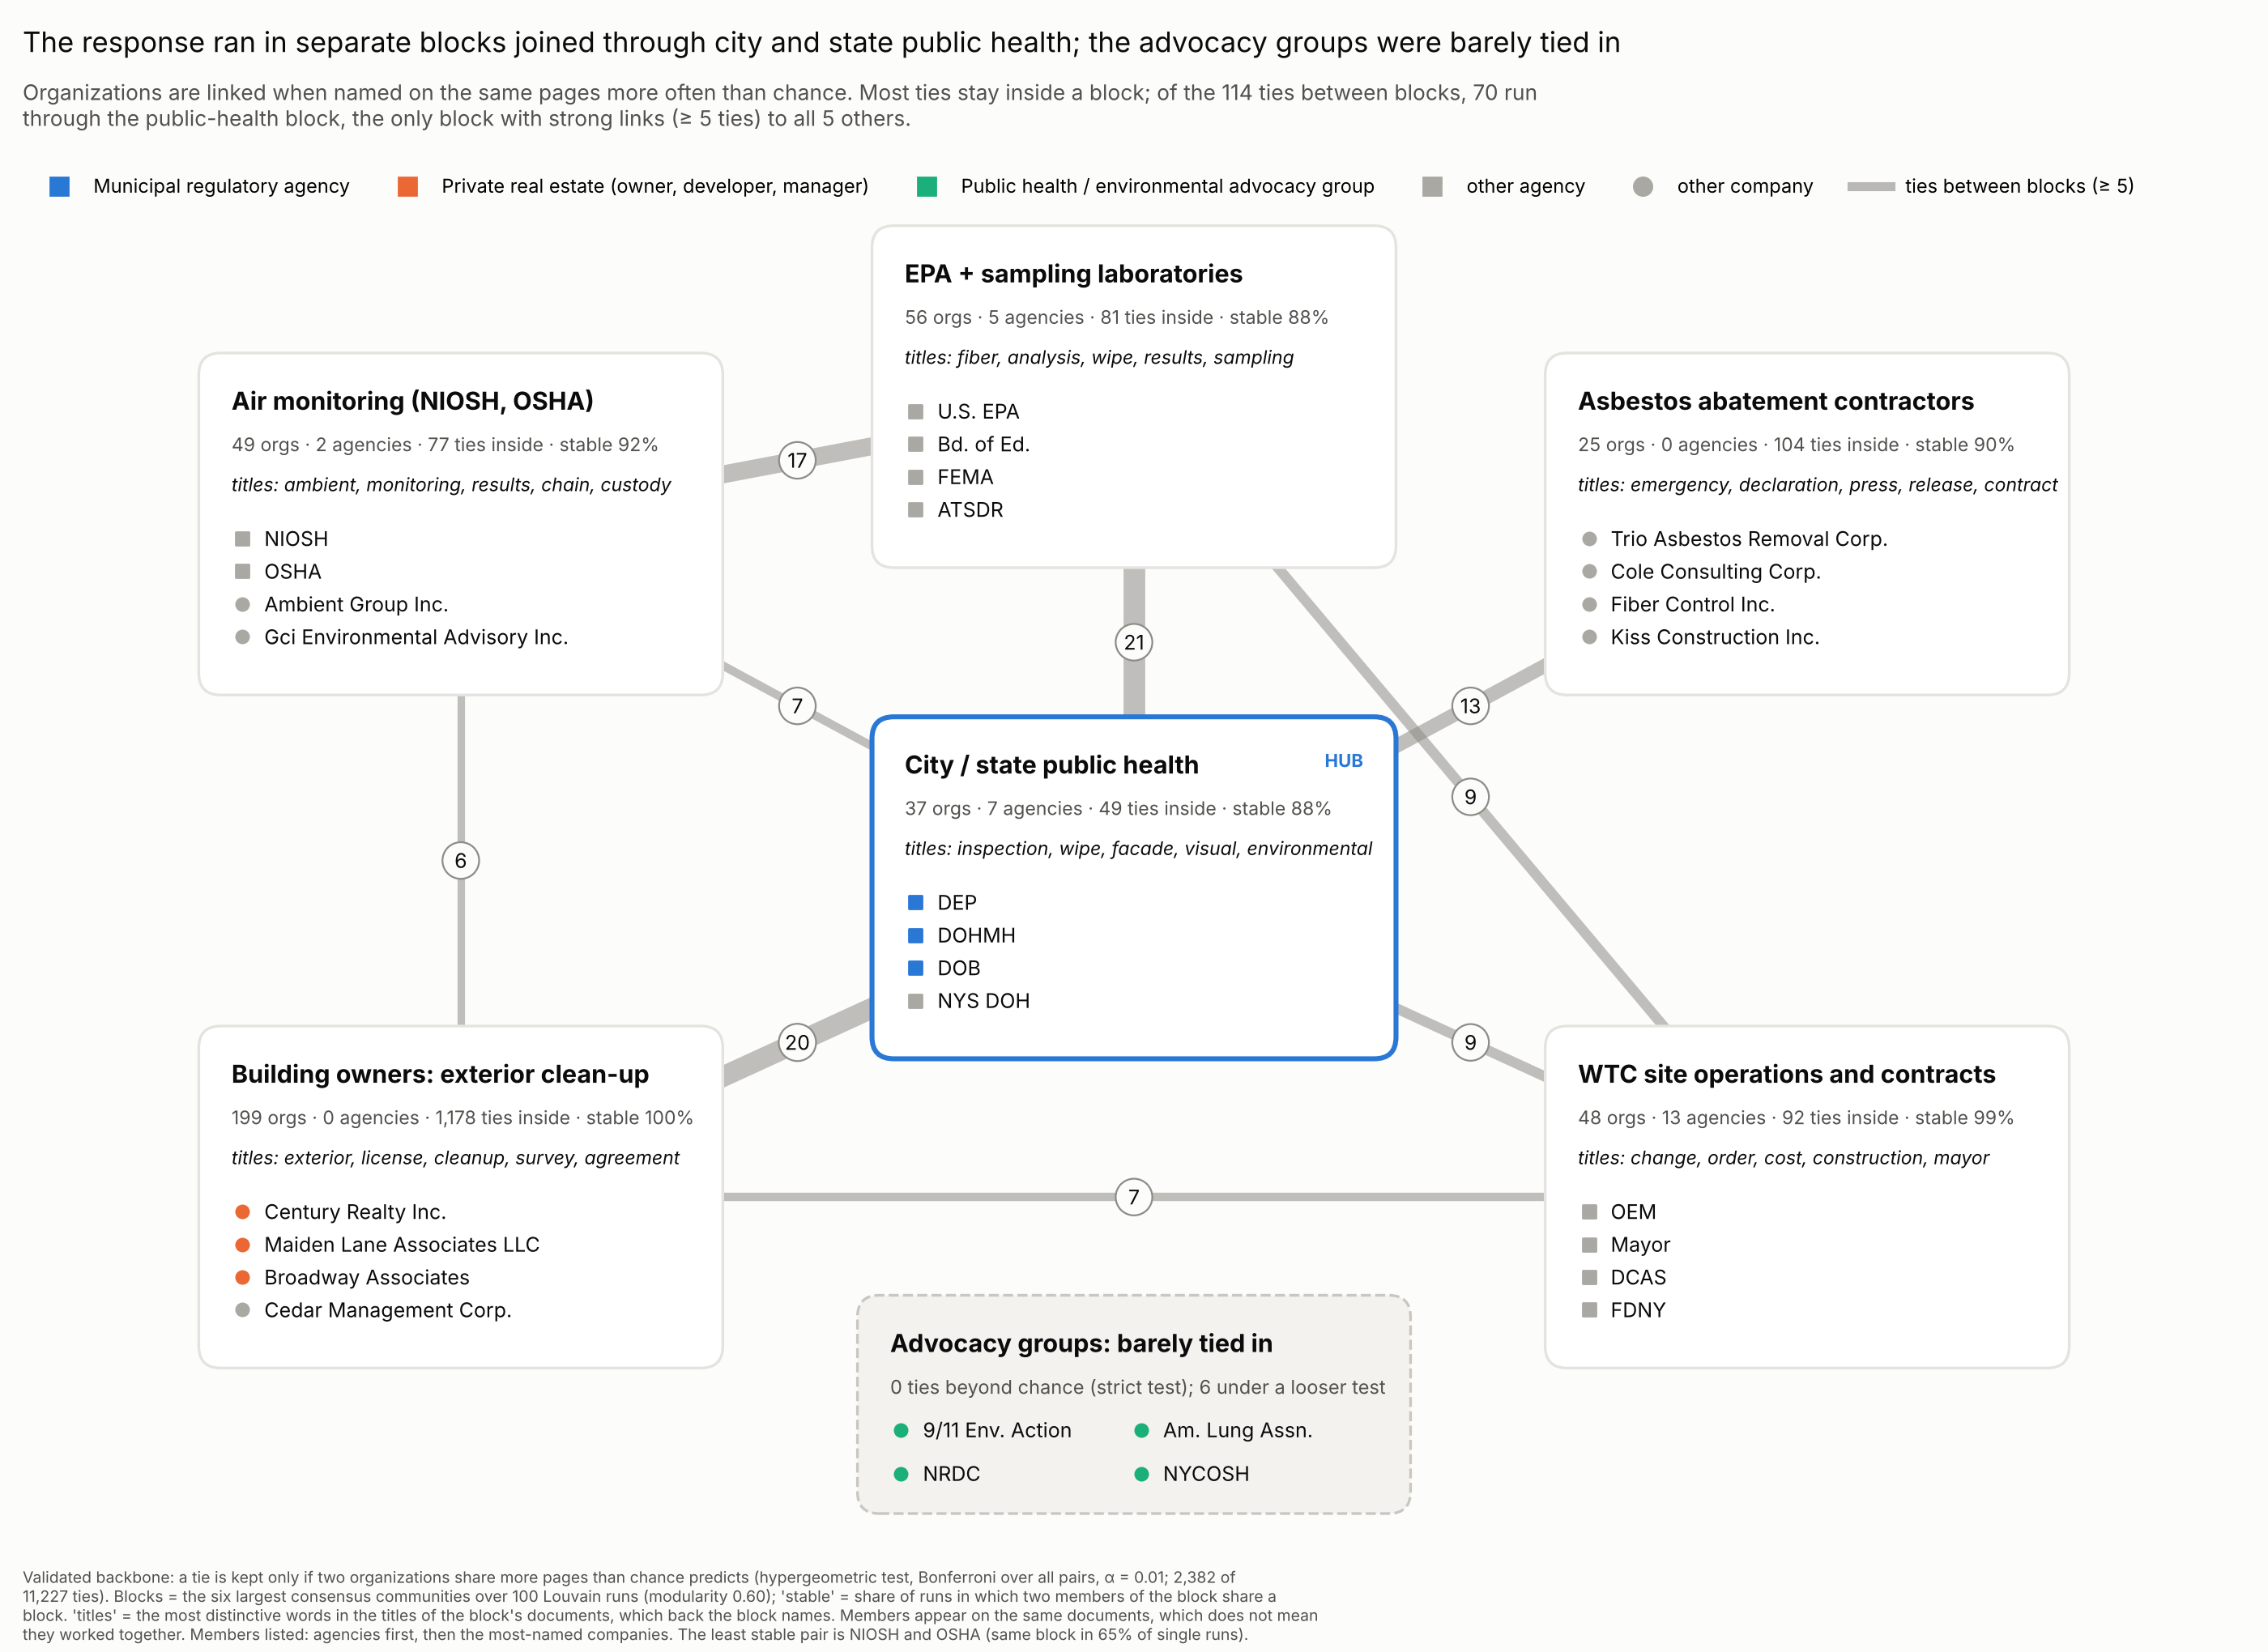

In [56]:
adv_names = list(prep.node_info.loc[prep.node_info["group"] == "public_health_advocacy", "name"])
note = (f"The least stable pair is NIOSH and OSHA (same block in "
        f"{stab_pairs.set_index('pair').loc['NIOSH + OSHA', 'same_block_share']:.0%} of single runs).")
display(Image(filename=str(figures.backbone_blocks(
    G_bb, membership, prep.node_info, adv_names,
    terms={r.community: ", ".join(r.terms.split(", ")[:5]) for r in terms.itertuples()},
    stability=dict(zip(comm["community"], comm["stability"])),
    adv_ties_loose=int(rules.set_index("rule").at["validated_fdr", "advocacy_ties"]), unstable_note=note)), width=1000))

**Reading (6g).** The validated backbone is strongly modular (modularity ≈ 0.60), and its blocks do not depend on the random seed: the consensus over 100 Louvain runs converges at once and matches a single run almost exactly. Single runs agree with each other at a median adjusted Rand index of 0.96. Each block's members share a block in 88–100% of runs; the least stable pair is NIOSH and OSHA (65%).

The block names are checked against what their documents are about (most distinctive title words):
1. **Building owners: exterior clean-up** (about 200 nodes, 1,178 ties inside, no agency). Titles: *exterior, license, cleanup, survey, agreement*. These are DEP's exterior building clean-up program: owners appear in DEP's files because DEP licensed the clean-up of their facades.
2. **EPA + sampling laboratories** (EPA, Board of Education, FEMA, ATSDR, labs). Titles: *fiber, analysis, wipe, results, sampling, school*.
3. **Air monitoring (NIOSH, OSHA) and consultants.** Titles: *monitoring, results, chain of custody, sampling*.
4. **WTC site operations and contracts** (OEM, Mayor's Office, DCAS, FDNY, NYPD, Port Authority, Verizon, DDC). Titles: *change order, cost, construction*. This replaces our earlier name "emergency coordination": its documents are mostly site contracts and costs.
5. **Asbestos abatement contractors.** Titles: *emergency declaration, contract*.
6. **City / state public health** (DEP, DOHMH, DOB, NYS DOH, DSNY, CDC). Titles: *inspection, wipe, facade, visual*. This is the **hub**: 70 of the 114 validated ties between the six blocks run through it, and it is the only block with strong links (≥ 5 ties) to all five others.

The advocacy groups belong to none of them. Members of a block appear on the same documents (forms, lists, reports), which does not mean they worked together.

## 7. Figures

outputs/figures/network/fig10_backbone_blocks.png


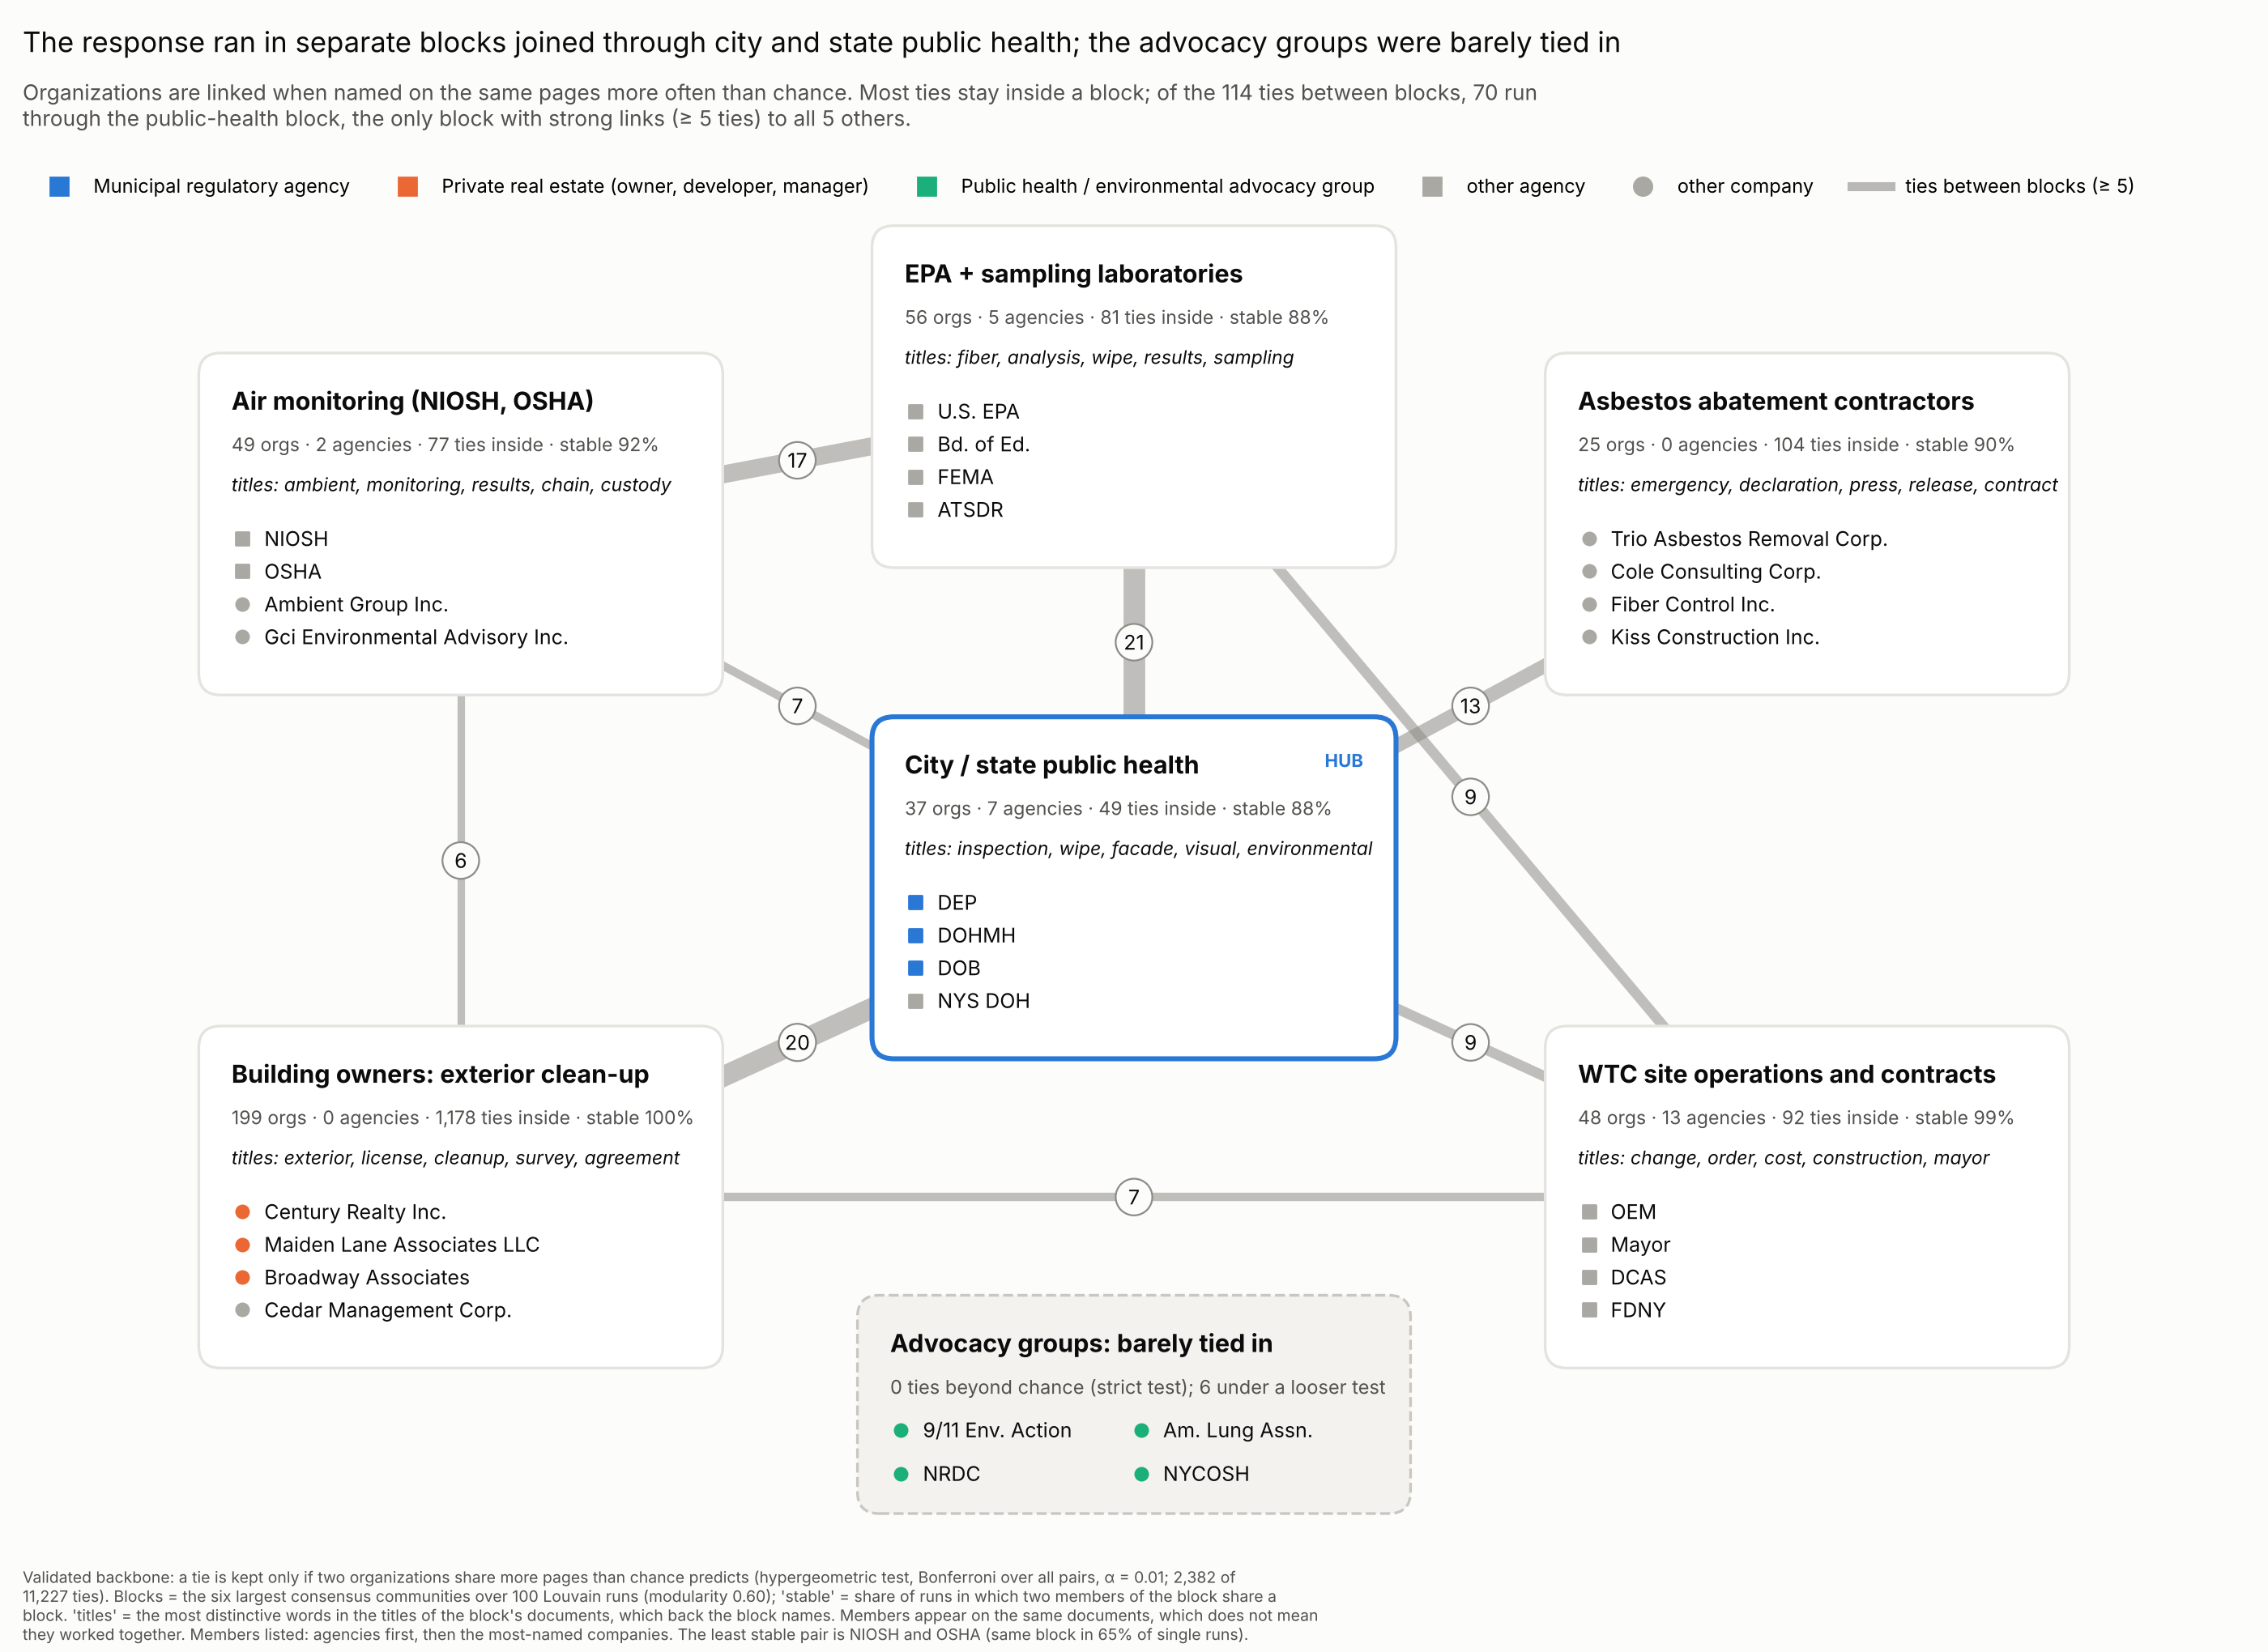

outputs/figures/network/fig1_top_centrality.png


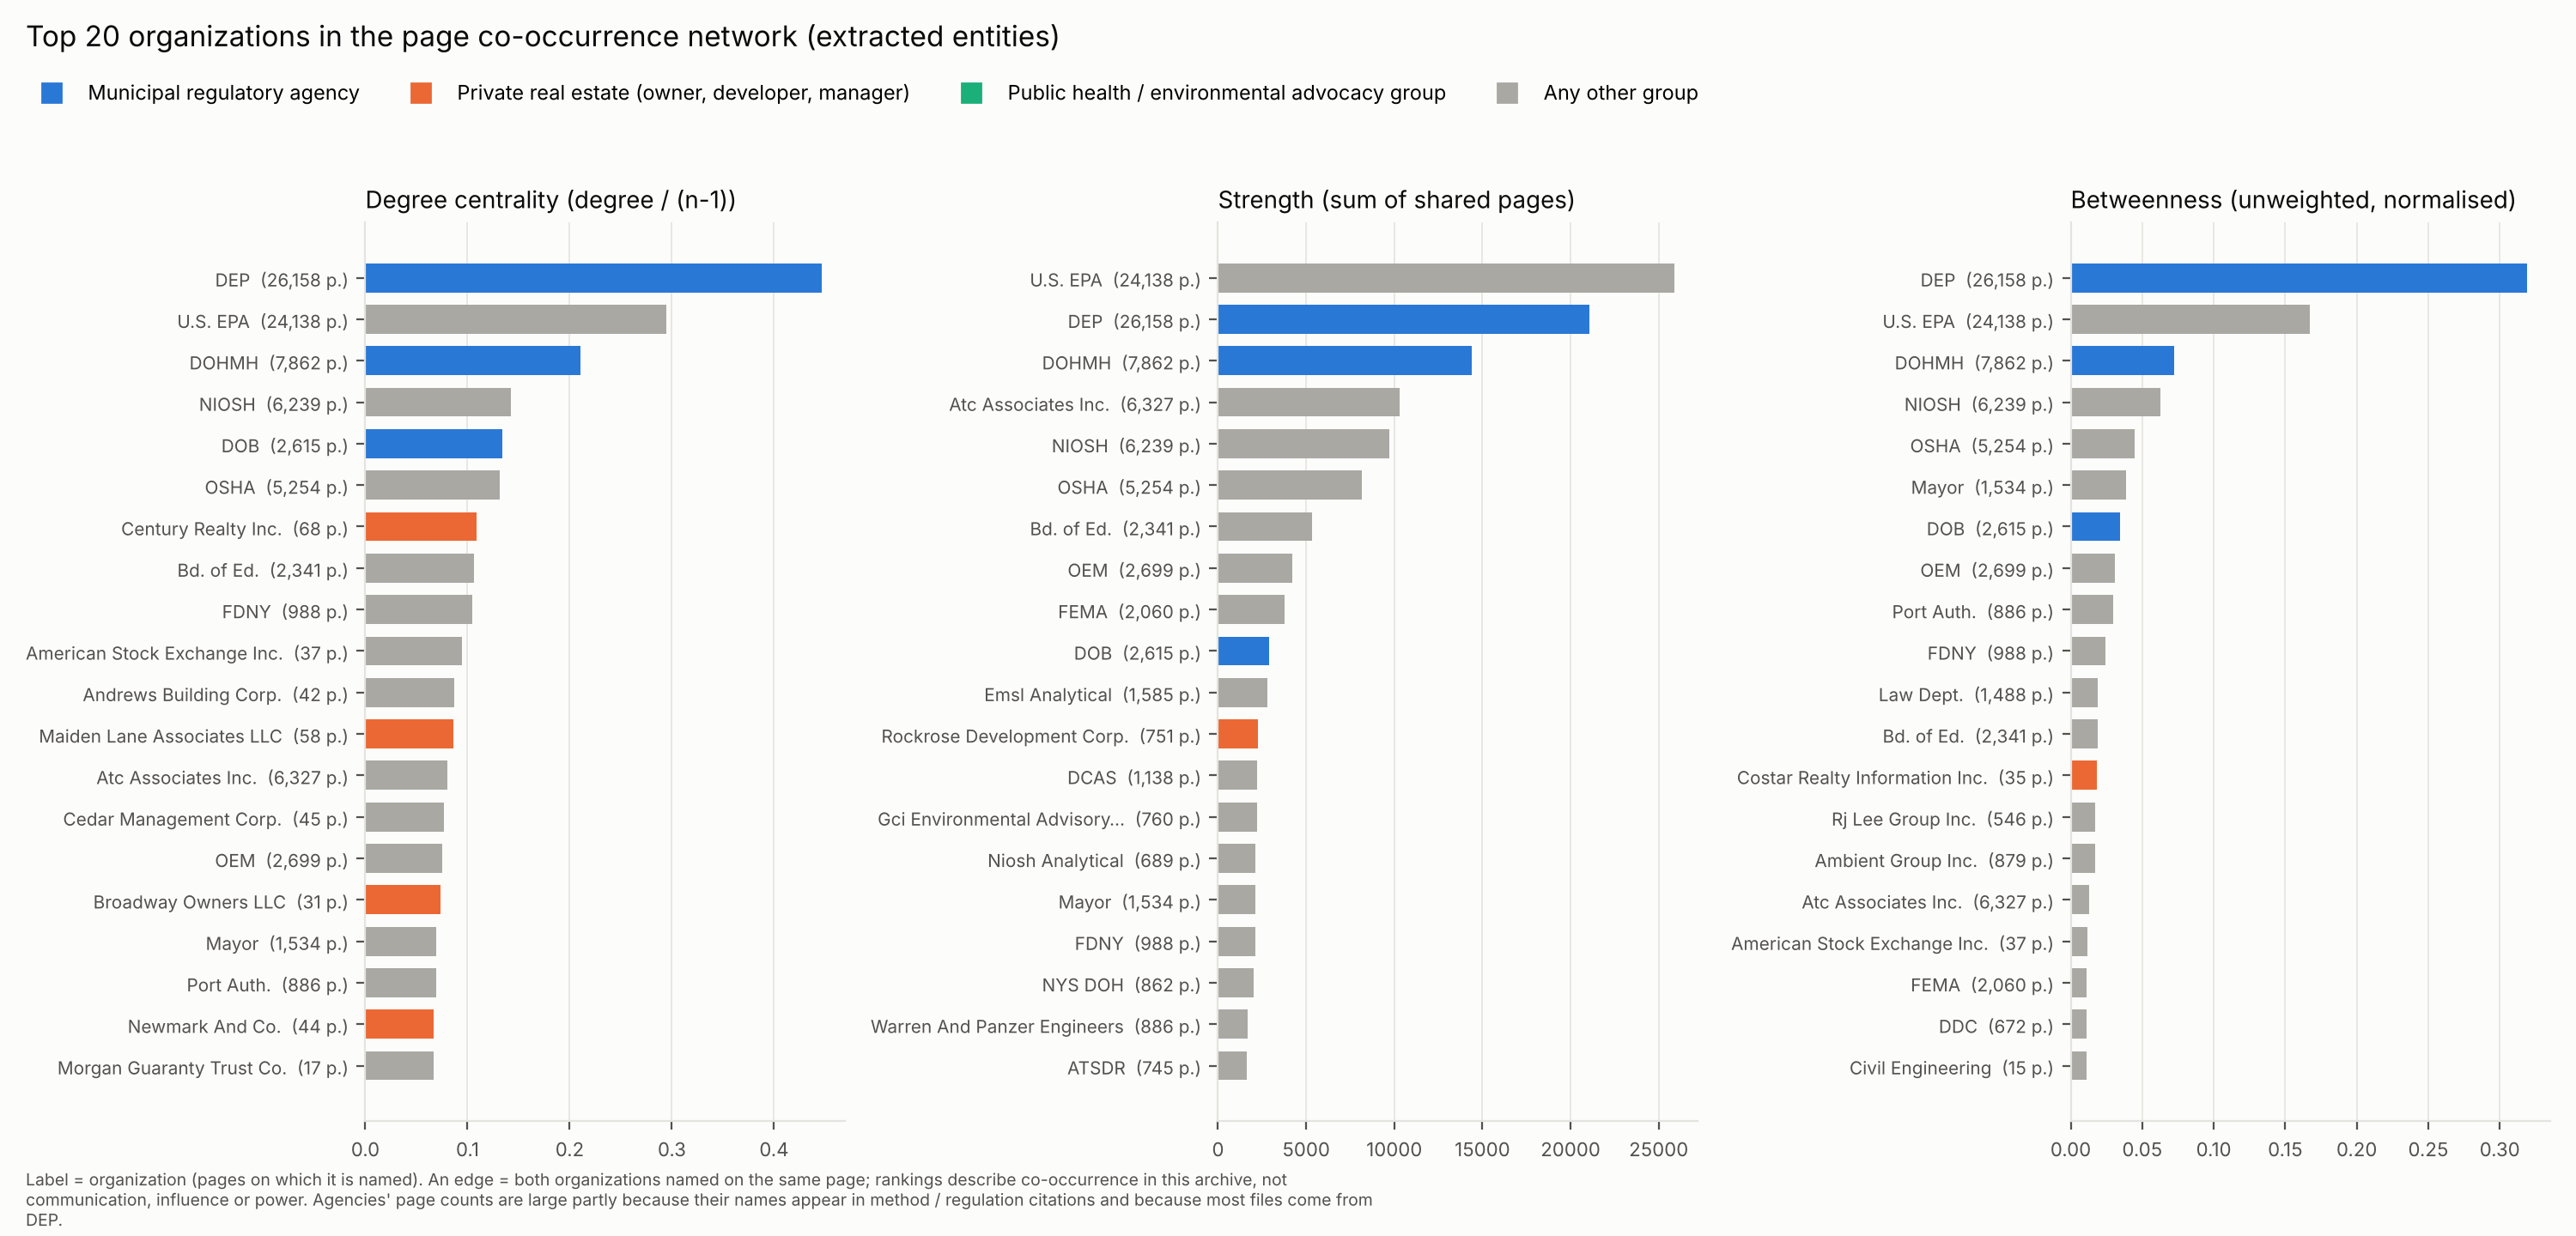

outputs/figures/network/fig2_hypothesis_groups.png


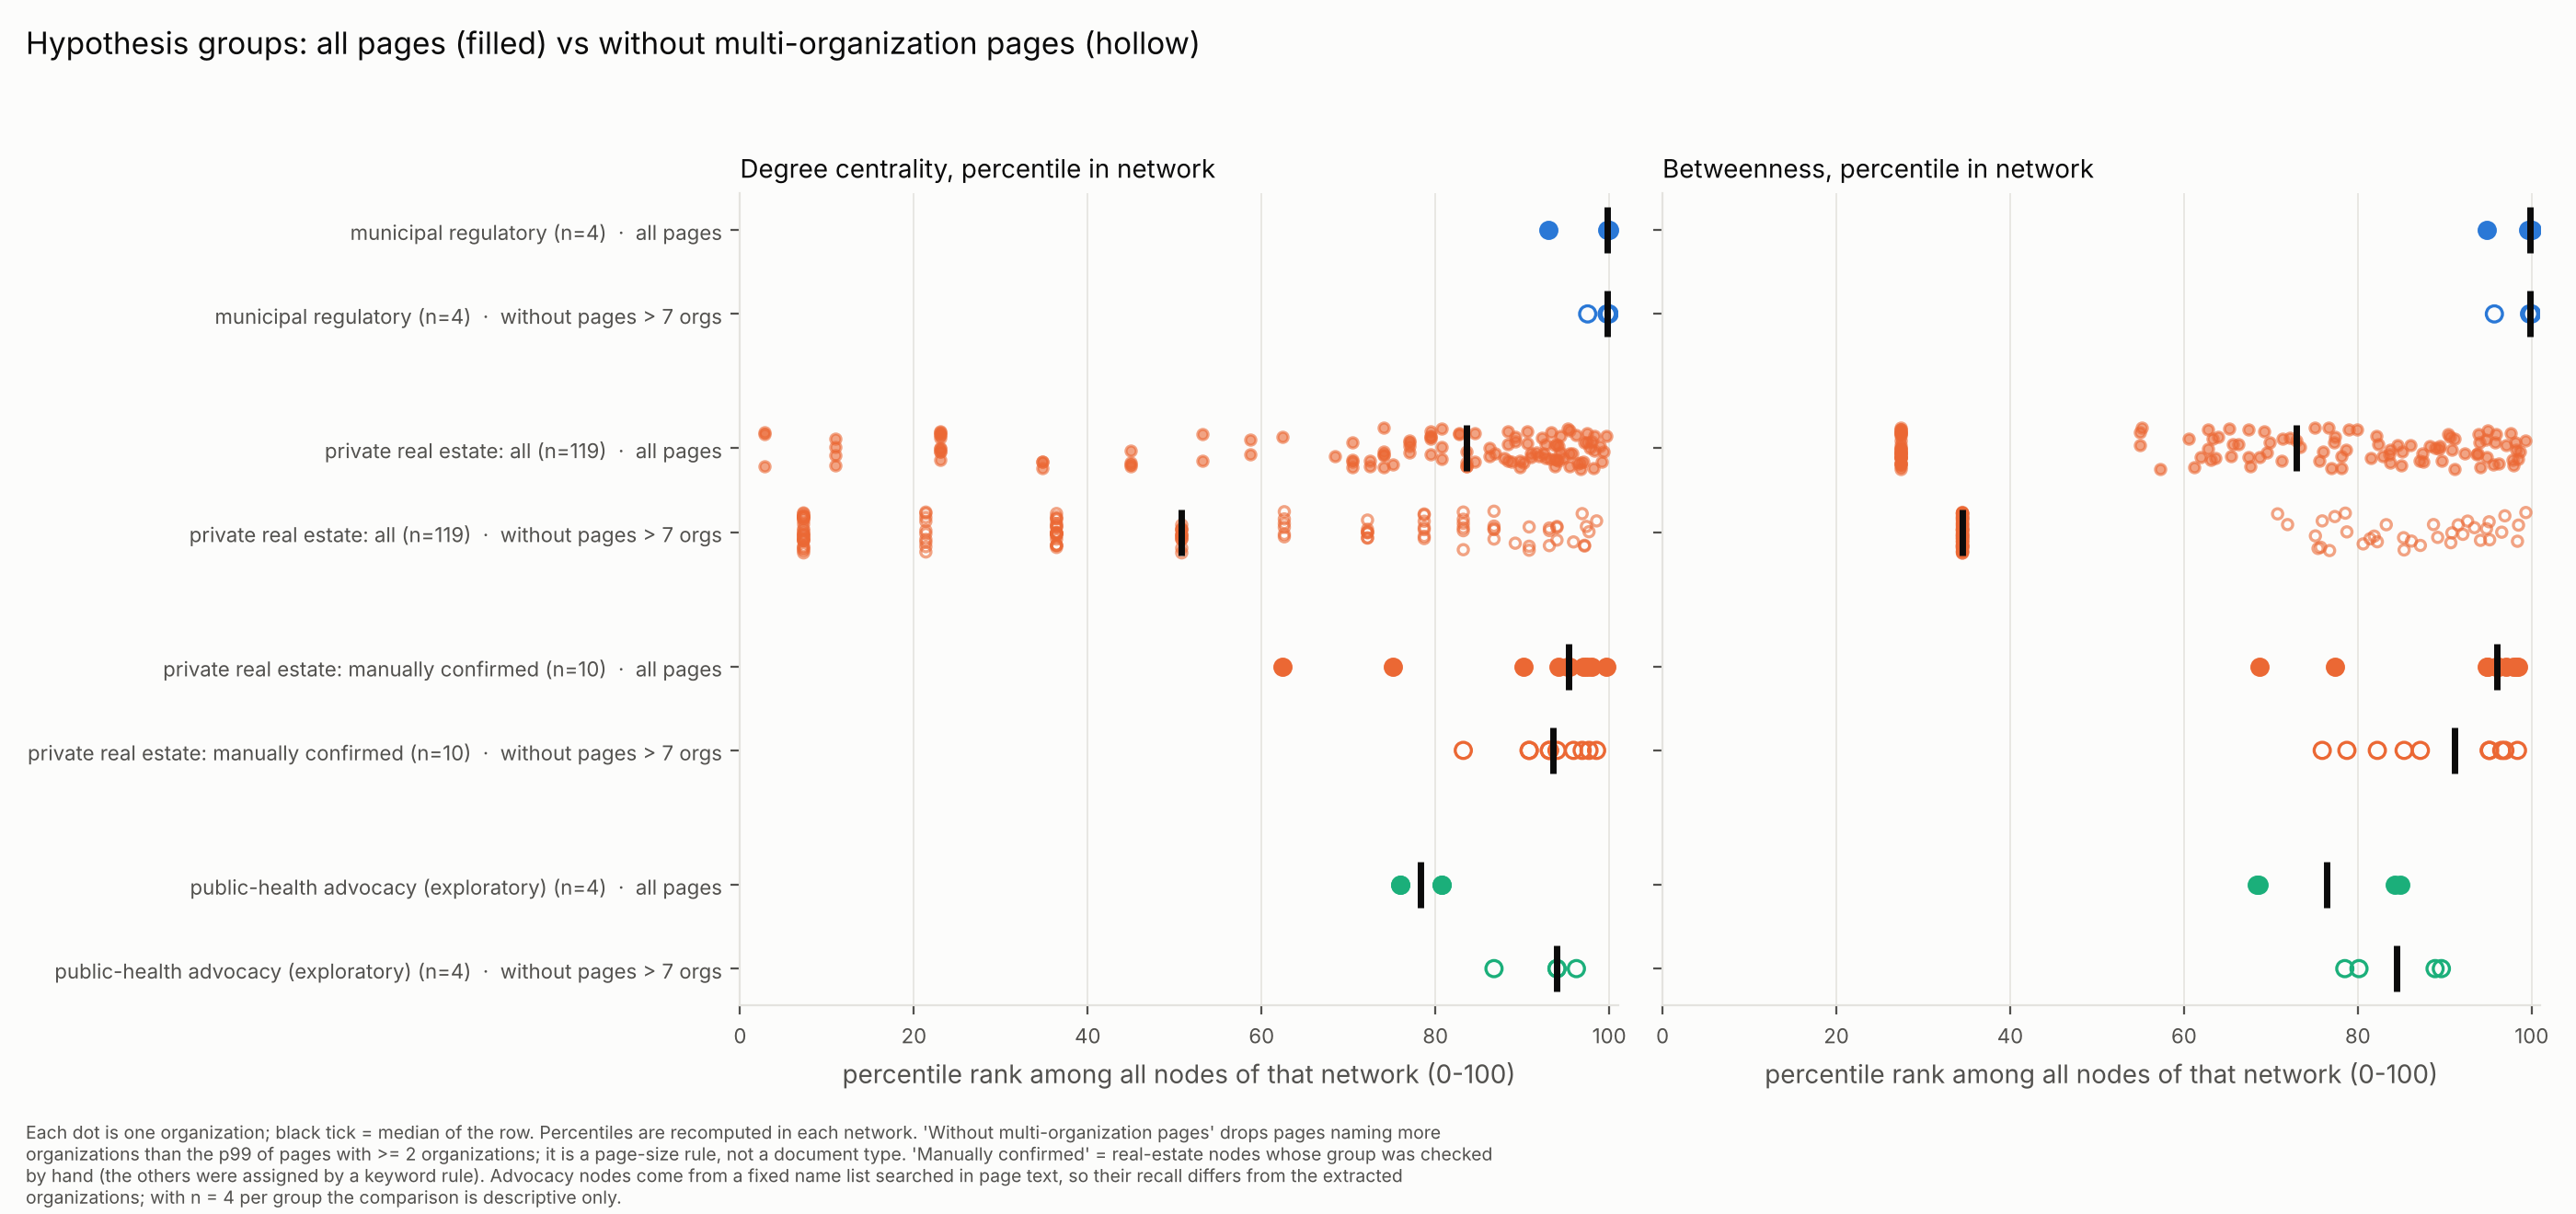

outputs/figures/network/fig3_frequency_vs_degree.png


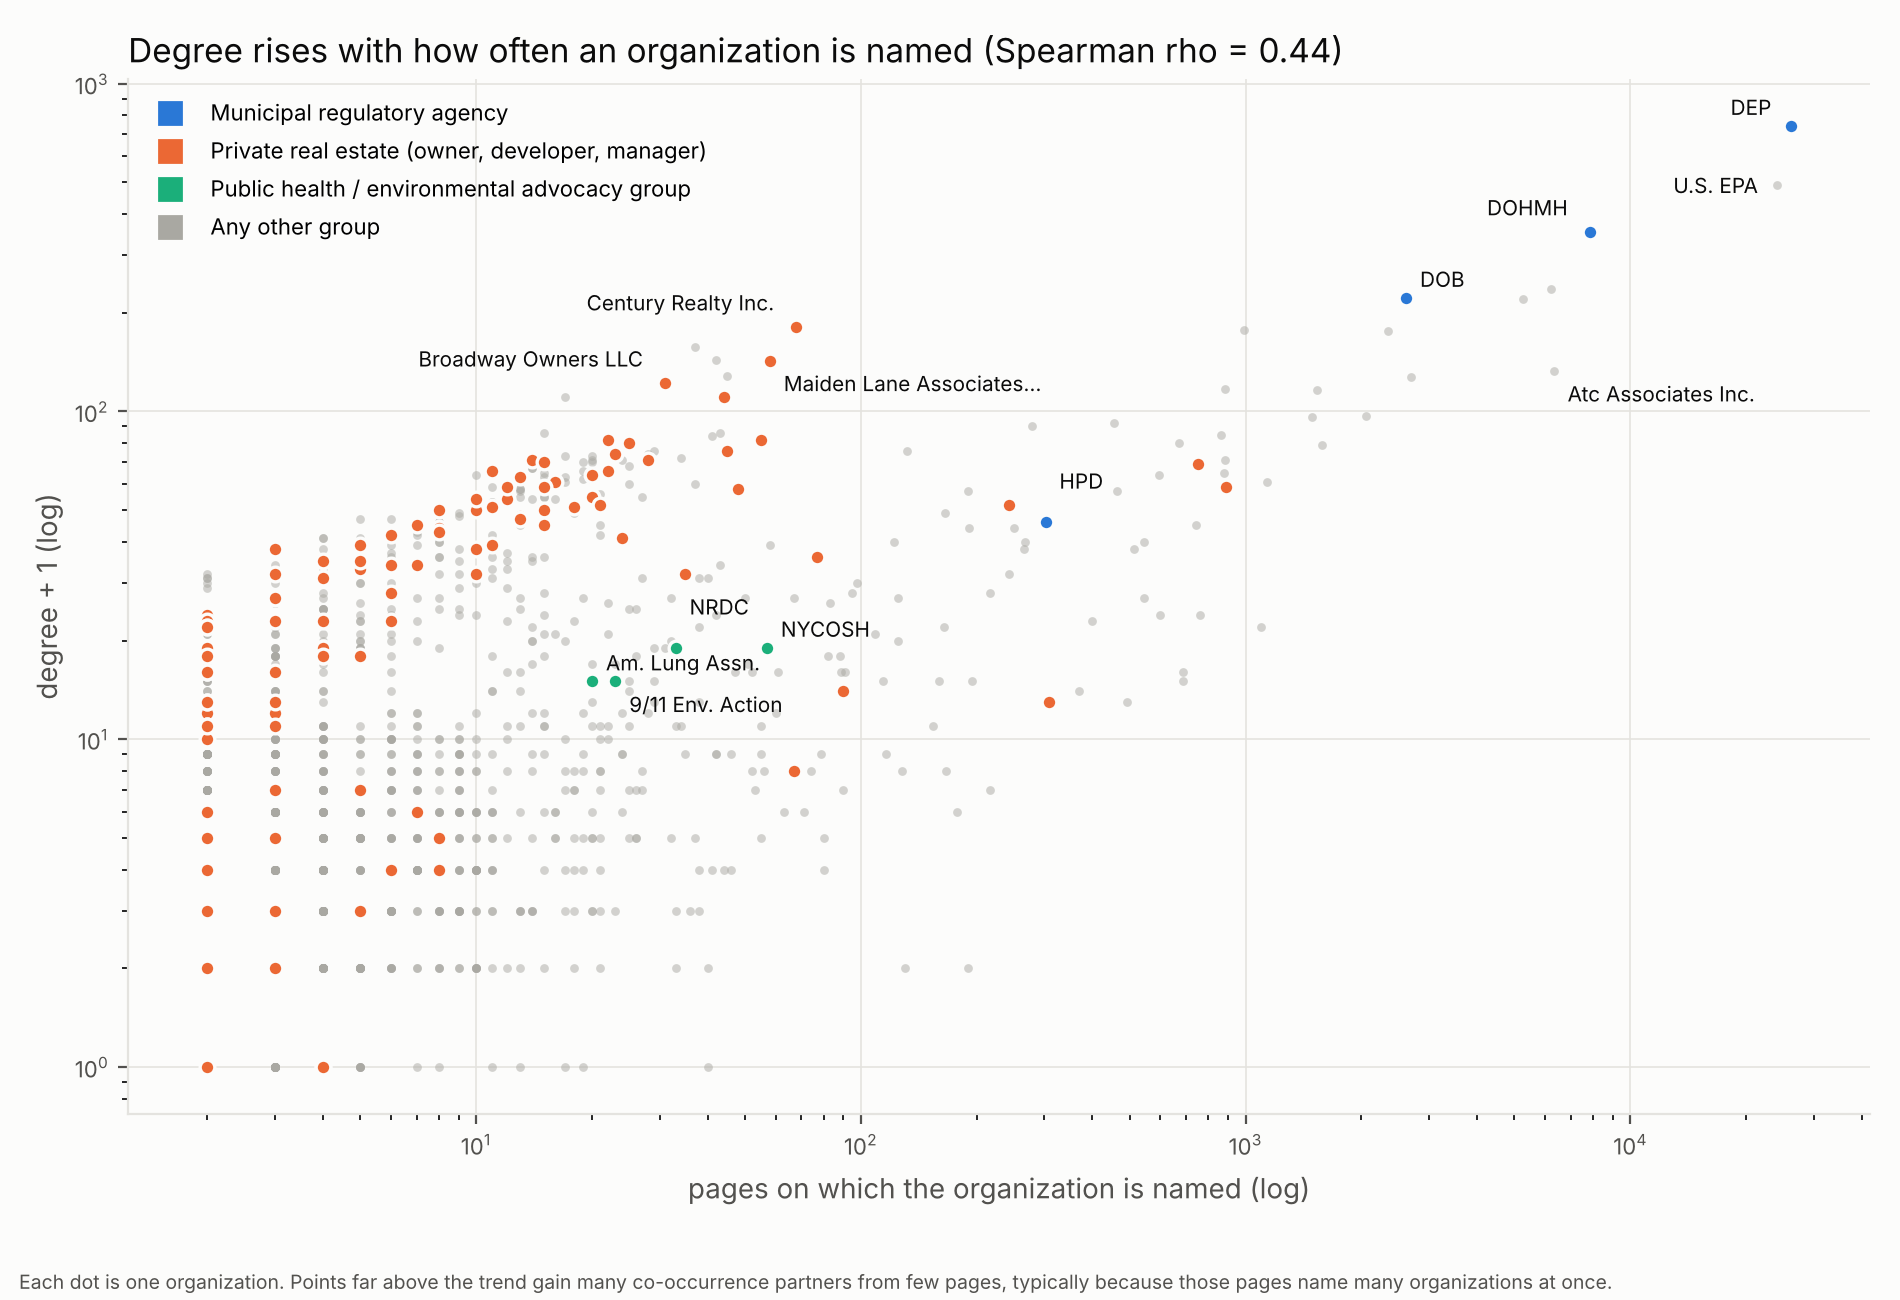

outputs/figures/network/fig4_network_subgraph.png


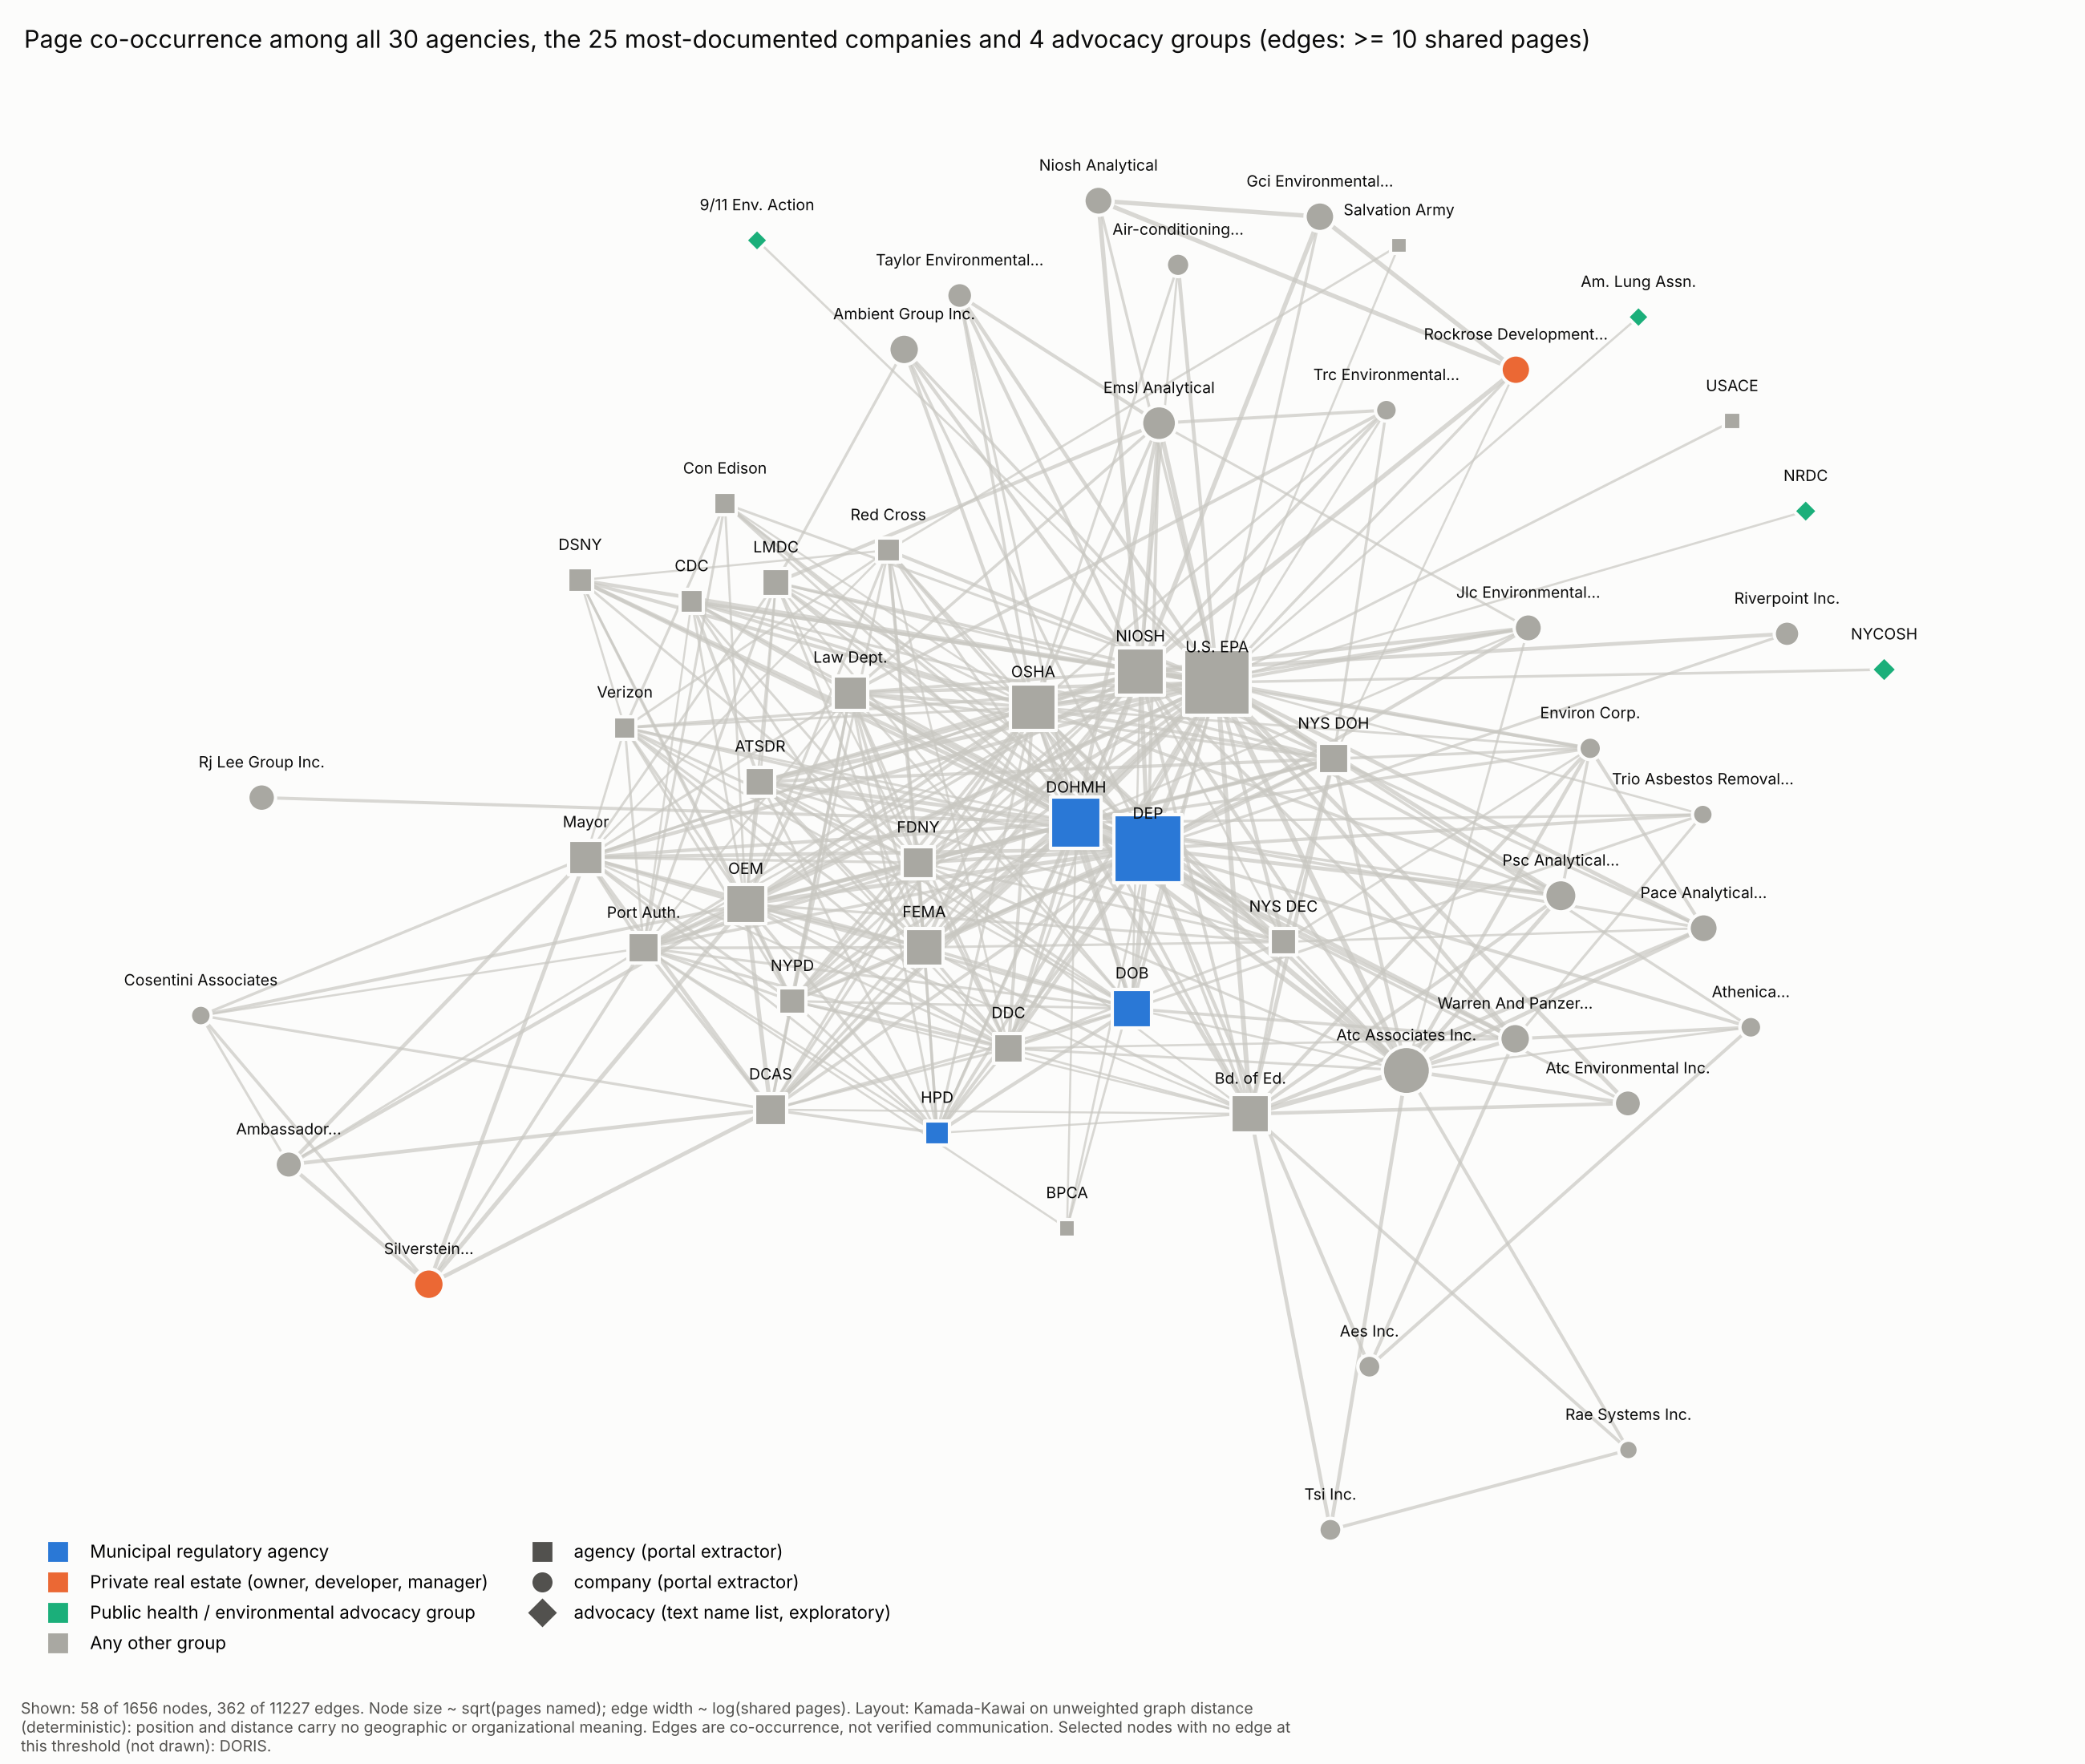

outputs/figures/network/fig5_observed_vs_null.png


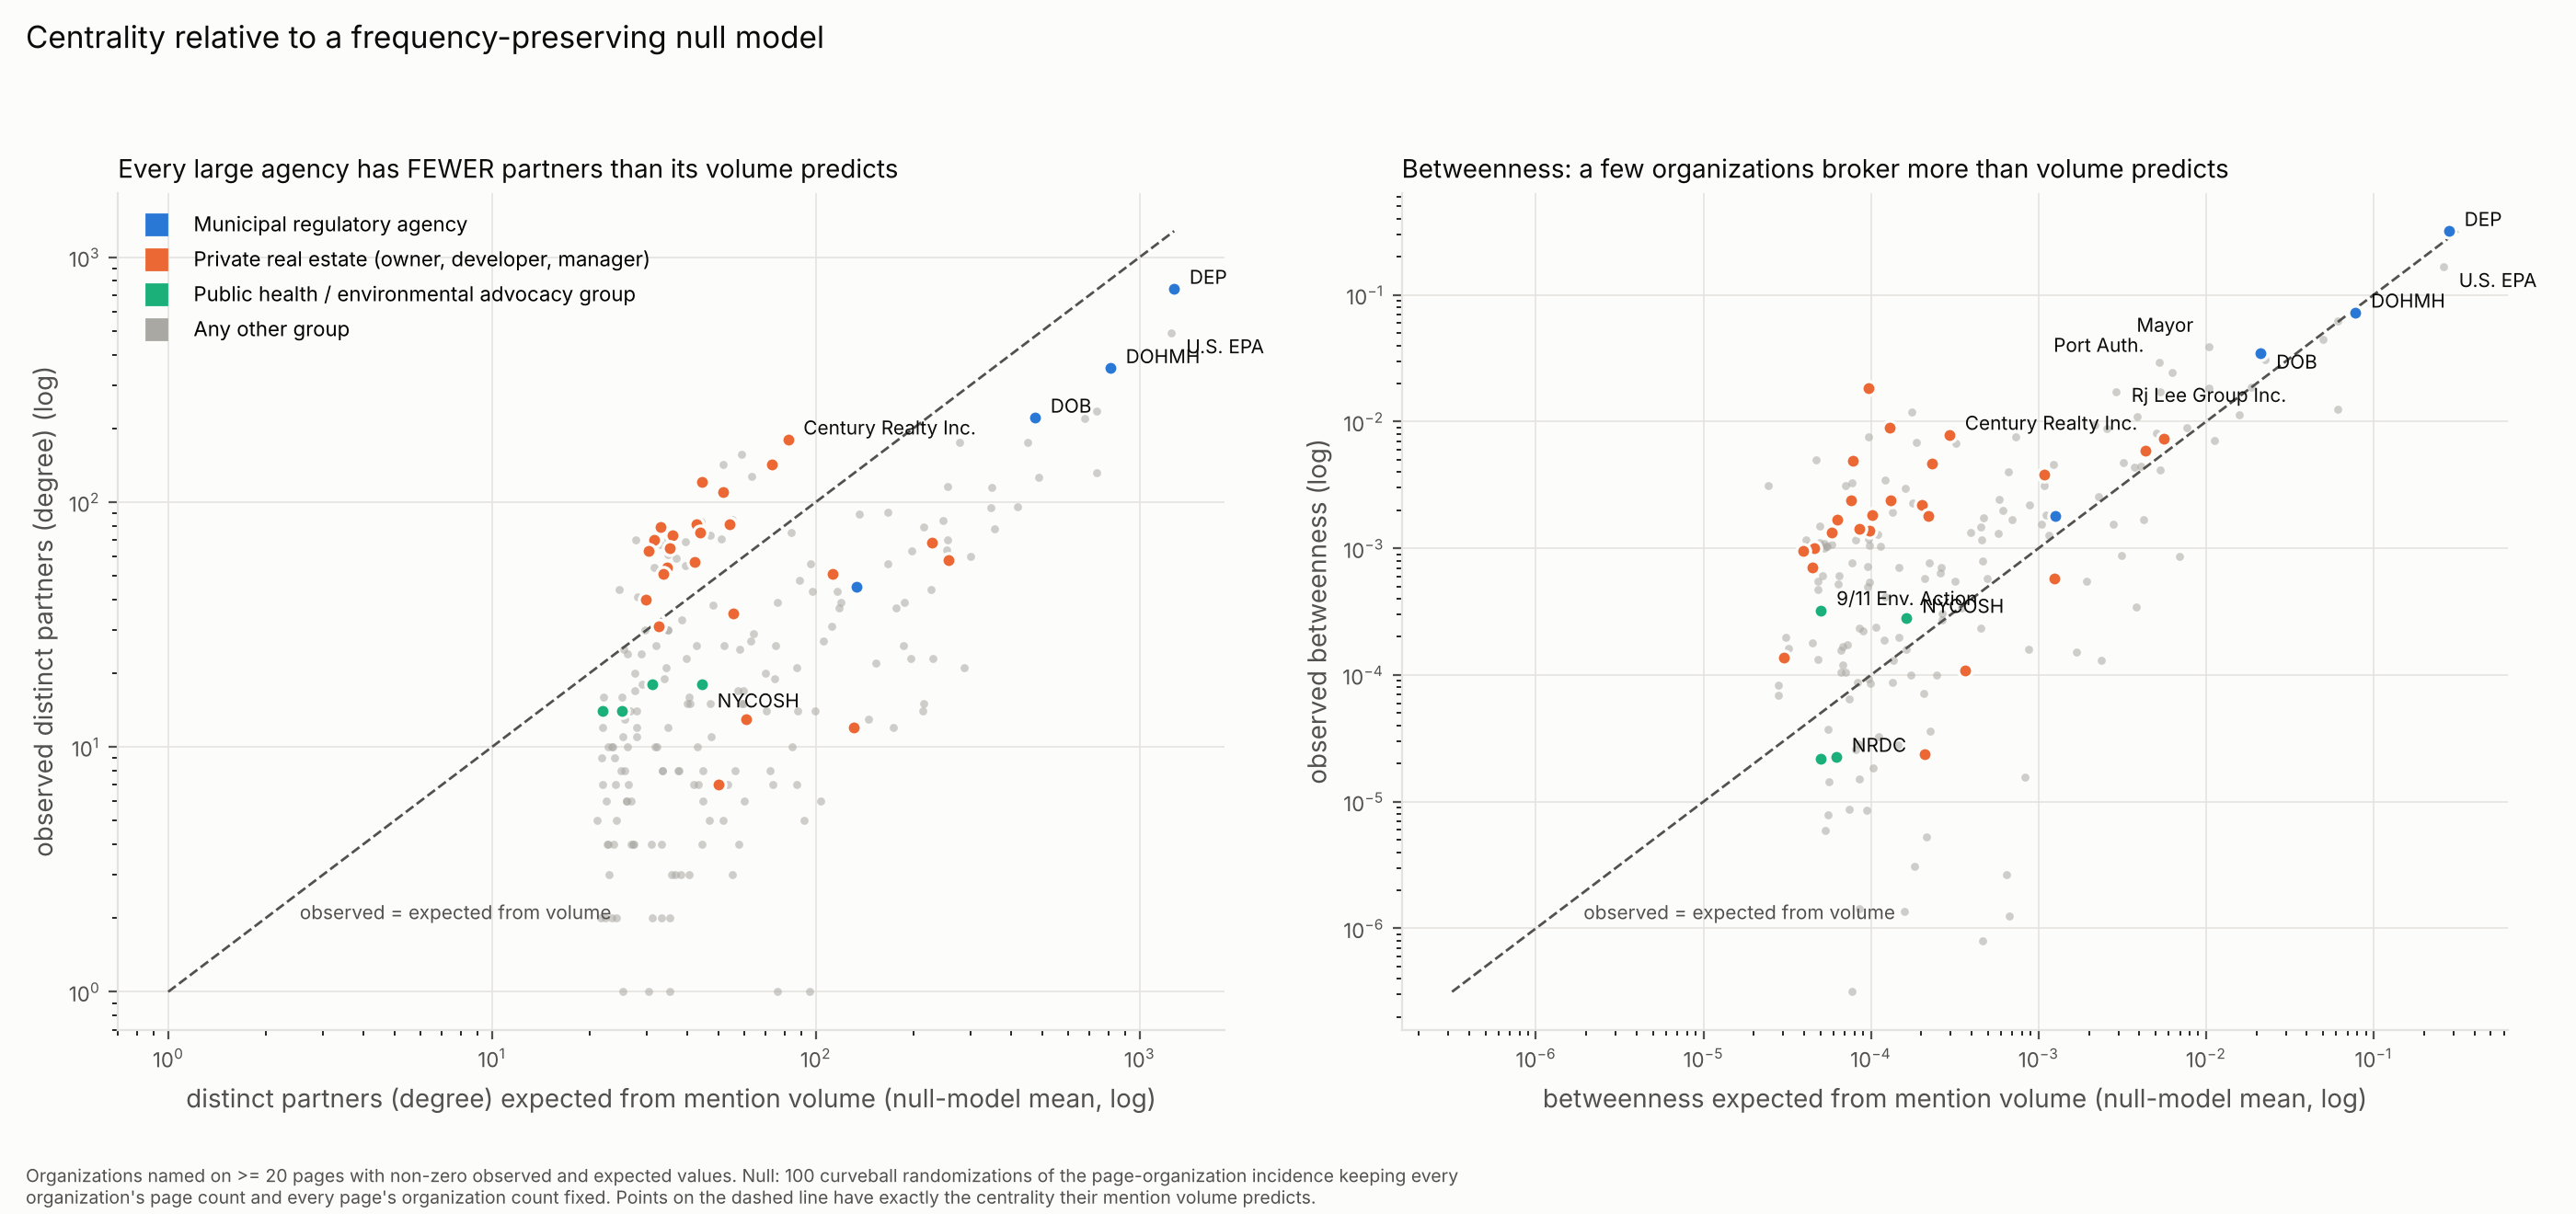

outputs/figures/network/fig6_monthly_relay.png


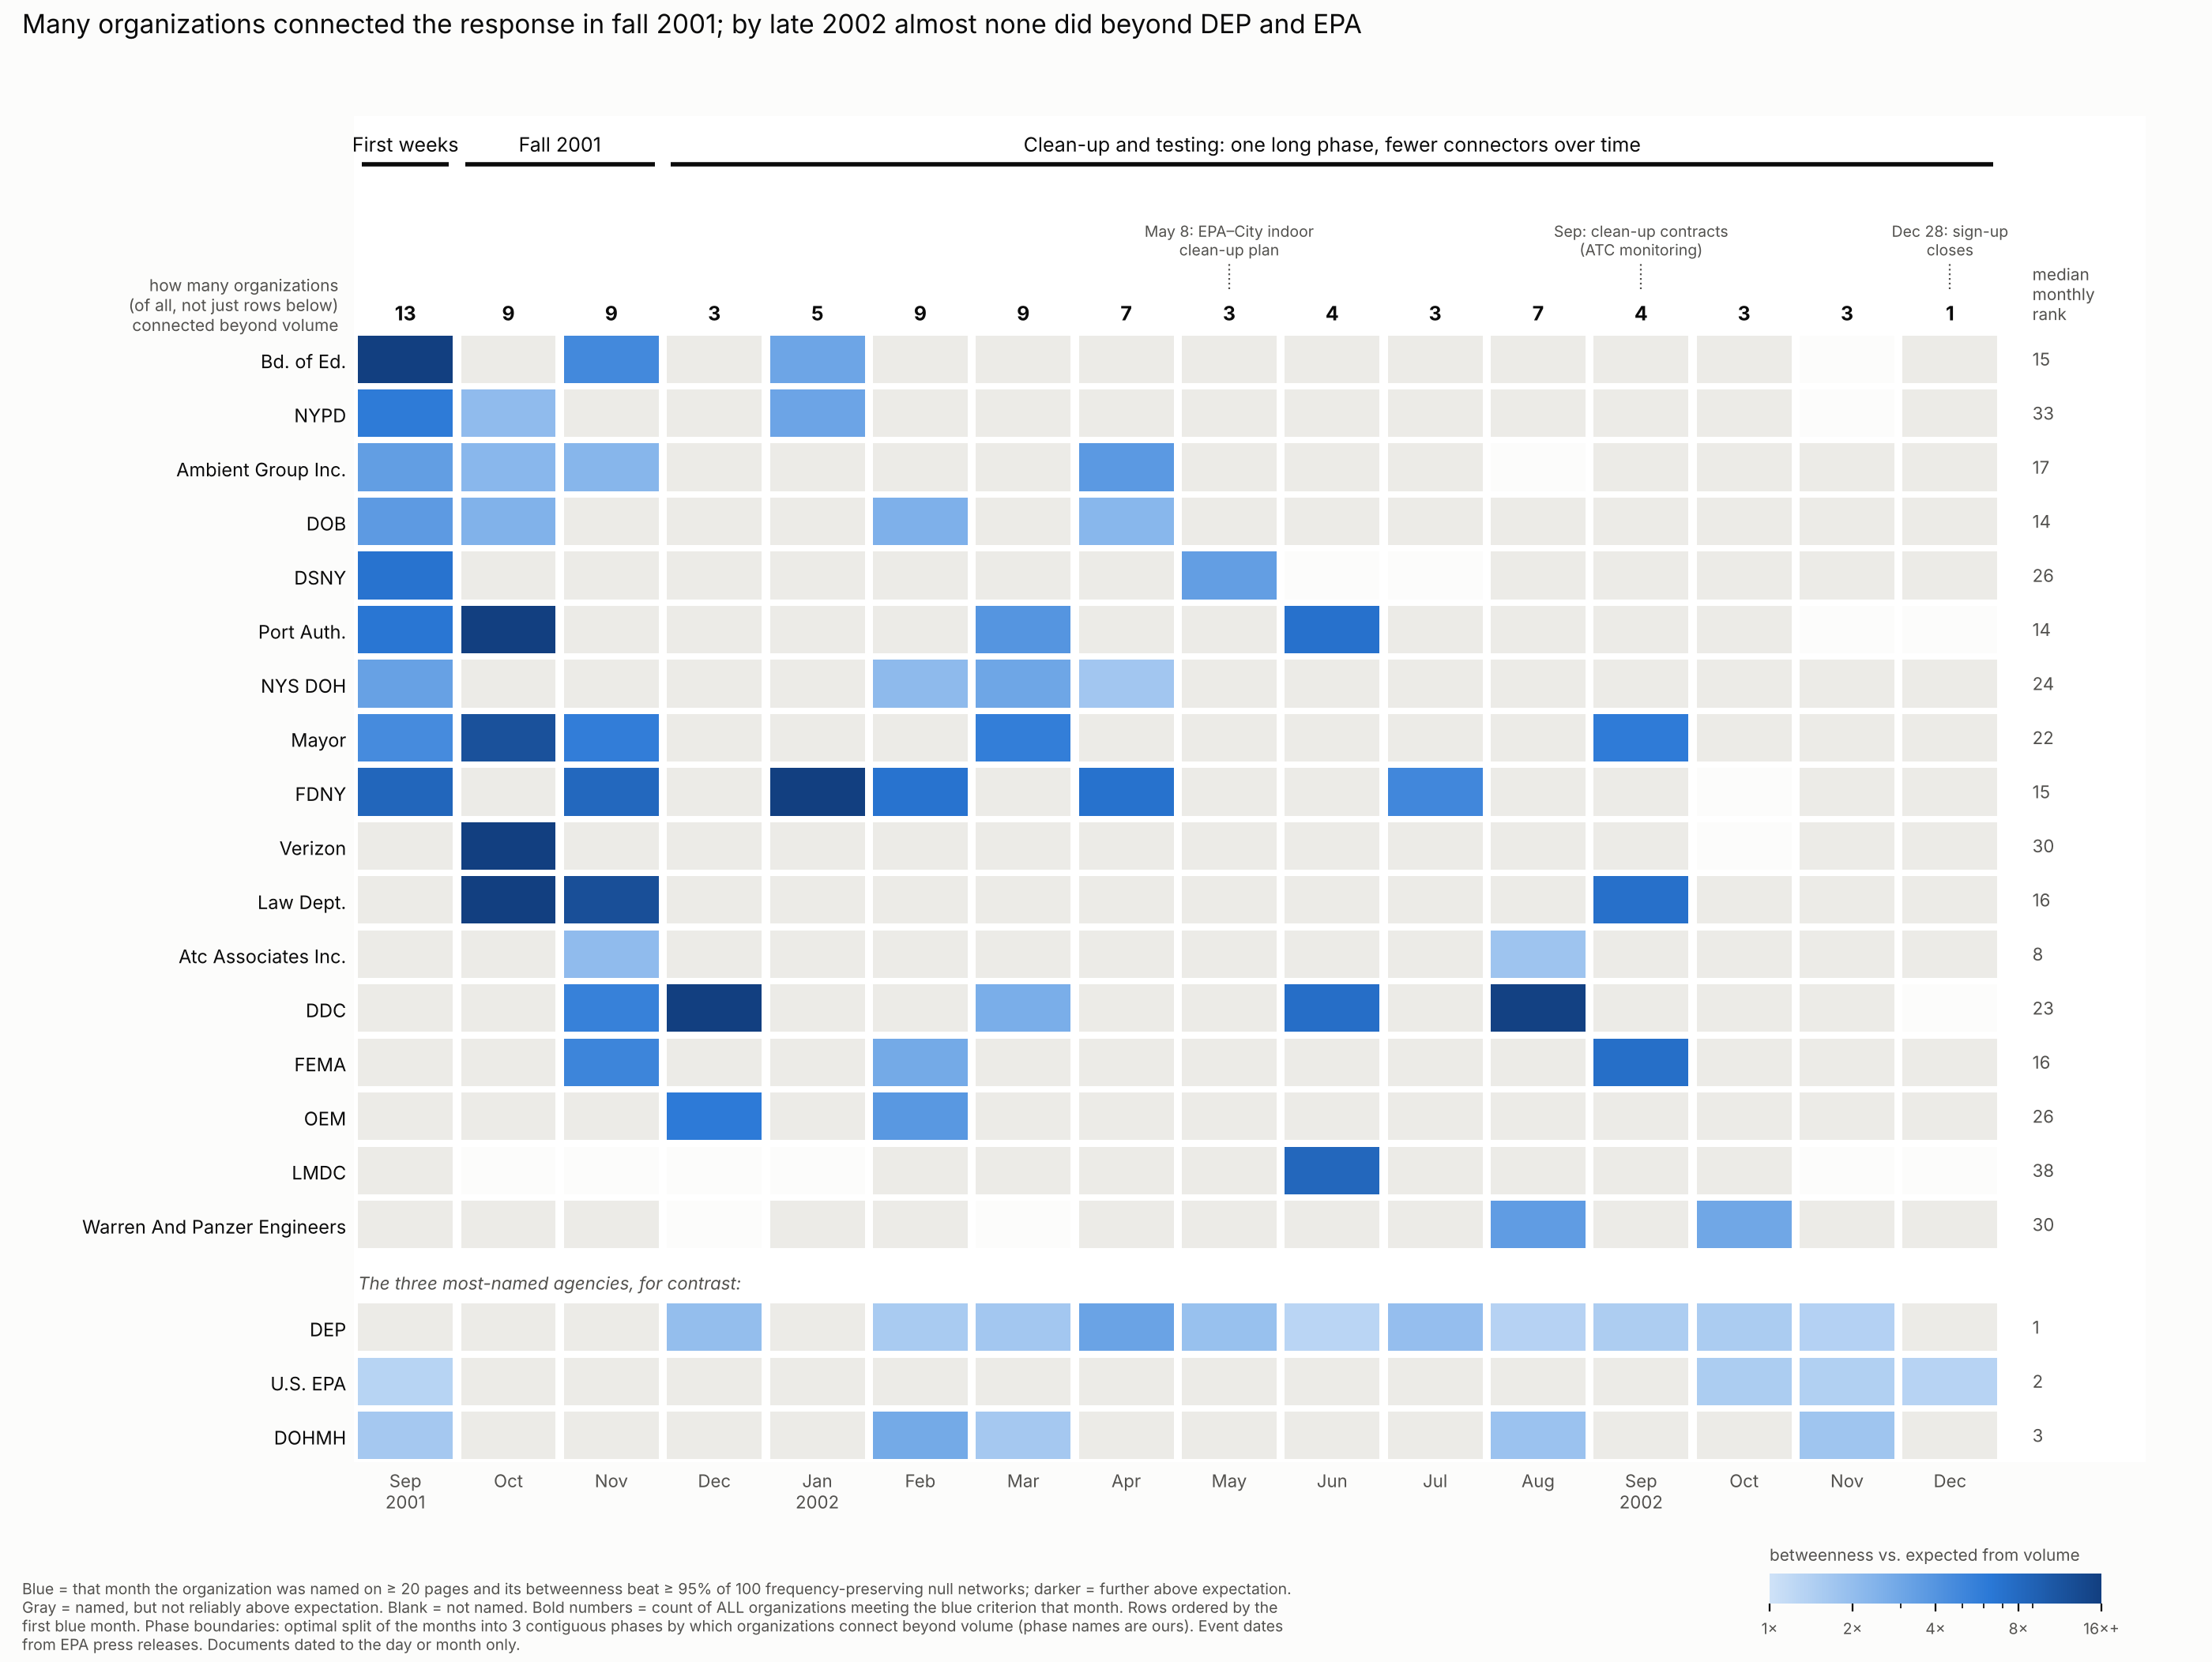

outputs/figures/network/fig7_bootstrap_betweenness_ranks.png


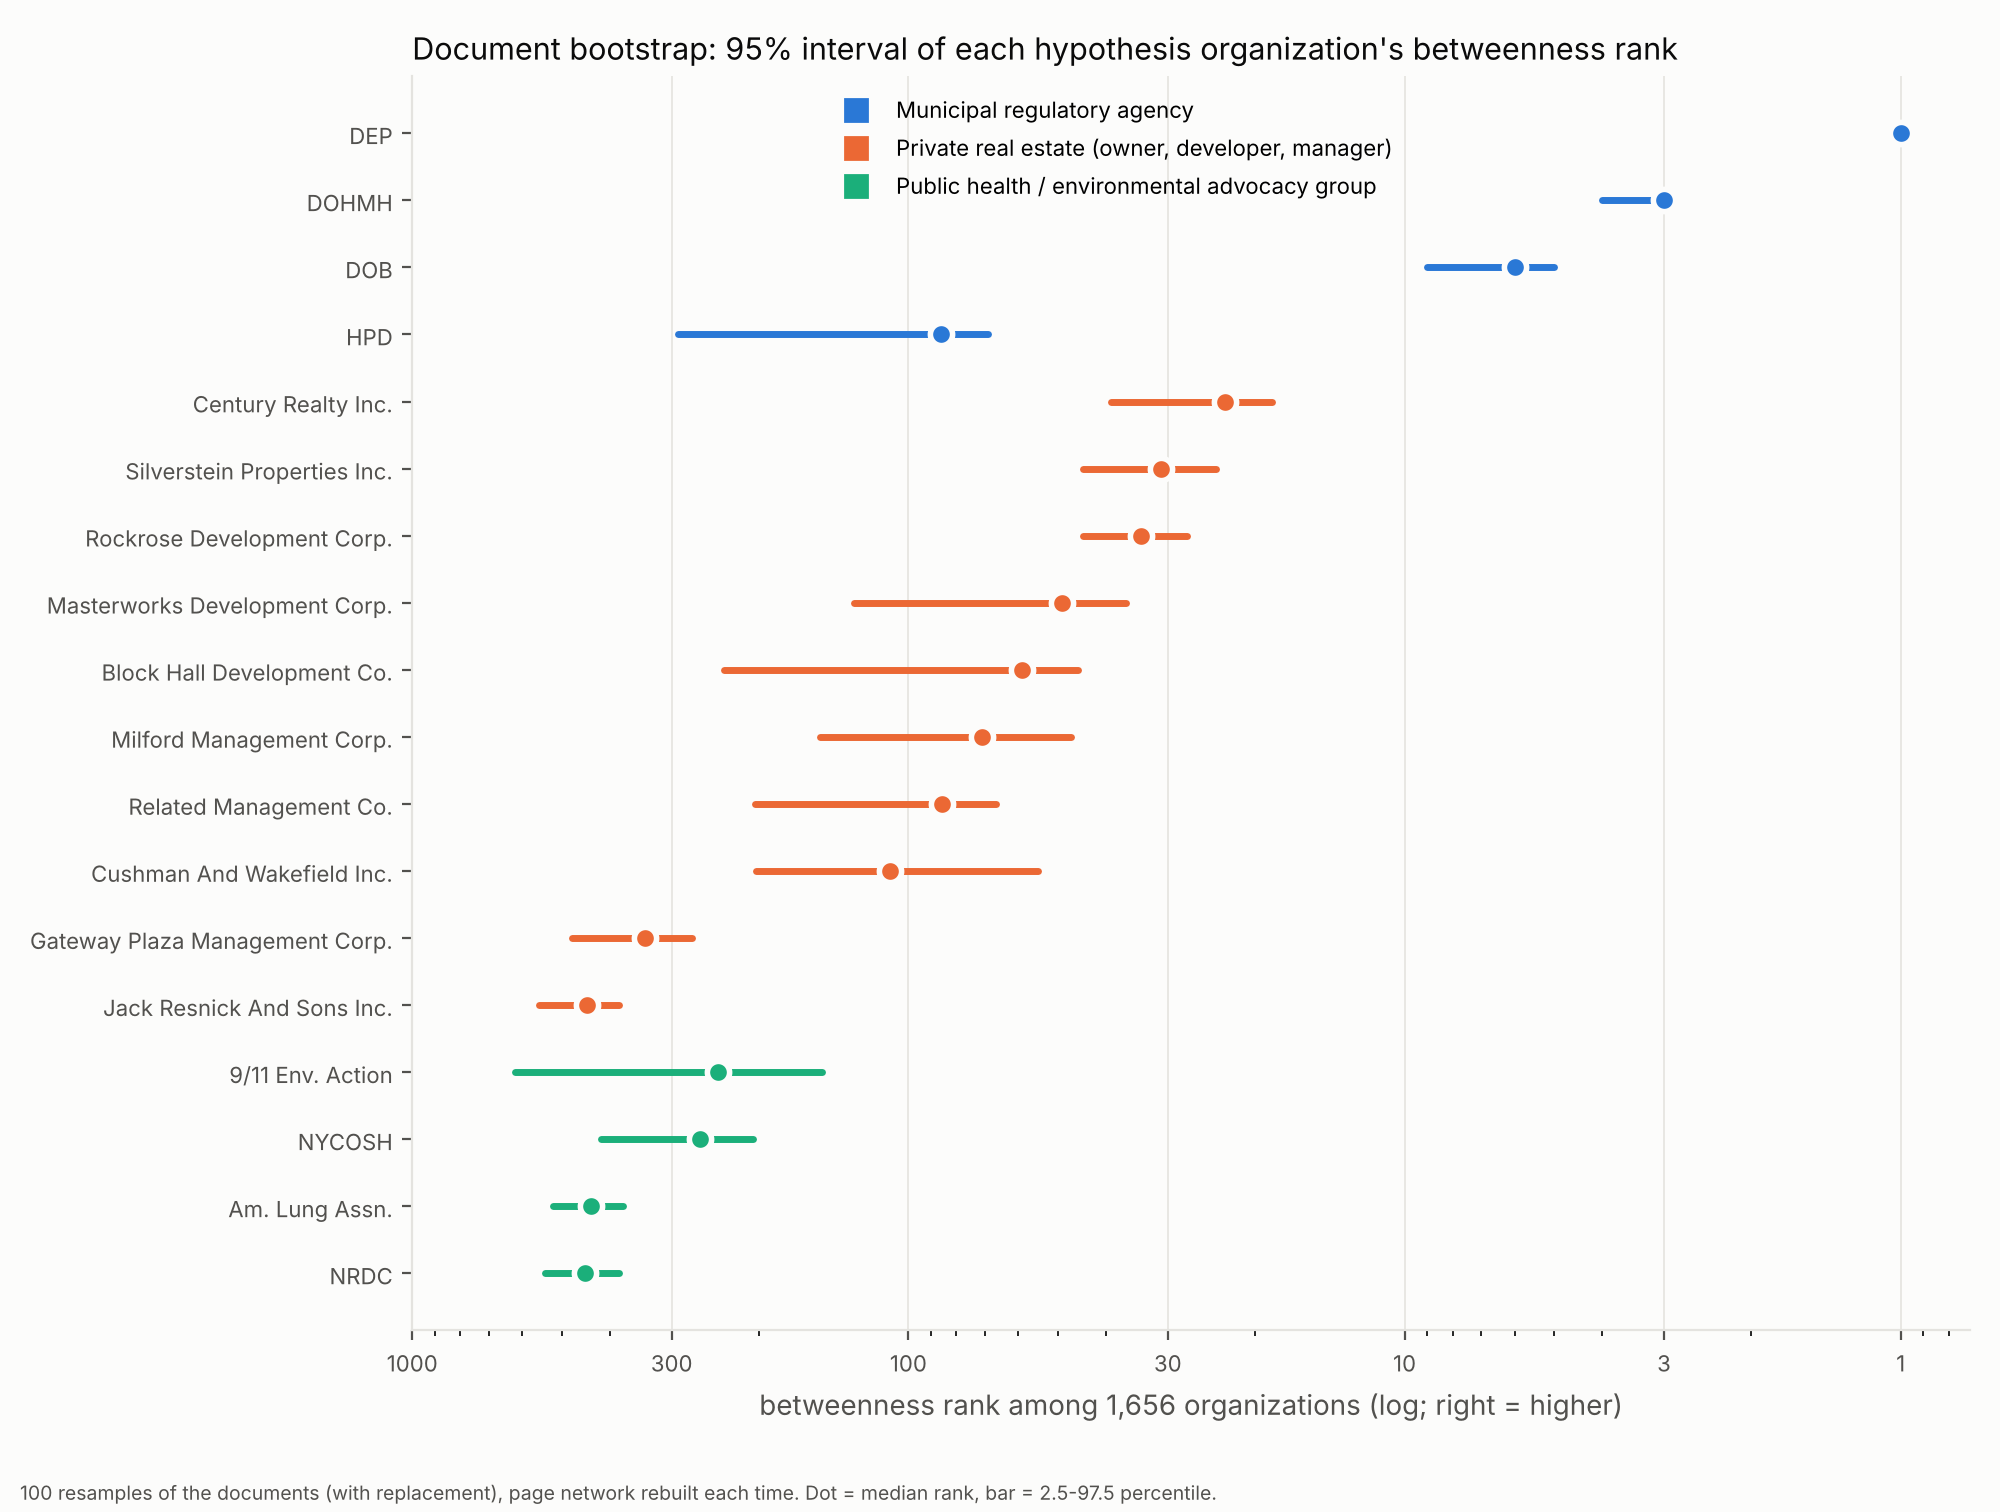

outputs/figures/network/fig8_raw_vs_adjusted.png


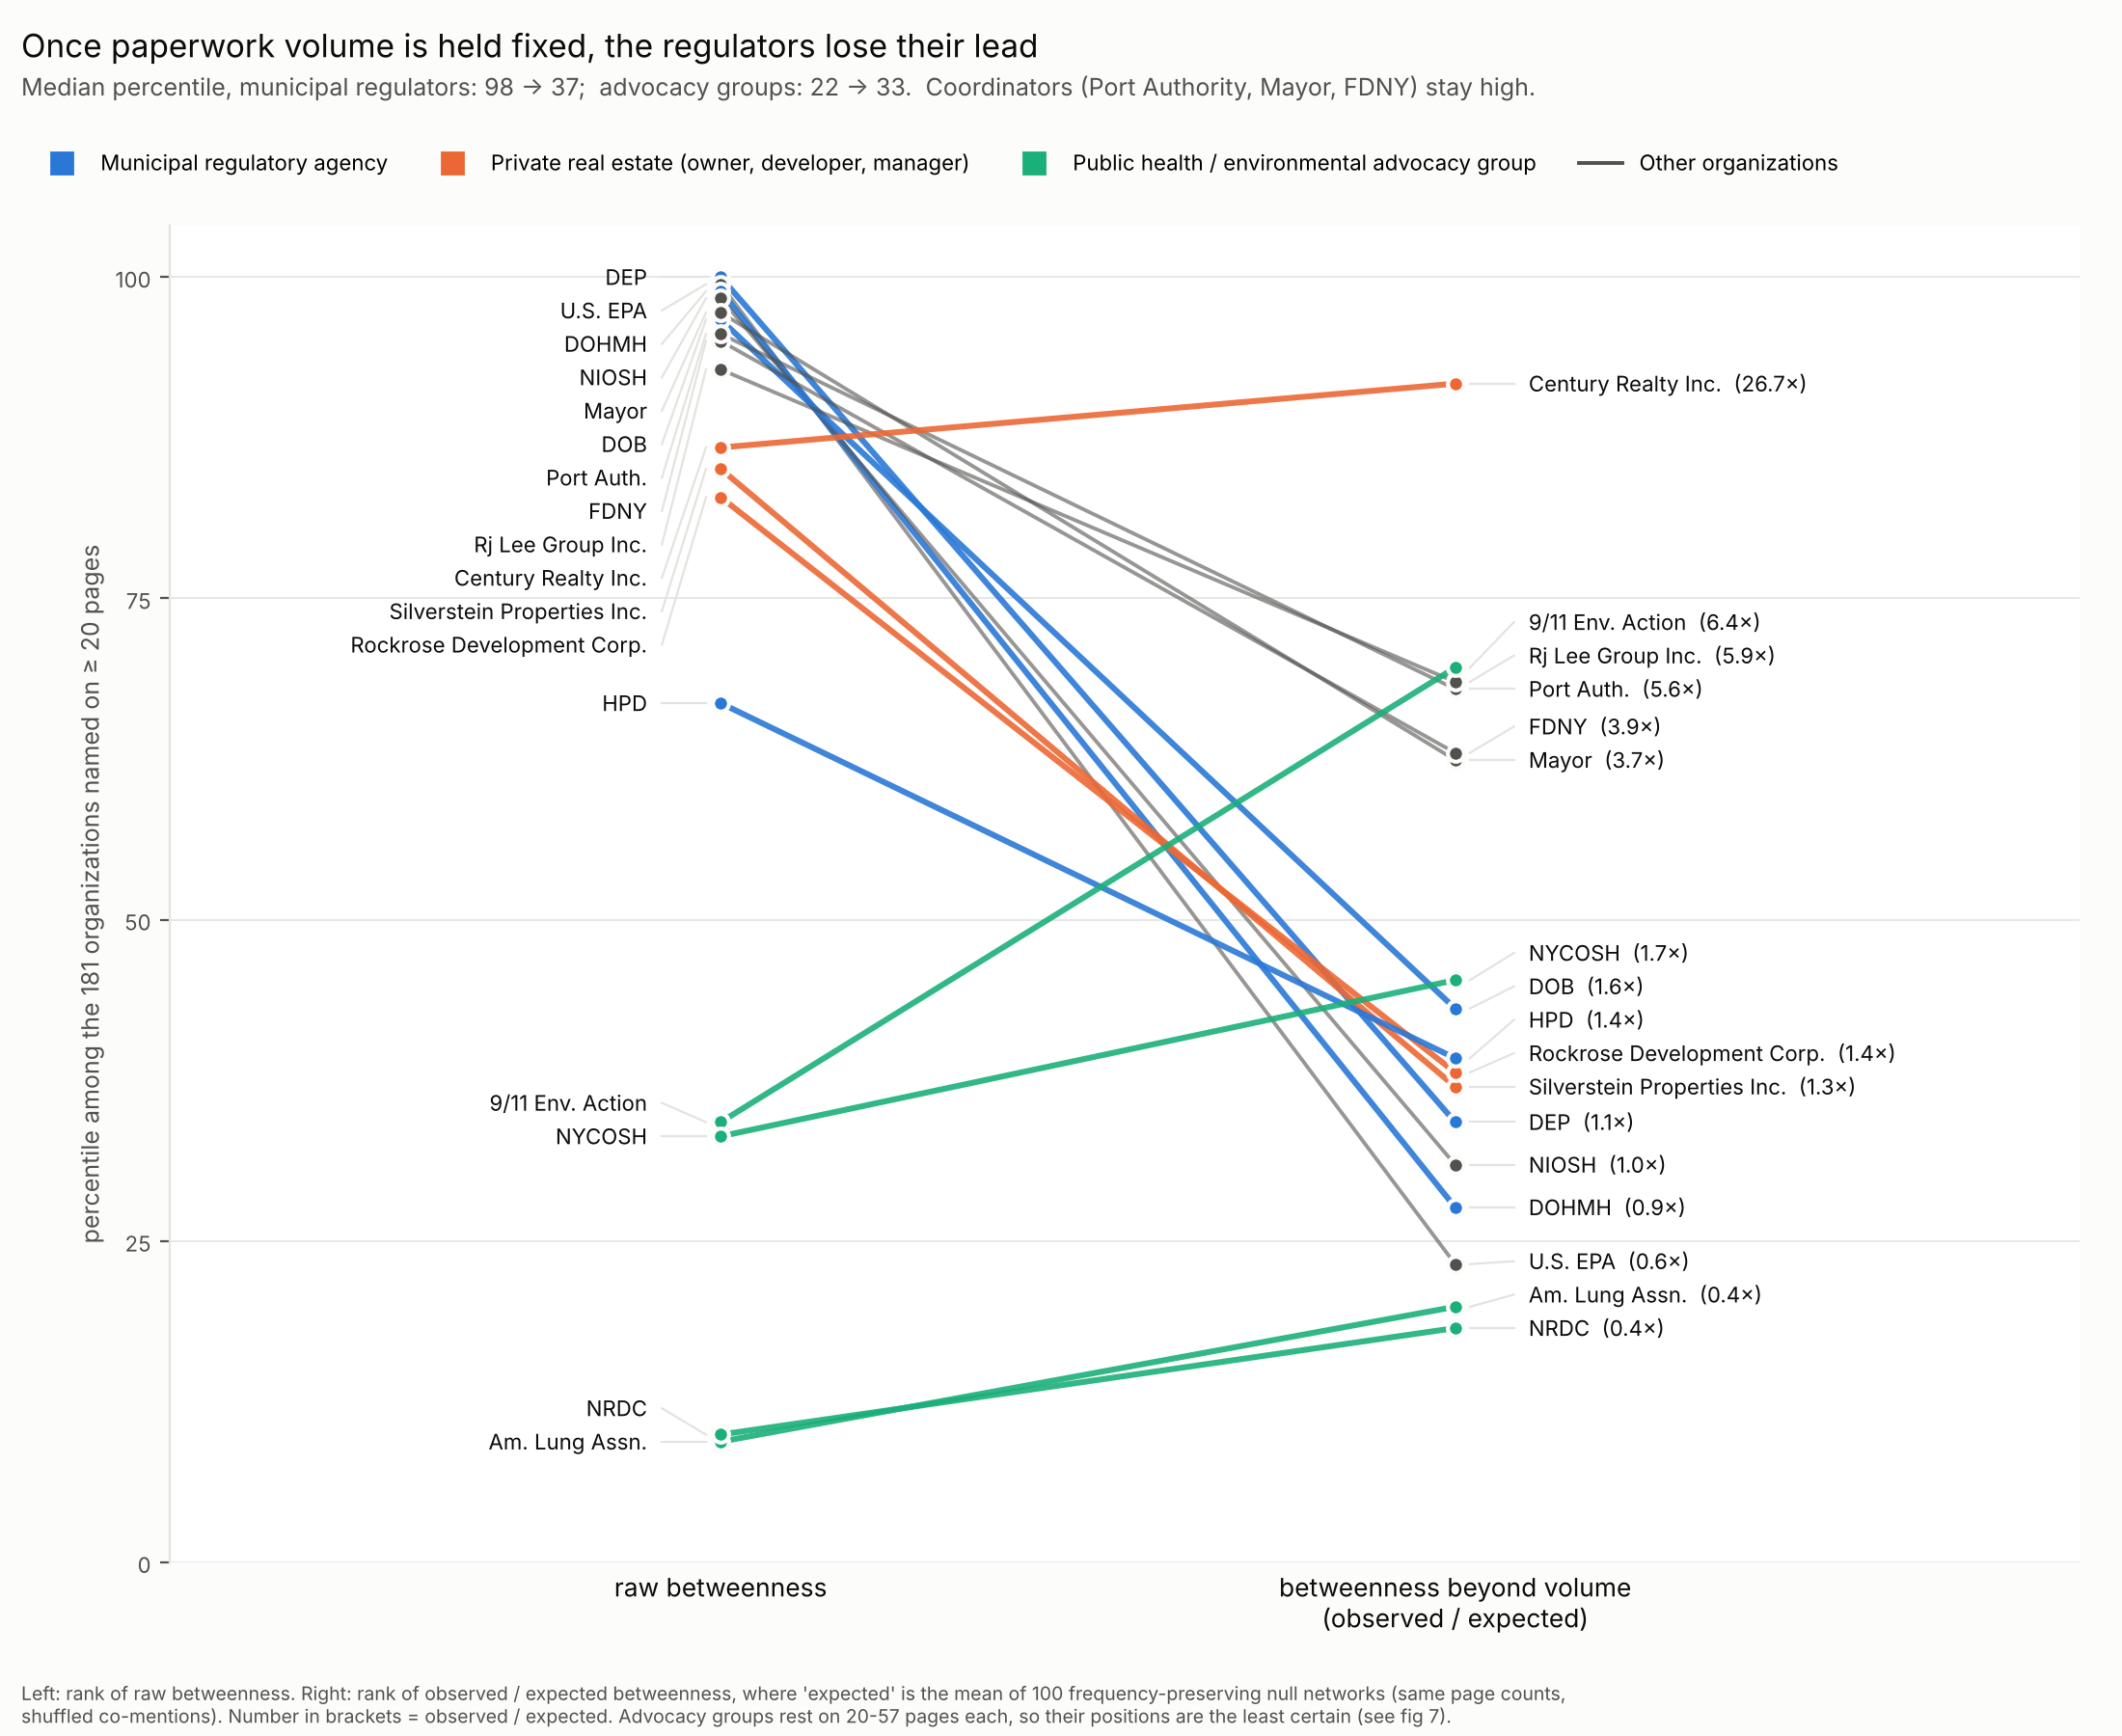

outputs/figures/network/fig9_whose_files.png


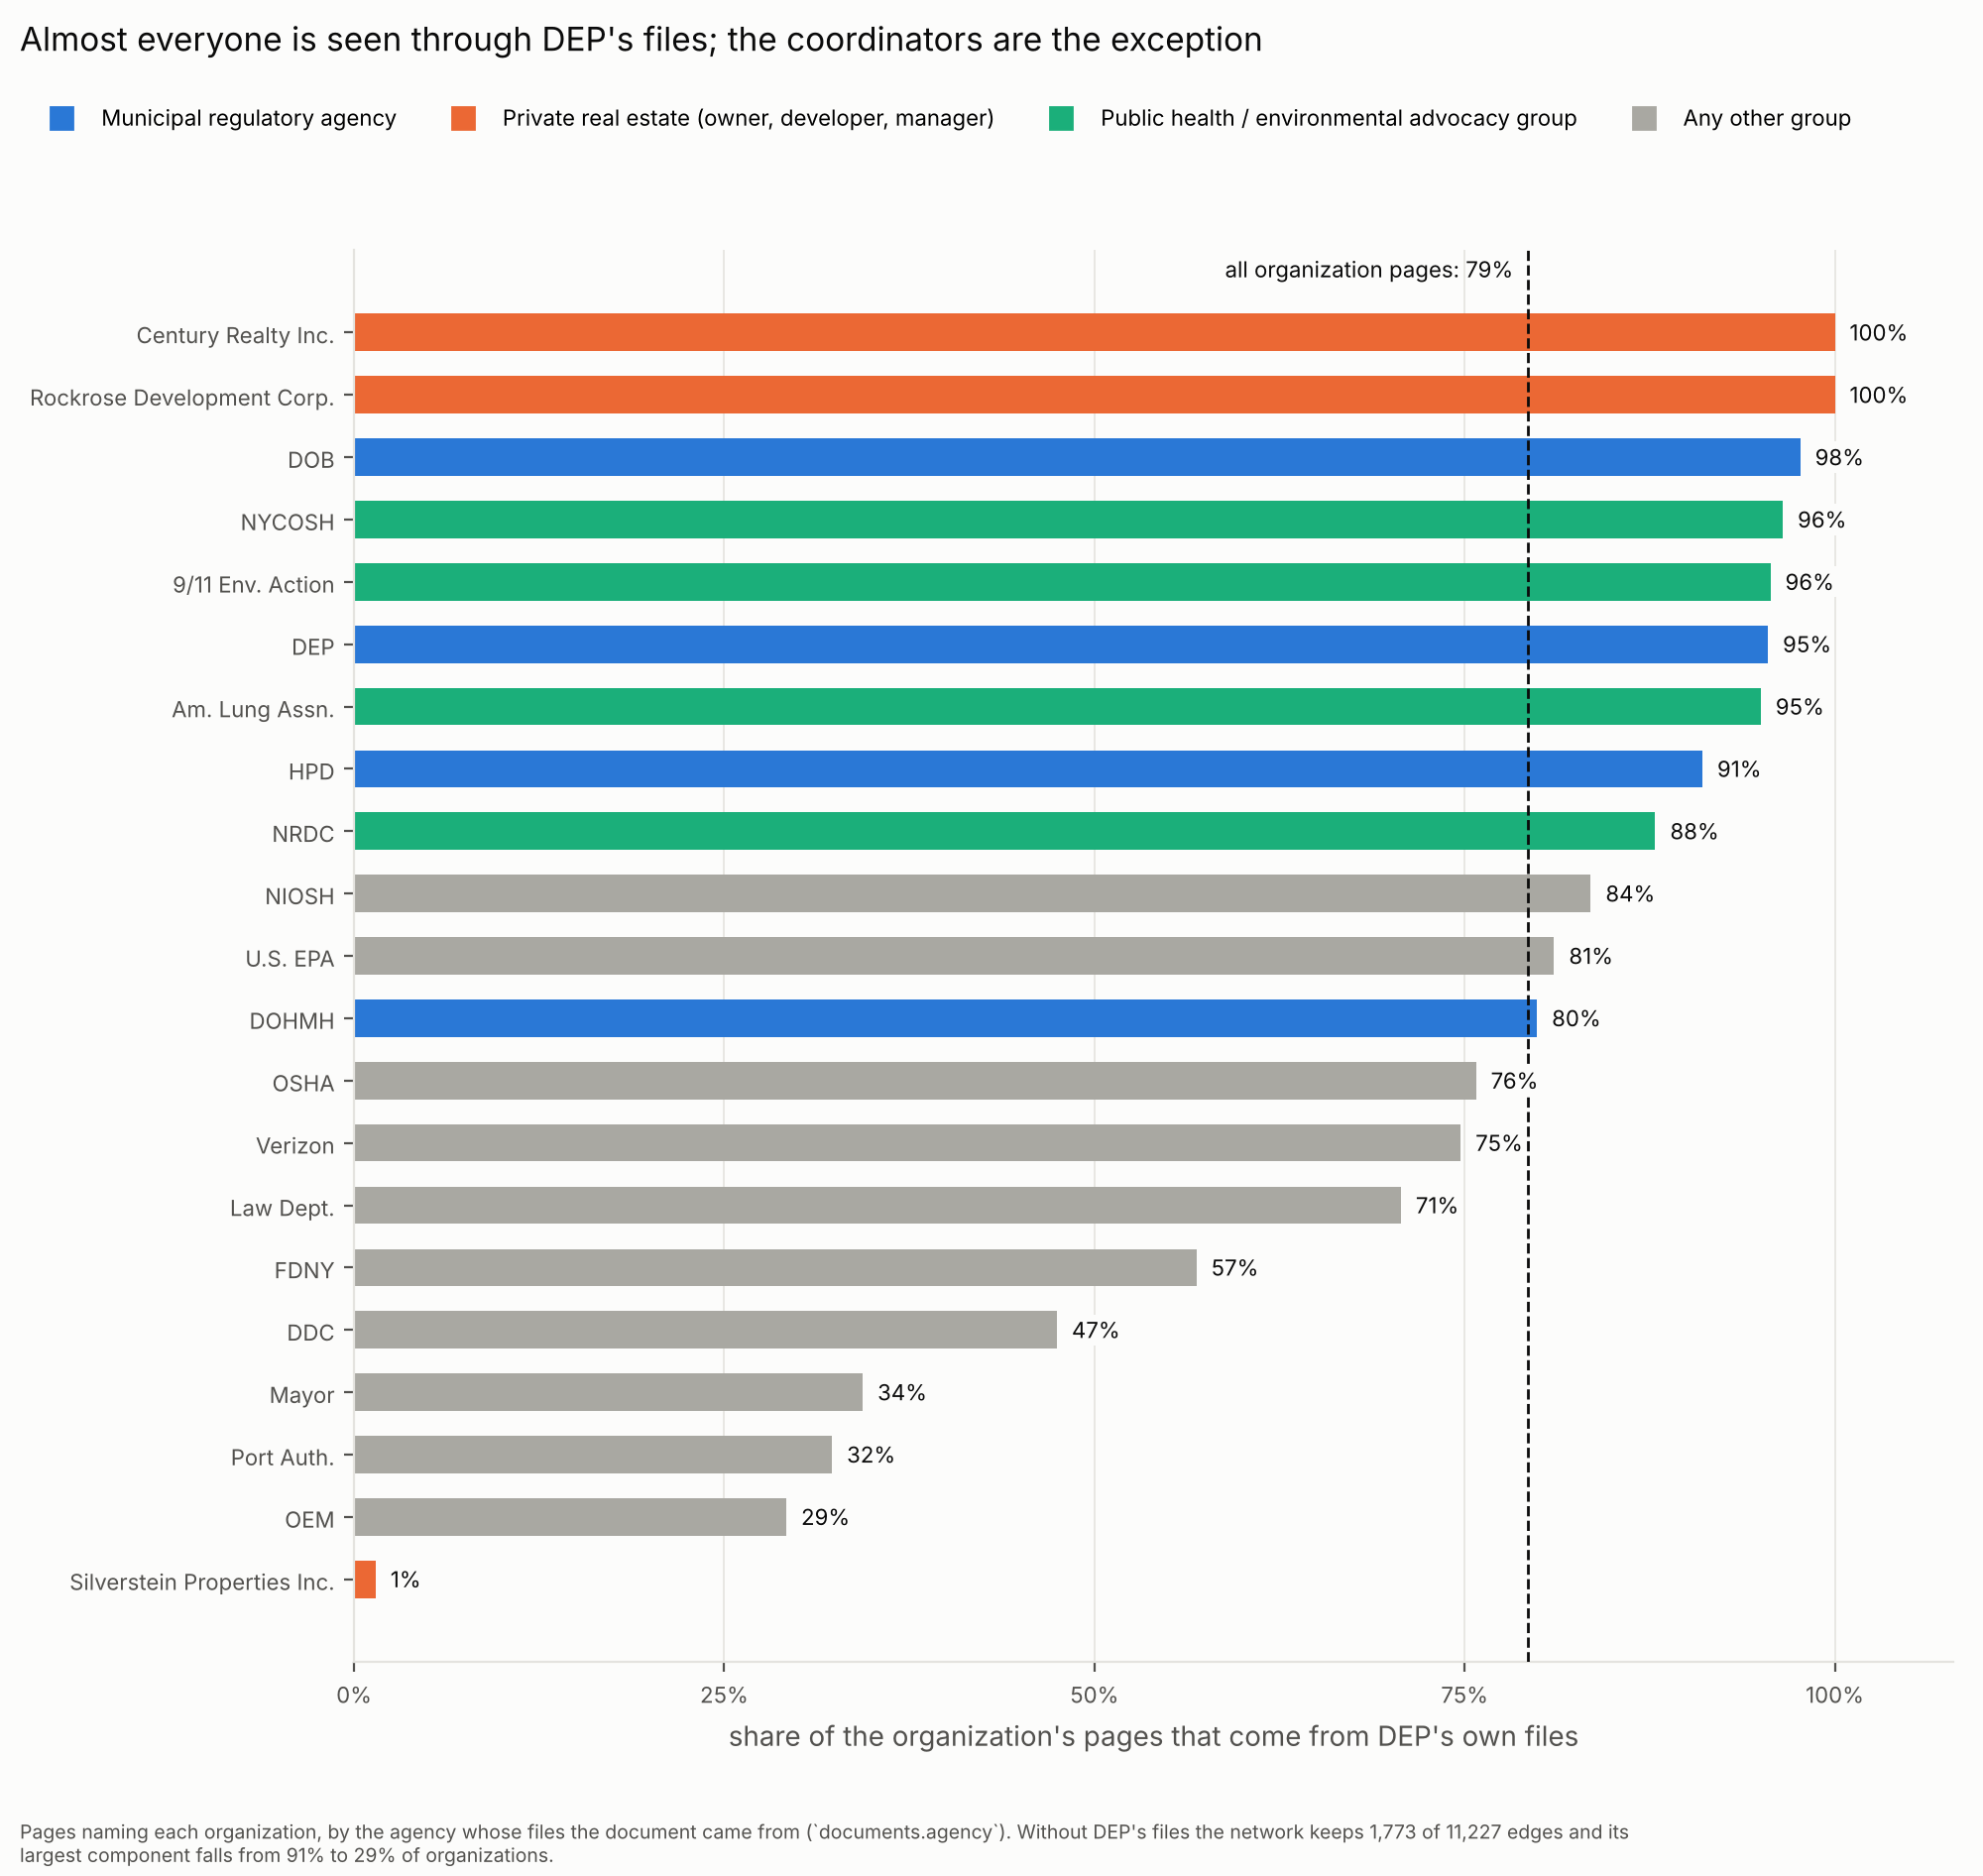

In [57]:
figures.top_ranking(main["nodes"])
figures.hypothesis_groups(hyp_nodes, scen[:2], ["all pages", f"without pages > {cutoff:.0f} orgs"])
lab = sup["nodes"]
label_ids = (set(lab.nlargest(4, "n_pages")["node_id"]) | set(lab.query("group == 'public_health_advocacy'")["node_id"])
             | set(lab.query("group == 'private_real_estate'").nlargest(3, "degree")["node_id"])
             | set(lab.query("group == 'municipal_regulatory'")["node_id"]))
figures.frequency_vs_degree(lab, label_ids)
figures.network_plot(sup)
for f in sorted(settings.FIGURES.glob("fig*.png")):
    print(f); display(Image(filename=str(f), width=900))

| Figure | Question it answers | What it cannot show |
|---|---|---|
| fig1 top centrality | Which organizations are most connected / most "between" in page co-occurrence? | Who communicated with whom, or who held power |
| fig2 hypothesis groups | Where does every node of the three hypothesis groups rank, with and without multi-organization pages, and for all vs hand-confirmed real estate? (study window and document network: tables only) | Significance; advocacy recall is not comparable; raw values (percentiles only) |
| fig3 frequency vs degree | Is centrality just how often a name appears? | Why an organization is named often |
| fig4 network subgraph | What the core of the co-occurrence structure looks like (30 agencies, 25 most-documented companies, 4 advocacy groups, edges ≥ 10 pages) | Geography or organizational distance (layout is arbitrary) |
| fig5 observed vs null | Is an organization more central than its mention volume predicts? | Why it is named with the partners it has |
| fig6 monthly relay | In which months did each organization connect the response beyond its paperwork volume, and how many organizations did so each month? | Who made decisions; months with few pages are excluded (< 20 pages), 20 null samples per month |
| fig7 bootstrap ranks | How much do the hypothesis organizations' ranks depend on which documents were released? | Significance (nodes are not independent) |
| fig8 raw vs adjusted | How does each organization's rank change once paperwork volume is held fixed? | Ranks among organizations named on ≥ 20 pages only |
| fig9 whose files | Whose files is each organization seen through? | Why an agency's files name an organization |
| fig10 backbone blocks | How is the response organized into functional blocks, and which blocks are tied? | Individual ties inside blocks; block names are our interpretation |


## 8. Verification

In [58]:
verify.check_toy()

1. toy graph: all metrics match hand-computed values


In [59]:
verify.check_beyond_frequency()   # 9. null model, backbone, bootstrap on toy inputs

9. null model, backbone and bootstrap: toy checks pass (degree sequences preserved, projection, hypergeometric p, hyperbolic weights, whole-document resampling, phase segmentation, ARI, consensus blocks)


In [60]:
run_outputs = settings.OUT / "nodes_main.csv"
if run_outputs.exists():
    nodes_out, edges_out = verify.check_outputs()
    verify.check_weights_from_raw(edges_out)
    verify.check_against_networkx_on_component(nodes_out, edges_out)
    verify.check_group_summaries()
    verify.check_window_filter()
    verify.check_pages_used_filter()
    # notebook results == saved tables used by the report
    saved = pd.read_csv(run_outputs).set_index("node_id")
    assert np.allclose(saved.loc[main["nodes"]["node_id"], "betweenness"], main["nodes"]["betweenness"])
    saved_sum = pd.read_csv(settings.OUT / "group_summary_by_scenario.csv")
    assert np.allclose(saved_sum["median"], summary["median"])
    print("notebook metrics and group summaries equal the saved tables in outputs/network/")
else:
    print("run `python -m src.analysis.network.run` to write the output tables, then re-run this cell")

2-3. 1652 nodes / 11166 edges: unique, ordered, no self-loops; evidence rows = sum C(k,2) = 99758; degree = edge count


4. 25 edge weights (10 heaviest + 15 random) match an independent recount from raw entity_mentions
5. agency-subgraph betweenness equals a direct networkx computation
6. baseline group medians match a direct recomputation; confirmed real estate = 10 nodes (subset of all 119); every scenario has the same nodes per group


7. study-window pages for 123 municipal / real-estate nodes match a recount from raw tables


8. n_pages_used under the page-size cut: toy (single-organization pages, isolates) correct; 127 hypothesis nodes match a recount from raw mentions
notebook metrics and group summaries equal the saved tables in outputs/network/


## 9. Summary: what we found, and what explains it

**1. The first finding.** In the archive's page co-occurrence network (1,652 organizations, 11,166 edges, 91% in one component) the city's regulators are at the top: DEP is first on degree (0.45) and betweenness (0.32), DOHMH third, and DEP, EPA and DOHMH are the top 3 in all four network variants. Read at face value, that supports Hypothesis 1: every regulator ranks above every one of the four advocacy groups in every variant, and the regulators' median rank is above the hand-confirmed real-estate firms'.

**2. The puzzle.** Centrality and volume move together (Spearman ρ 0.44 for degree, 0.56 for betweenness). DEP is named on 37% of all organization pages, and 62% of the documents come from DEP's own files. So is the top of the ranking *structural position* or *paperwork volume*? Sections 3–5 could not tell.

**3. The test (section 6a).** A frequency-preserving null model keeps every organization's page count and every page's size fixed and shuffles who appears with whom:
* **Degree is volume.** Every large agency has *fewer* partners than its volume predicts (DEP 0.58×, EPA 0.39×, DOHMH 0.43×). Their degree lead comes from being named often.
* **Betweenness separates real brokers from busy agencies.** DEP (1.13×) and DOB (1.63×) broker a little more than their volume predicts; EPA (0.64×), DOHMH (0.93×), NIOSH and OSHA do not. The organizations that broker *well* beyond volume are coordinators (Port Authority 5.6×, FDNY 3.9×, Mayor's Office 3.7×, NYPD, Sanitation), a utility (Verizon 10×) and testing / consulting firms (RJ Lee, Athenica, Pace).
* **Hypothesis 1, adjusted for volume:** the regulator-vs-advocacy gap on betweenness largely disappears (median observed/expected 1.28 vs 1.08; 1.00 vs 1.01 within each agency's files).

**4. Why: three explanations, each tested.**
* **Whose files were released (6d).** Without DEP's files the network falls apart (29% in one component), and the advocacy groups and most real-estate firms disappear: they are named almost only in DEP's records. H1 compares groups *inside DEP's view* of the response.
* **Who is connected at all (6c).** Only 21% of ties are more frequent than chance. **None** of the four advocacy groups has a single such tie under the strict test, and they have 6 in total under a looser one, against 13–38 for each regulator. They are present in the archive but barely co-mentioned with anyone beyond chance. That, not a lower rank, is the real contrast with the regulators.
* **When (6f).** Month by month, raw rank is frozen (DEP and EPA are #1–2 in all 16 months). Brokerage beyond volume changes and narrows: 13 organizations connect the response beyond their volume in September 2001 and 9 in October–November 2001, against 3–4 in most months of late 2002 and 1 in December 2002. The data place the main break at the end of 2001, and 2002 is one long phase, with a step down from May 2002 (EPA–City cleanup plan). The **Law Department climbs from betweenness rank 55 to 7–9** by late 2002. Its pages are mostly emergency-contract declarations (38% in its peak months), license agreements with building owners (14%) and document holds (10%), with only 3% legal correspondence, inquiries or claims. The lawyers moved toward the center through emergency contracting and clean-up paperwork, not litigation. ATC Associates' climb (rank 29 → 4) is volume: it produced up to 39% of a month's pages.

**5. How the network is organized (6g).** The validated backbone is strongly modular (0.60), and the consensus over 100 Louvain runs gives stable blocks. Their names are checked against the titles of their documents:
* building owners in DEP's exterior clean-up program;
* EPA + sampling laboratories;
* air monitoring (NIOSH, OSHA);
* WTC site operations and contracts (OEM, Mayor's Office, FDNY, Port Authority);
* asbestos abatement contractors;
* a city/state public-health hub (DEP, DOHMH, DOB, NYS DOH), through which 70 of the 114 ties between blocks run.

DEP and EPA are not the top of one hierarchy; they anchor different sub-systems.

**6. How sure (6e).** In a document bootstrap DEP (rank 1) and DOHMH (rank 3) never move, and "every regulator above every advocacy group" holds in 100% (degree) / 95% (betweenness) of resamples. "All real estate above advocacy" on betweenness holds in only 39%, so that version of H1 is not supported.

**Bottom line for Hypothesis 1.** The regulators' high centrality is real but mostly a matter of volume. Once volume and archive are held fixed, they do not broker more than the (rarely named) advocacy groups. The sharper and more defensible findings are that (a) advocacy groups are present but barely connected, (b) brokerage beyond volume belongs to coordinators, utilities and labs, and it narrows from many organizations in fall 2001 to a few in 2002, and (c) the archive is largely DEP's own view of the response.

**Why this matters beyond 9/11.** Studies of released government archives often read "named together often" as influence. This analysis shows that in a real archive most raw centrality is volume and release bias. Frequency-preserving nulls, edge validation and time slicing are cheap ways to separate structure from paperwork.

**Limits.** Co-occurrence on a page is not communication. Advocacy groups were found by a 4-name text search with different recall. The hypergeometric test has little power for near-ubiquitous nodes such as DEP (checked with a looser rule and an observed / expected ranking). Phase and block names are ours; their boundaries and members come from the data. Next steps: classify pages by type (letter vs list vs lab report) to separate document genre from position; link the Law Department's rise to the RQ3 liability-language series.

Full write-up of sections 1–5: `docs/network_analysis_report.md`.